# Análise - Vieses de veículos midiáticos

Nesse estudo, coletamos as opiniões de diferentes respondentes, contactados à partir de diferentes mídias sociais para indicar alguns de seus dados demográficos (região e idade) e de posicionamentos políticos e as opiniões dos respondentes sobre o posicionamento político de 25 populares veículos de mídia online em língua portuguesa.

##  O objetivo desse estudo é:
- Determinar se há alguma correlação entre os dados demográficos e as opiniões sobre as mídias
- Interpretar os resultados por quadrante político, pelas disparidades da visão das mídias
- Chegar a uma conclusão sobre o posicionamento final das mídias

## Passos à seguir para o desenvolvimento do estudo:
- [x] Import das bibliotecas de análise de dados
- [x] Limpeza dos dados do CSV inicial:
    - [x] Redeterminando a localização dos usuários para seguir um formato adequado
    - [x] Redefinir as idades para seguir o padrão int (eliminar entradas que sigam o padrão "X anos" e transformar em apenas "X")
    - [x] Redefinir as faixas etárias em limites de 5 em 5 anos
    - [x] Remover os dados de afiliação política que não são claros
    - [x] Remover entradas "não sei" e substituí-las por "None"
- [x] Redefinir as classificações entre direita, esquerda e centro em modo inteiros
- [x] Redefinir a filiação política de usuários cuja opinião não foi clara
    - [x] Escolher uma amostragem aleatória de usuários de direita, esquerda e centro
    - [x] Rodar um algoritmo de KNN para reclassificar tais usuários baseados nas opiniões sobre as mídias usando a notação quantitativa
    - [x] Guardar o resultado da nova planilha
- [ ] Análise de dados exploratória 
    - [x] Ver o julgamento de cada uma das mídias por espectro político e suas diferenças
    - [x] Ver o julgamento de cada uma das mídias por faixa de idade
    - [x] Ver o julgamento de cada uma das mídias por região

In [1]:
# Basics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.gridspec import GridSpec
from sklearn.neighbors import KNeighborsClassifier

enquete = pd.read_csv("enquete.csv")
RENAME = {
    "Carimbo de data/hora": "Timestamp",
    "Como você se considera politicamente?": "Politica",
    "Qual a sua idade?": "Idade",
    "Qual região e qual país você mora?": "Regiao",
    "Portal G1 (https://g1.globo.com)": "G1",
    "Folha de São Paulo (https://www.folha.uol.com.br)": "Folha",
    "Estadão (https://www.estadao.com.br)": "Estadao",
    "Jornal O Globo (https://oglobo.globo.com)": "Oglobo",
    "UOL (https://noticias.uol.com.br)": "UOL",
    "BBC News (https://www.bbc.com/portuguese)": "BBC",
    "CNN Brasil (https://www.cnnbrasil.com.br)": "CNN BR",
    "Agência Brasil de Comunicação (https://agenciabrasil.ebc.com.br)": "EBC",
    "Poder 360 (https://www.poder360.com.br)": "Poder360",
    "The Intercept (https://www.intercept.com.br)": "Intercept",
    "Jornal Metrópoles (https://www.metropoles.com)": "Metropoles",
    "Jovem Pan News (https://jovempan.com.br)": "JP",
    "Gazeta do Povo (https://www.gazetadopovo.com.br)": "Gazeta",
    "Jornal Valor Econômico (https://valor.globo.com)": "Valor",
    "Revista Exame (https://exame.com)": "Exame",
    "Bloomberg Brasil (https://www.bloomberglinea.com.br)": "Bloomberg",
    "Agência Pública (https://apublica.org)": "Apublica",
    "Deutsche Welle (https://www.dw.com/pt-br)": "DW",
    "Público PT (https://www.publico.pt)": "Publico",
    "RTP Notícias (https://www.rtp.pt/noticias)": "RTP",
    "Expresso (https://expresso.pt)": "Expresso",
    "Observador (https://observador.pt)": "Observador",
    "CNN Portugal (https://cnnportugal.iol.pt)": "CNN PT",
    "Correio da Manhã (https://www.cmjornal.pt)": "Correio",
    "Jornal Renascença (https://rr.pt)": "RR",
    "Notícias ao Minuto (https://www.noticiasaominuto.com)": "Aominuto"
}
enquete = enquete.rename(columns=RENAME)

---
# 1. Limpeza de Dados
Observamos que o CSV inicial continha algumas irregularidades e erros na formatação e um preprocessamento dos dados em formato de transformação se torna necessário para que a análise possa ser efetuada corretamente.

## Passos à seguir:
### Redeterminar localização dos usuários
Os respondentes responderam a pergunta, mas os dados acabaram sem seguir exatamente um formato aceitável para que a análise possa ser feita, os tratamentos para corrigir esse problema é simples e envolvem apenas mudanças diretas.
- Cidades e estados do Brasil serão ressignificadas diretamente como "Brasil (Região)" baseado no que estiver presente na base de dados
- Respondentes em Portugal serão todos apenas mudados para "Portugal", igualmente para aqueles em Angola
- Demais localizações válidas serão ressignificadas ao nível do continente (ex: Paris -> "Europa")
- Localizações inválidas serão ressignificadas para None

### Redefinir as idades para um padrão de inteiros
Muitos respondentes usaram o formato "X anos" para referir-se à suas idades, a correção para esses problemas é direta, remoção da parte " anos" da string, transoformação dos demais valores da coluna em None e mudança da coluna para formato Int.
Após isso, redefinir as idades em intervalos de 5 em 5 anos, ordenando-os do valor mais baixo como 0 até o valor mais alto possível

### Remoção de dados de afiliação política não-claros
Alguns respondentes não se declararam de "Centro", "Direita" e "Esquerda", sendo esse o espectro da análise, detalhando um pouco mais sua posição (por exemplo: Centro-esquerda, centro-direita, patriota, etc). Essas classificações, por mais que nos deem uma ideia, não são claras para o viés da análise. O seguinte approach será usado para redifinição momentânea desses usuários.
- Linhas que se declaram nos seguintes perfís: Esquerda Radical, Comunista, Socialista e Social-Democrata serão reclassificados diretamente como "Esquerda"
- Linhas que se declaram nos seguintes perfís: Conservador, Libertário e Bolsonarista serão reclassificados diretamente como "Direita"
- Linhas que se declaram nos seguintes perfís: Apartidário e Terceira Via serão reclassificados diretamente como "Centro"
- As demais linhas serão consideradas como None.

### Remoção de entradas "não sei"
Respostas "não sei" sobre o posicionamento das mídias serão substituidas por None para toda a tabela para facilitar a quantificação da análise

In [2]:
# Localizacao de respostas
col = "Regiao"
s = (enquete[col].str.normalize("NFKD")
     .str.encode("ascii", "ignore").str.decode("ascii")  # Removendo acentos
     .str.lower().str.strip())

# regex gerado por IA
steps = [
    (r"^.*(?:portugal|lisboa|porto).*$", "Portugal"),
    (r"^.*angola.*$", "Angola"),
    (r"^.*(?:centro[ -]?oeste|\bdf\b|brasilia|cuiaba|goias|mato grosso).*$", "Brasil (Centro-Oeste)"),
    (r"^.*(?:nordeste|\bne\b|recife|pernambuco|\bpe\b|bahia|\bba\b|ceara|maranhao|paraiba|alagoas|sergipe|piaui).*$", "Brasil (Nordeste)"),
    (r"^.*(?:sudeste|sao paulo|\bsp\b|rio de janeiro|\brj\b|minas gerais|\bmg\b|espirito santo).*$", "Brasil (Sudeste)"),
    (r"^.*(?:(?<!do )\bsul\b|parana|santa catarina|rio grande do sul|\bpr\b|\bsc\b|\brs\b).*$", "Brasil (Sul)"),
    (r"^.*(?:(?<!de )\bnorte\b|amazonas|\bpa\b|manaus|belem|acre|rondonia|roraima|tocantins|amapa).*$", "Brasil (Norte)"),
    (r"^.*(?:america do sul|argentina|chile|uruguai|colombia|peru|bolivia|paraguai|venezuela).*$", "América do Sul"),
    (r"^.*(?:franca|france|polonia|alemanha|espanha|italia|europa|paris).*$", "Europa"),
    (r"^.*(?:malasia|japao|china|india|asia).*$", "Ásia"),
]
for pat, rep in steps:
    s = s.str.replace(pat, rep, regex=True)

labels = [rep for _, rep in steps]
enquete["Regiao"] = s.where(s.isin(labels), None)

In [3]:
# Idade das respostas
col = "Idade"
s = (enquete[col].str.normalize("NFKD")
     .str.encode("ascii", "ignore").str.decode("ascii")  # Removendo acentos
     .str.lower().str.strip())

s = s.str.replace(' anos', '')
s = pd.to_numeric(s, errors='coerce')
enquete["Idade"] = s

In [4]:
# Opinioes Politicas
col = "Politica"
s = (enquete[col].str.normalize("NFKD")
     .str.encode("ascii", "ignore").str.decode("ascii")  # Removendo acentos
     .str.lower().str.strip())

# Regex gerado por IA
steps = [
    (r"^(?:esquerda radical|comunista|socialista|social[- ]?democrata|marxista)$", "Esquerda"),
    (r"^(?!.*(?:centro|direita)).*esquerda.*$", "Esquerda"),
    (r"^(?:conservador|libertario|bolsonarista)$", "Direita"),
    (r"^(?!.*(?:centro|esquerda)).*direita.*$", "Direita"),
    (r"^(?:apartidario|terceira via)$", "Centro"),
    (r"^(?!.*(?:esquerda|direita)).*centro.*$", "Centro"),
]
for pat, rep in steps:
    s = s.str.replace(pat, rep, regex=True)

enquete["Politica"] = s.where(s.isin(["Direita", "Esquerda", "Centro"]), None)

In [5]:
# Remocao de Nao Sei
enquete = enquete.replace("Não sei", None)

----
# 2. Reclassificar respondentes não-claros

Para implementar um algoritmo de reclassificação de respondentes cujo alinhamento político não ficou claro, um approach de reclassificação foi levado em conta, seguindo os seguintes passos

- Quantificação de direita e esquerda em uma análise binária
    - Direita = 1
    - Centro = 0
    - Esquerda = -1
- Utilização do resultado médio para cada um dos None presentes
- Escolha de 6 a 9 membros de cada um dos espectros políticos de modo aleatório
- Redefinição do posicionamento político dos faltantes à partir de um KNN onde N=5 N=7
- Utilização do valor que parece mais coerente


In [6]:
# Quantificando e salvando em novo DataFrame
cols = ['G1', 'Folha', 'Estadao', 'Oglobo', 'UOL', 'BBC', 'CNN BR', 'EBC', 'Poder360',
        'Intercept', 'Metropoles', 'JP', 'Gazeta', 'Valor', 'Exame', 'Bloomberg',
        'Apublica', 'DW', 'Publico', 'RTP', 'Expresso', 'Observador', 'CNN PT',
        'Correio', 'RR', 'Aominuto']

enq_copy = {}

for col in cols:
    s = enquete[col]
    s = s.str.replace("Esquerda", "-1")
    s = s.str.replace("Centro", "0")
    s = s.str.replace("Direita", "1")
    s = pd.to_numeric(s.where(s.isin(["-1", "0", "1"]), None), errors='coerce')
    s = s.where(s.isin([-1, 0, 1]), s.mean())
    enq_copy[col] = s

enq_copy = pd.DataFrame(enq_copy)

# Nomes completos das midias (sem a URL), para os titulos dos gráficos
full_names = {v: k.split(" (")[0] for k, v in RENAME.items() if v in cols}
    

In [7]:
def escolha_aleatoria(sample_size):
    # Escolha aleatoria de membros
    s_esq_index = enquete[enquete["Politica"] == "Esquerda"].sample(n=sample_size).index
    s_dir_index = enquete[enquete["Politica"] == "Direita"].sample(n=sample_size).index
    s_cen_index = enquete[enquete["Politica"] == "Centro"].sample(n=sample_size).index

    s_esq = enq_copy.iloc[s_esq_index]
    s_dir = enq_copy.iloc[s_dir_index]
    s_cen = enq_copy.iloc[s_cen_index]

    # Transformacao em modelo knn
    data = pd.concat([s_esq, s_dir, s_cen])
    classes = [c for c in ["Esquerda", "Direita", "Centro"] for _ in range(sample_size)]

    return data, classes

def previsao_knn(vizinhos, data, classes, x_missing):
    # Implementacao KNN
    knn = KNeighborsClassifier(n_neighbors=vizinhos)
    knn.fit(data, classes)

    predictions = knn.predict(x_missing)

    # Reclassificacao no DataFrame principal
    return predictions

In [8]:
# Rodar o algoritmo 100 vezes, pegar os resultados e comparar
k_neighbors = [5, 7, 9, 11, 13]
sample_size = [5, 7, 9, 11, 13]

# Pegando dados faltando classificar
missing_points_index = enquete[enquete["Politica"].isna()].index
X_missing = enq_copy.loc[missing_points_index]

# Preparando espaco para escritura
records = []
for k in k_neighbors:
    for n in sample_size:
        for run in range(100):
            data, classes = escolha_aleatoria(n)
            preds = previsao_knn(k, data, classes, X_missing)
            records.append(pd.DataFrame({
                "k": k,
                "sample_size": n,
                "run": run,
                "member": X_missing.index,
                "predicted": preds,
            }))

results_knn = pd.concat(records, ignore_index=True)


In [9]:
# Checar quais classes por configuração e por membro
dist = (results_knn.groupby(["k", "sample_size", "member"])["predicted"]
               .value_counts(normalize=True)
               .unstack(fill_value=0))

# Consistencia: quanto mais frequente a classe mais comum ganha por membro
consistency = (results_knn.groupby(["k", "sample_size", "member"])["predicted"]
                      .agg(lambda s: s.value_counts(normalize=True).iloc[0]))

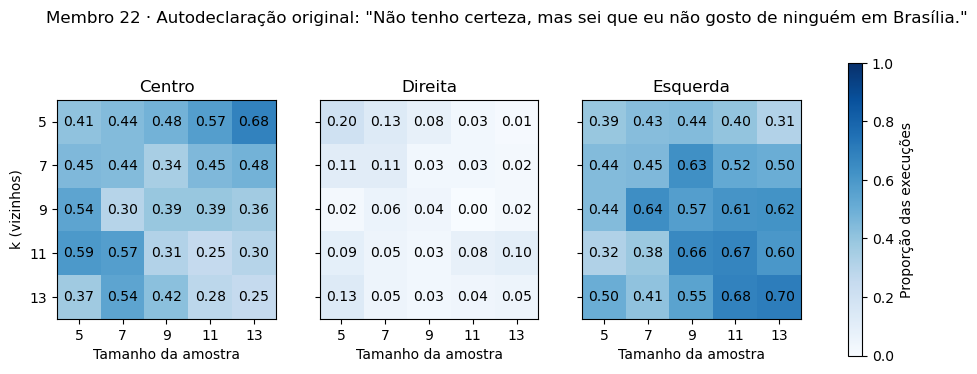

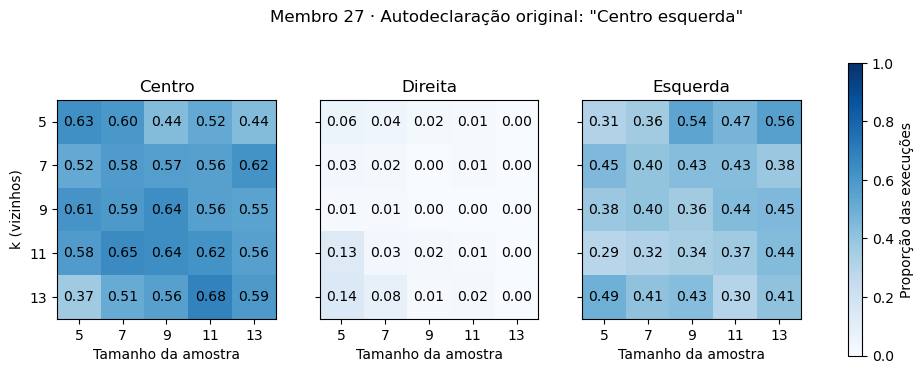

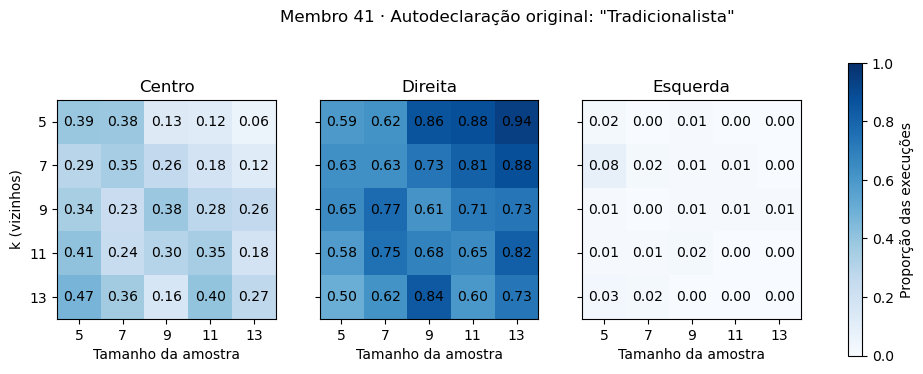

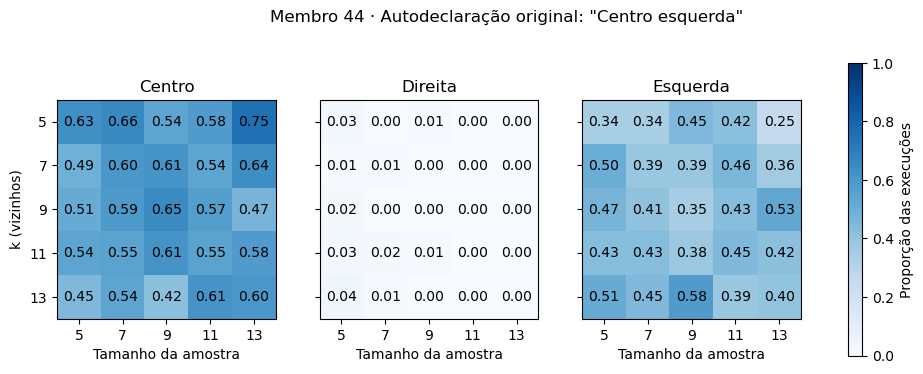

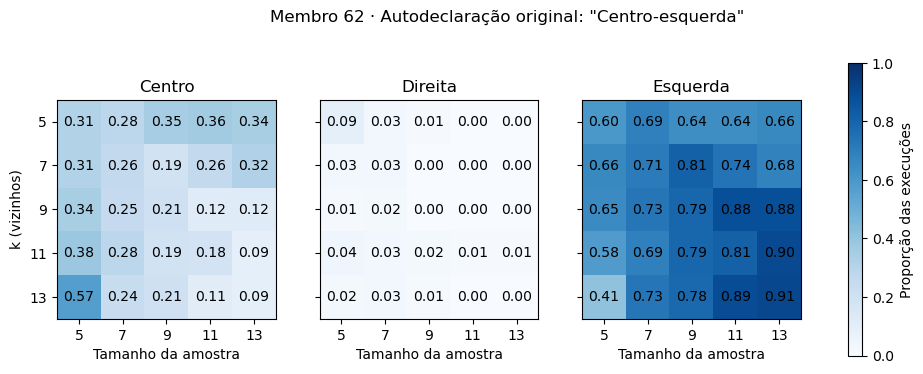

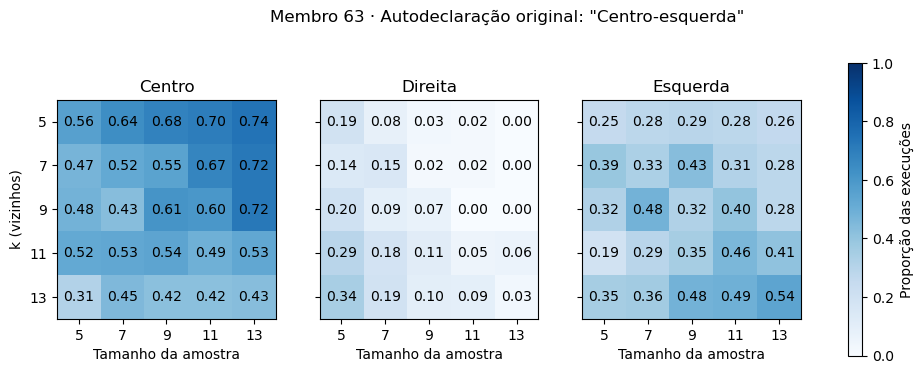

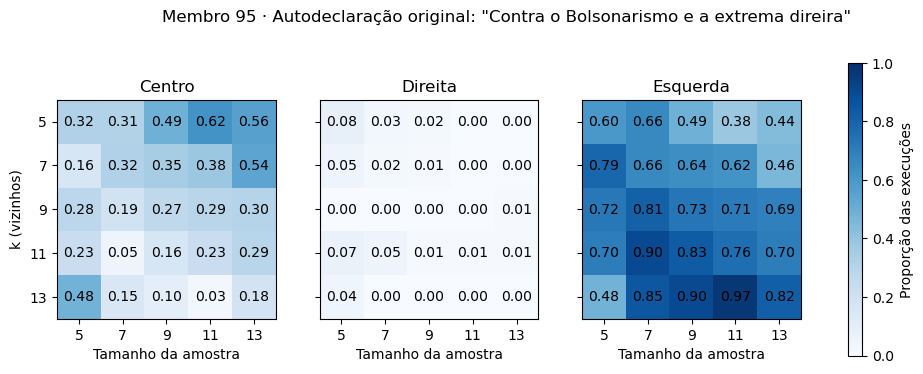

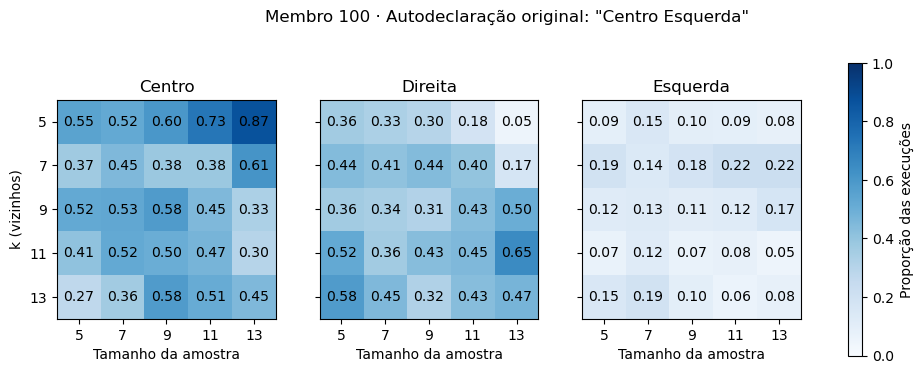

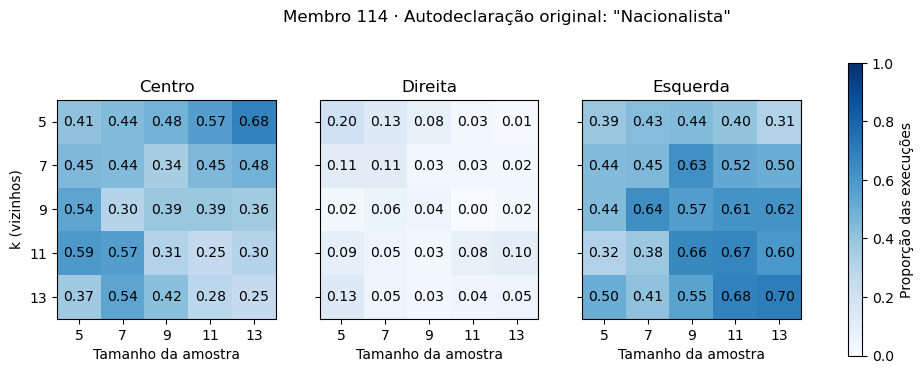

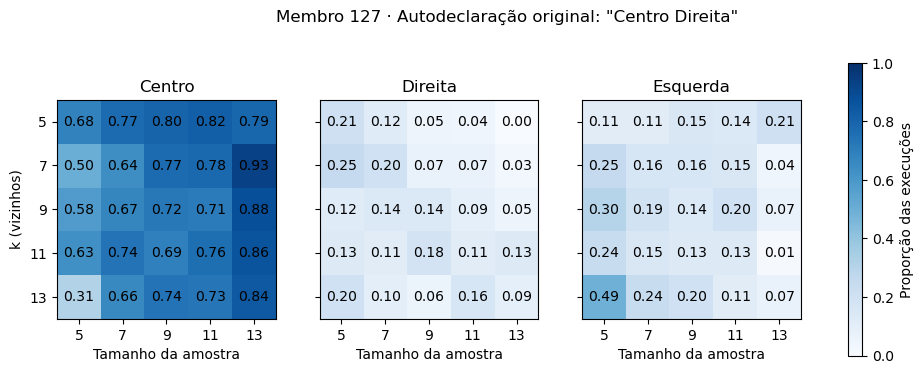

In [10]:
# Visualizacao sugerida por IA

# Resposta original (texto bruto do CSV), alinhada ao indice do enquete
col_raw = "Como você se considera politicamente?"
raw = pd.read_csv("enquete.csv")
claim = lambda m: str(raw.loc[m, col_raw]).strip()

def plot_class_shares(member):
    sub = dist.xs(member, level="member")  # índice: (k, sample_size), colunas: classes
    fig, axes = plt.subplots(1, len(sub.columns), figsize=(12, 3.8), sharey=True)
    for ax, cls in zip(axes, sub.columns):
        grid = sub[cls].unstack("sample_size")  # linhas: k, colunas: sample_size
        im = ax.imshow(grid.values, vmin=0, vmax=1, cmap="Blues")
        ax.set_title(cls)
        ax.set_xticks(range(grid.shape[1]), grid.columns)
        ax.set_yticks(range(grid.shape[0]), grid.index)
        ax.set_xlabel("Tamanho da amostra")
        for i in range(grid.shape[0]):
            for j in range(grid.shape[1]):
                ax.text(j, i, f"{grid.values[i, j]:.2f}", ha="center", va="center")
    axes[0].set_ylabel("k (vizinhos)")
    fig.colorbar(im, ax=axes, label="Proporção das execuções")
    plt.suptitle(f"Membro {member} · Autodeclaração original: \"{claim(member)}\"", y=1.02)
    plt.show()

for member in dist.index.get_level_values("member").unique():
    plot_class_shares(member)


In [11]:
# Reclassificacao dos respondentes baseado nas analises acima
enquete.loc[22, "Politica"] = "Esquerda"
enquete.loc[27, "Politica"] = "Centro"
enquete.loc[41, "Politica"] = "Direita"
enquete.loc[44, "Politica"] = "Centro"
enquete.loc[62, "Politica"] = "Esquerda"
enquete.loc[63, "Politica"] = "Centro"
enquete.loc[95, "Politica"] = "Esquerda"
enquete.loc[100, "Politica"] = "Centro"
enquete.loc[114, "Politica"] = "Esquerda"
enquete.loc[127, "Politica"] = "Centro"

----
# 3. Análise de dados

## Análise por espectro político

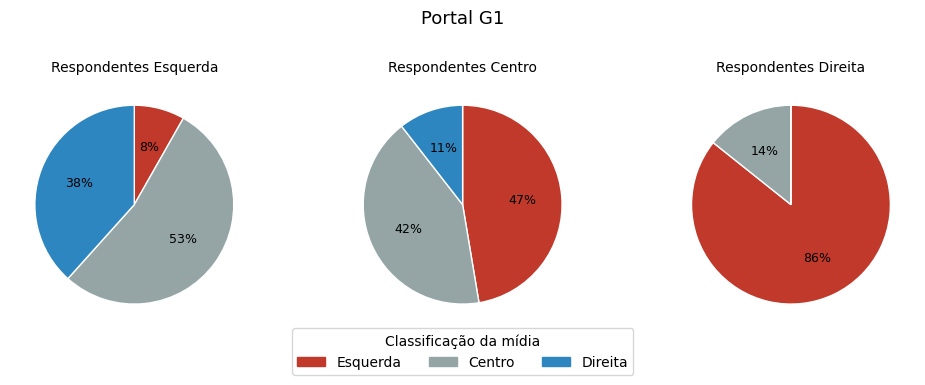

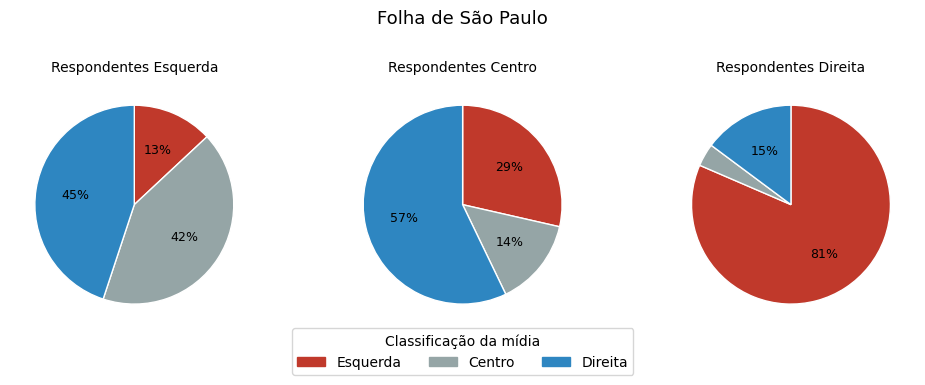

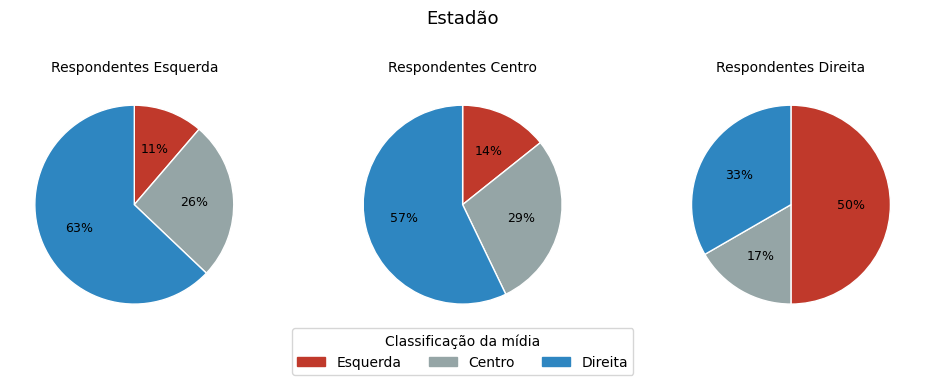

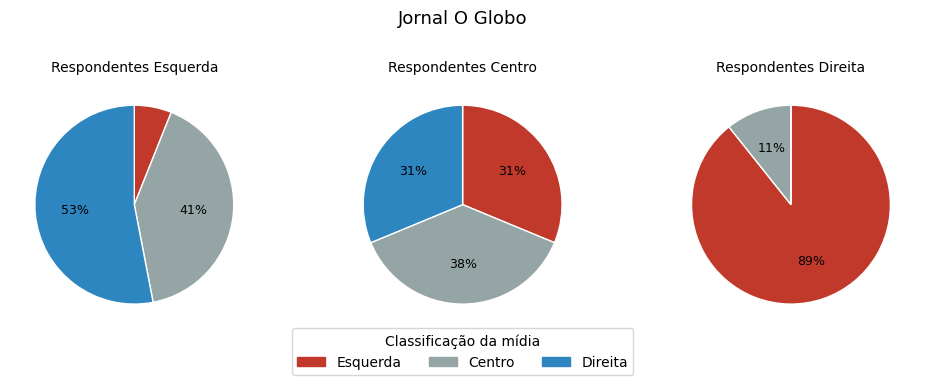

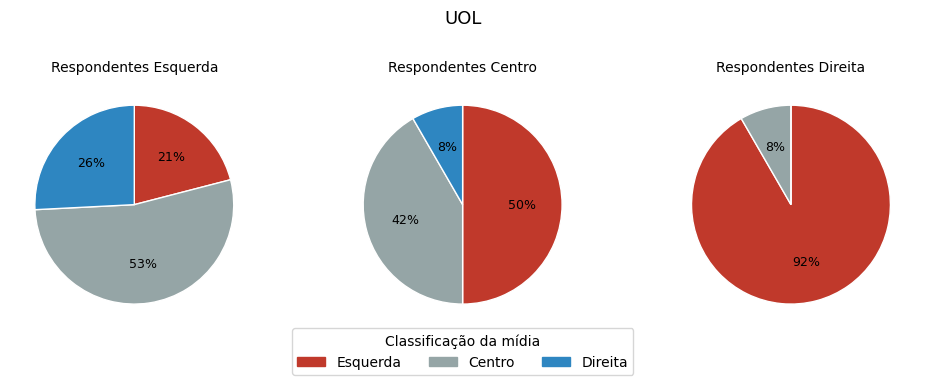

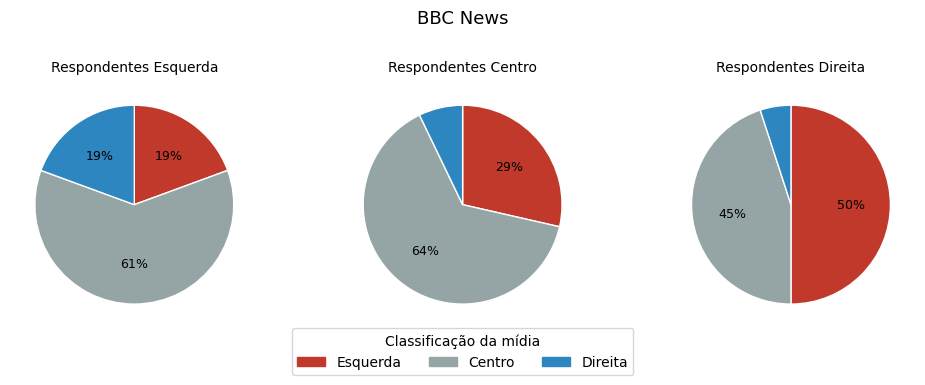

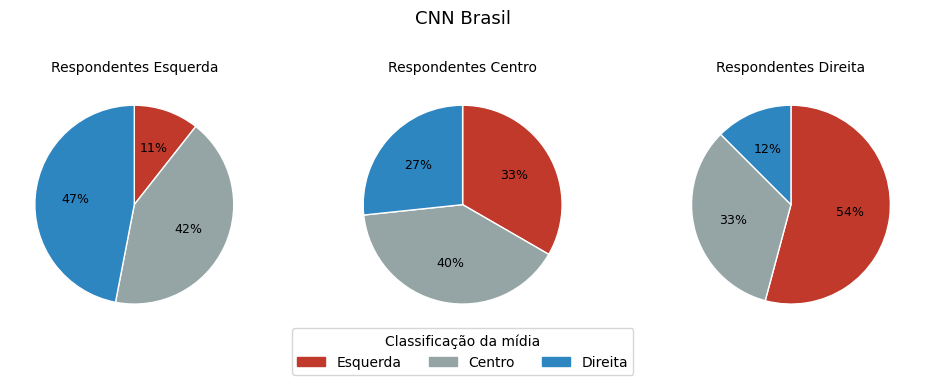

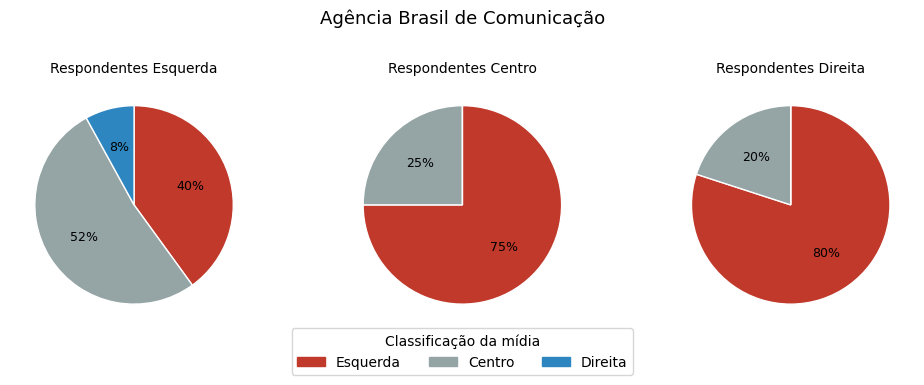

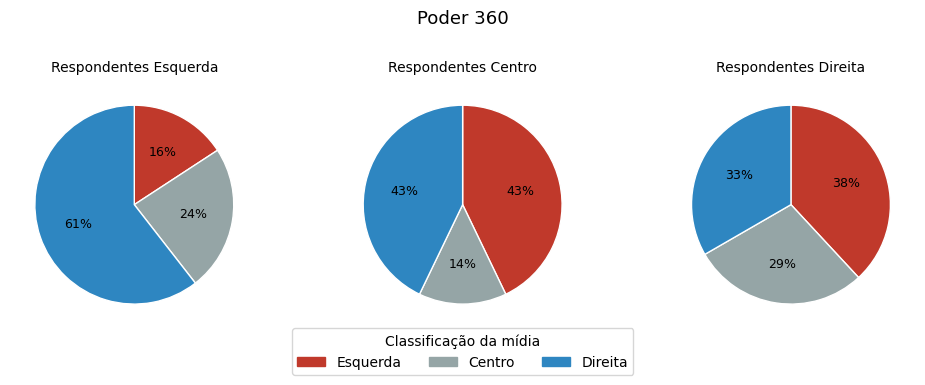

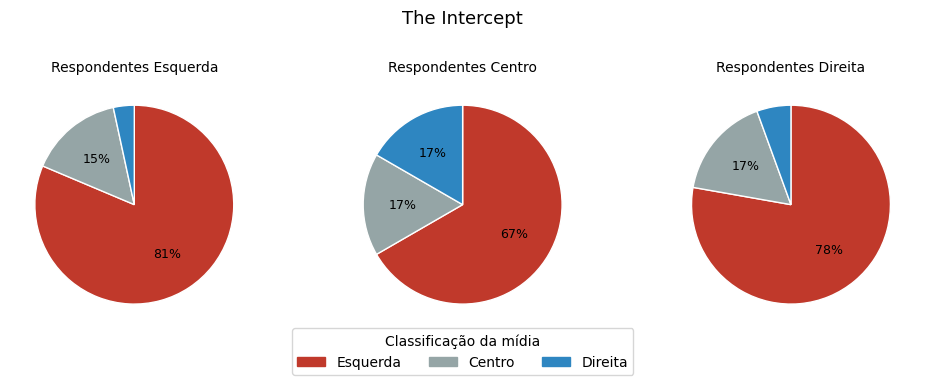

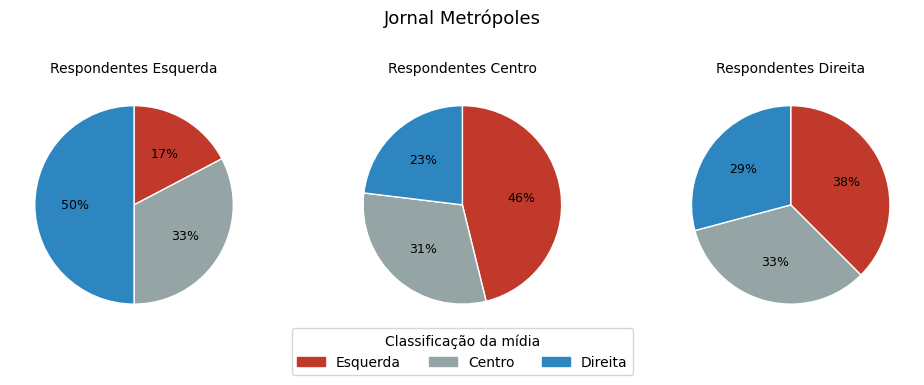

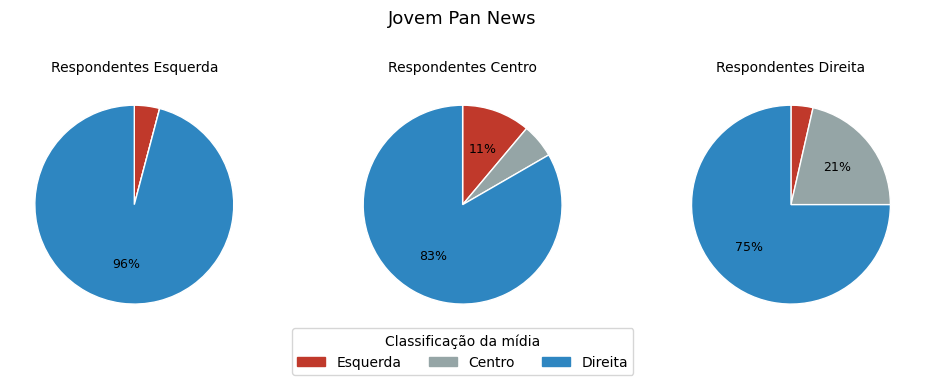

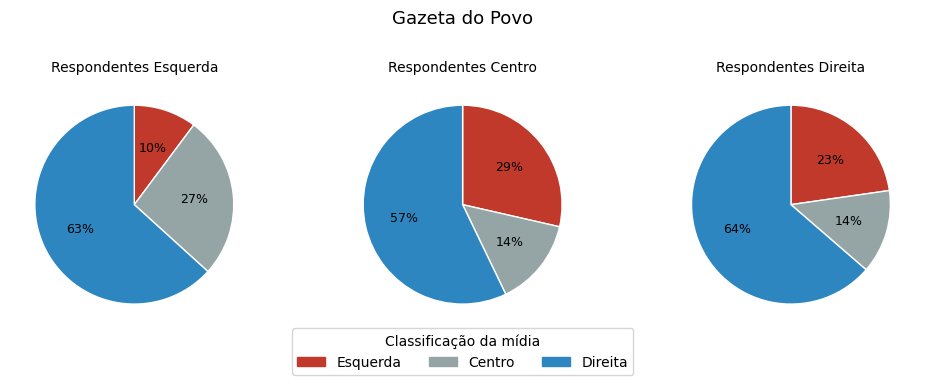

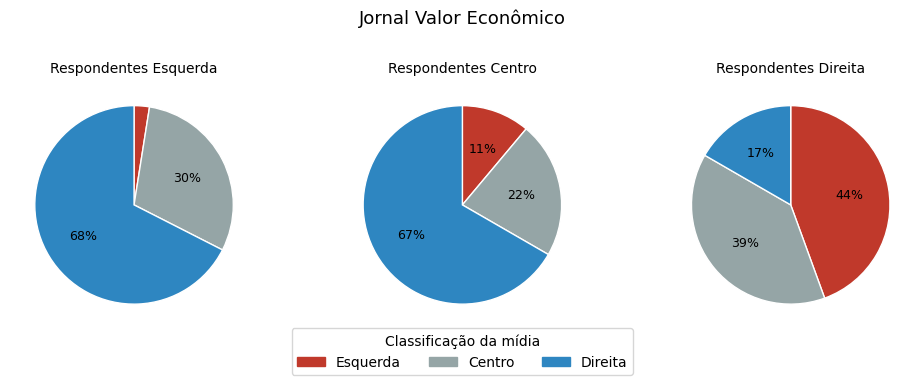

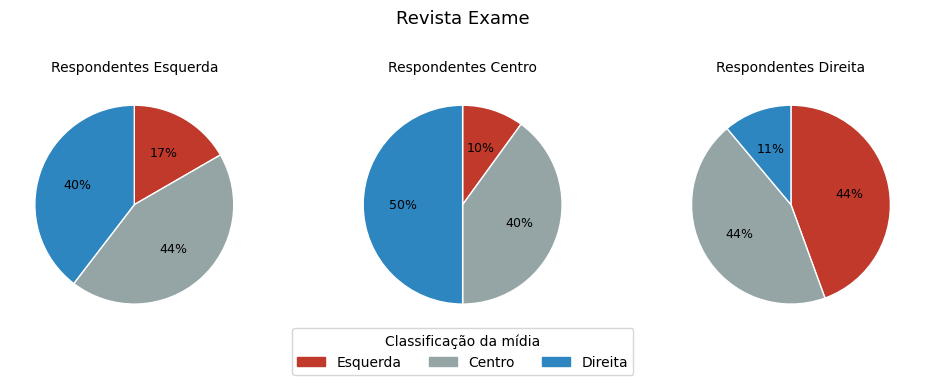

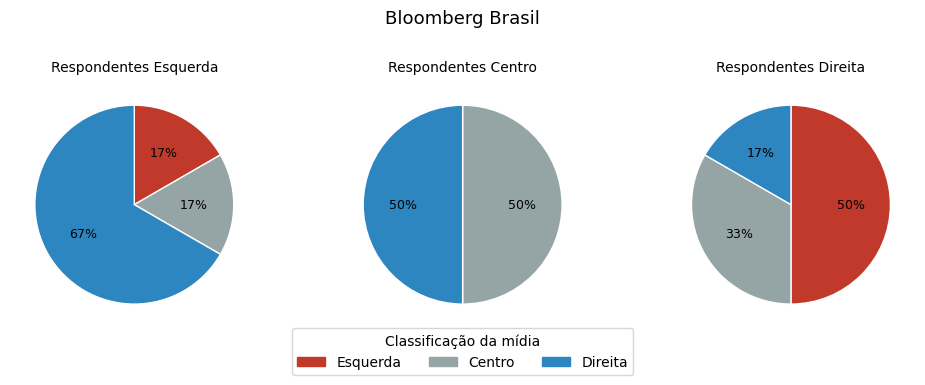

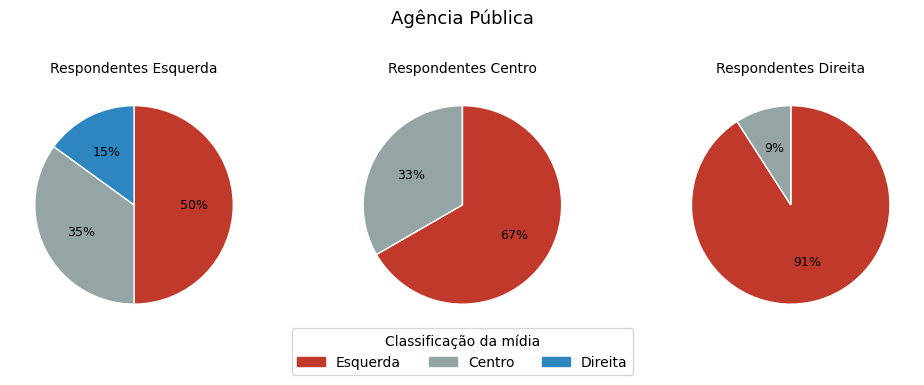

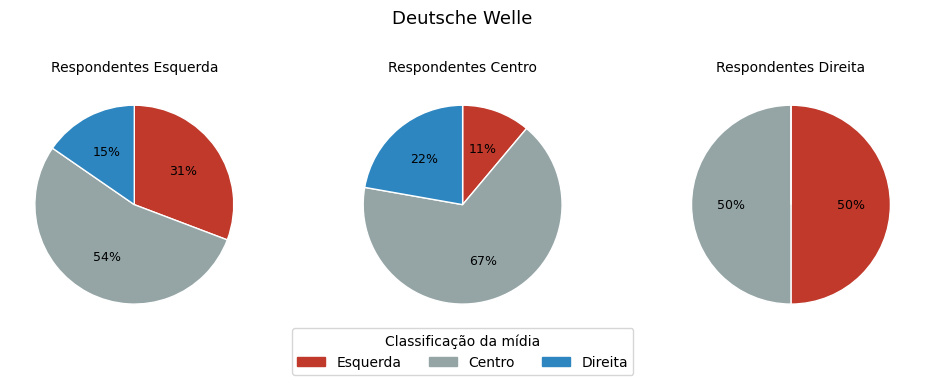

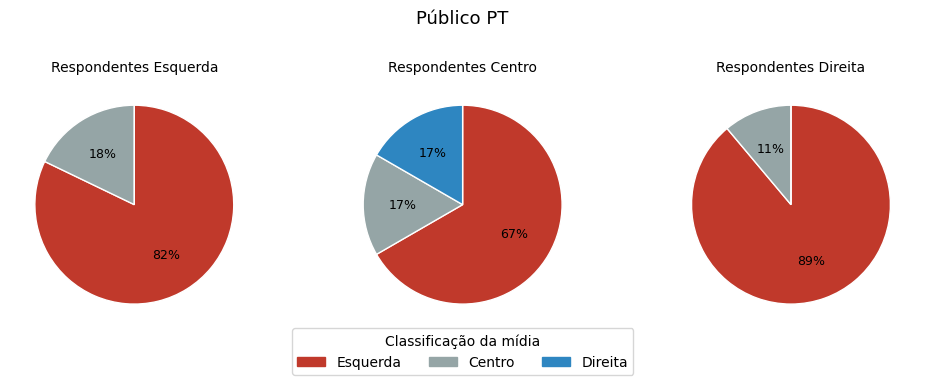

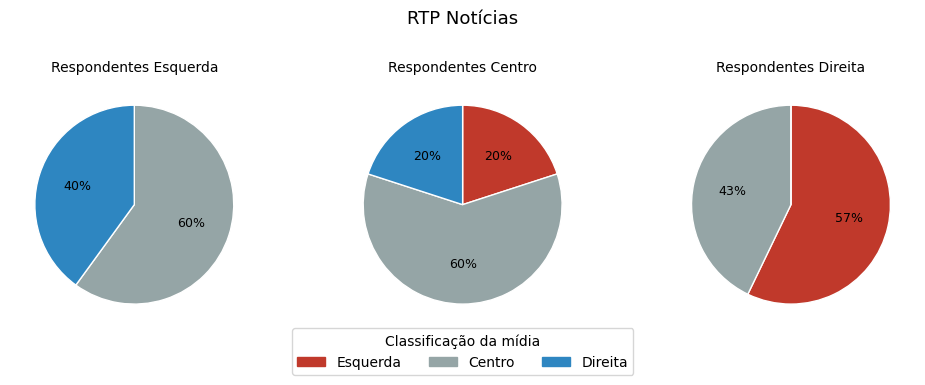

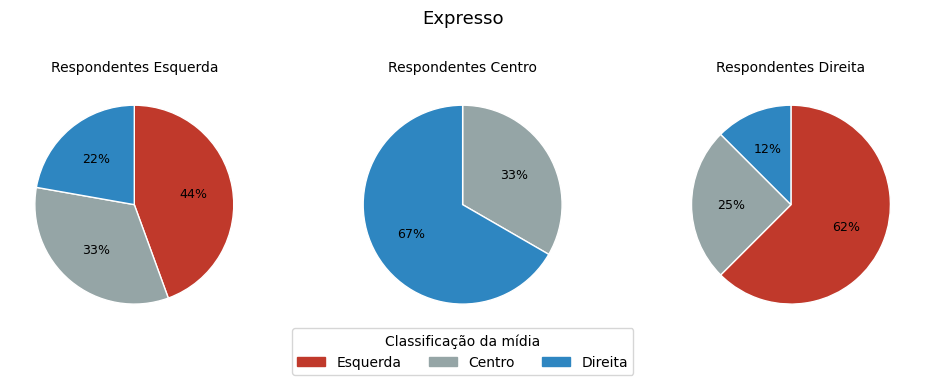

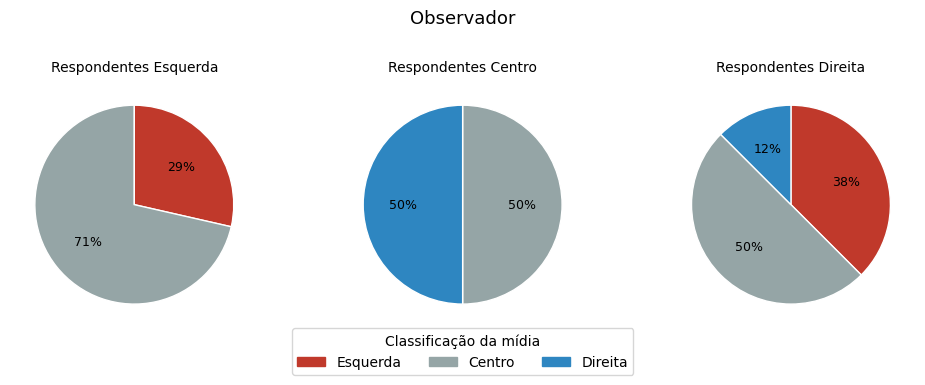

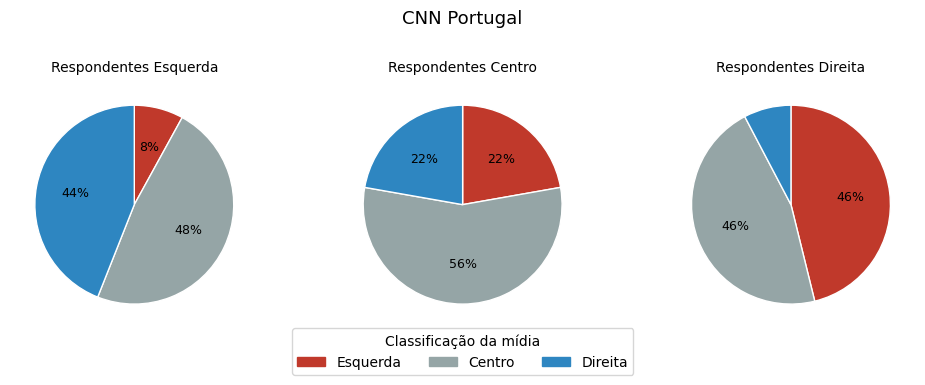

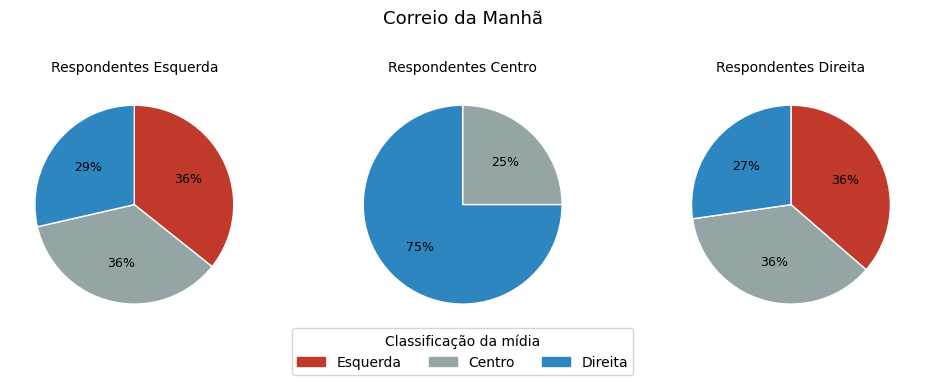

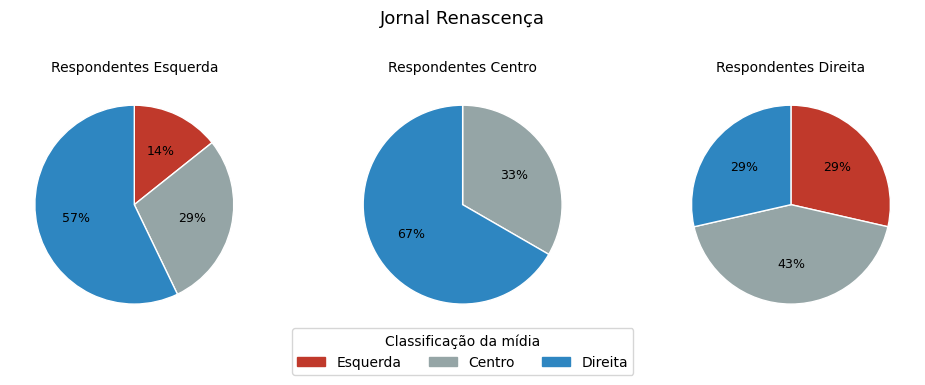

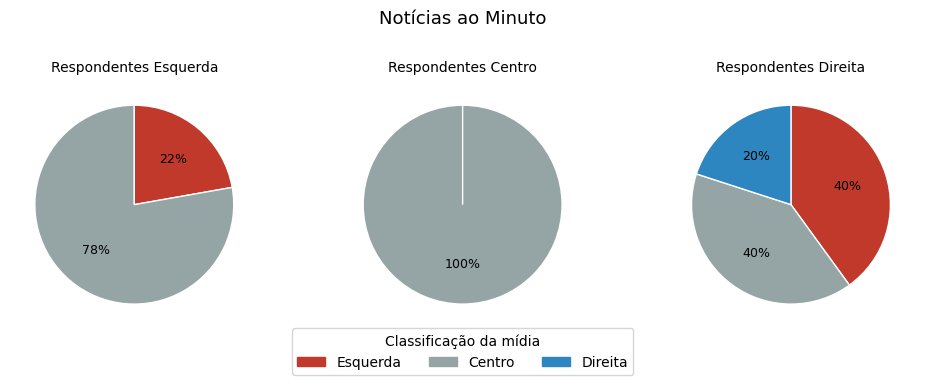

In [12]:
# pcts[grupo]: linhas = midias, colunas = avaliacao (proporcao dentro do grupo)
spectra = ["Esquerda", "Centro", "Direita"]
pcts = {}
for sp in spectra:
    sub = enquete[enquete["Politica"] == sp]
    pcts[sp] = pd.DataFrame({c: sub[c].value_counts(normalize=True).reindex(spectra, fill_value=0)
                             for c in cols}).T

spectra = ["Esquerda", "Centro", "Direita"]
colors = {"Esquerda": "#c0392b", "Centro": "#95a5a6", "Direita": "#2e86c1"}
handles = [Patch(color=colors[s], label=s) for s in spectra]

def plot_media(c):
    # Tamanho e plottagens sugeridos por IA
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.8))
    for ax, sp in zip(axes, spectra):
        vals = pcts[sp].loc[c, spectra]
        n = int((enquete["Politica"] == sp).sum())
        ax.set_title(f"Respondentes {sp}", fontsize=10)
        if vals.sum() == 0:
            ax.text(0.5, 0.5, "sem respostas", ha="center", va="center", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
        else:
            ax.pie(vals, colors=[colors[s] for s in spectra],
                   autopct=lambda p: f"{p:.0f}%" if p >= 8 else "",
                   textprops={"fontsize": 9}, startangle=90, counterclock=False,
                   wedgeprops={"linewidth": 1, "edgecolor": "white"})
            ax.set_aspect("equal")
    fig.suptitle(full_names[c], fontsize=13)
    fig.legend(handles=handles, title="Classificação da mídia", loc="lower center",
               ncol=3, bbox_to_anchor=(0.5, 0.0))
    plt.tight_layout(rect=[0, 0.1, 1, 0.92])
    plt.show()

for c in cols:
    plot_media(c)

## Análise por idade

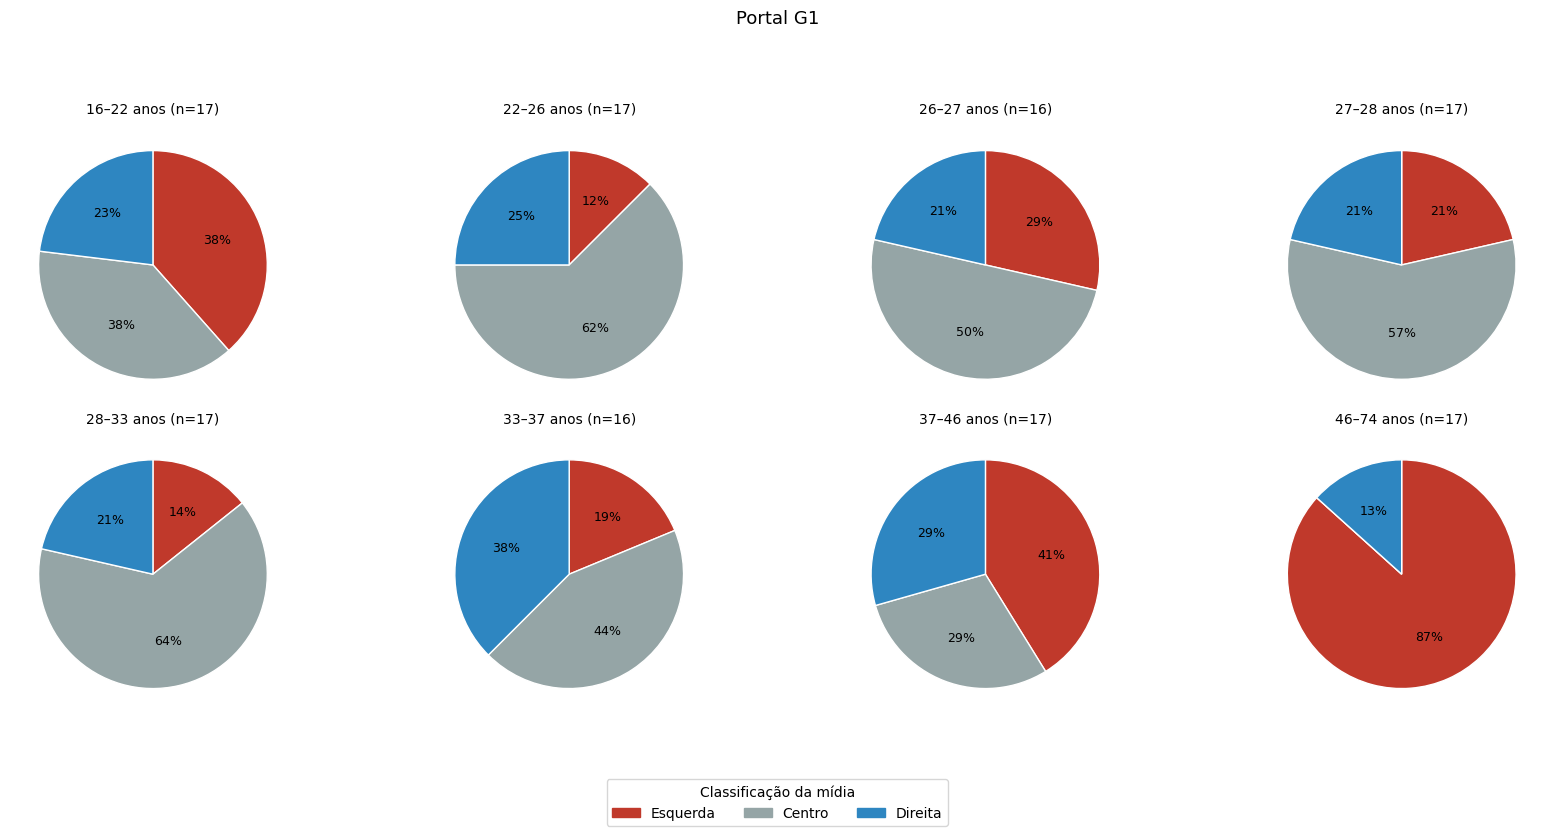

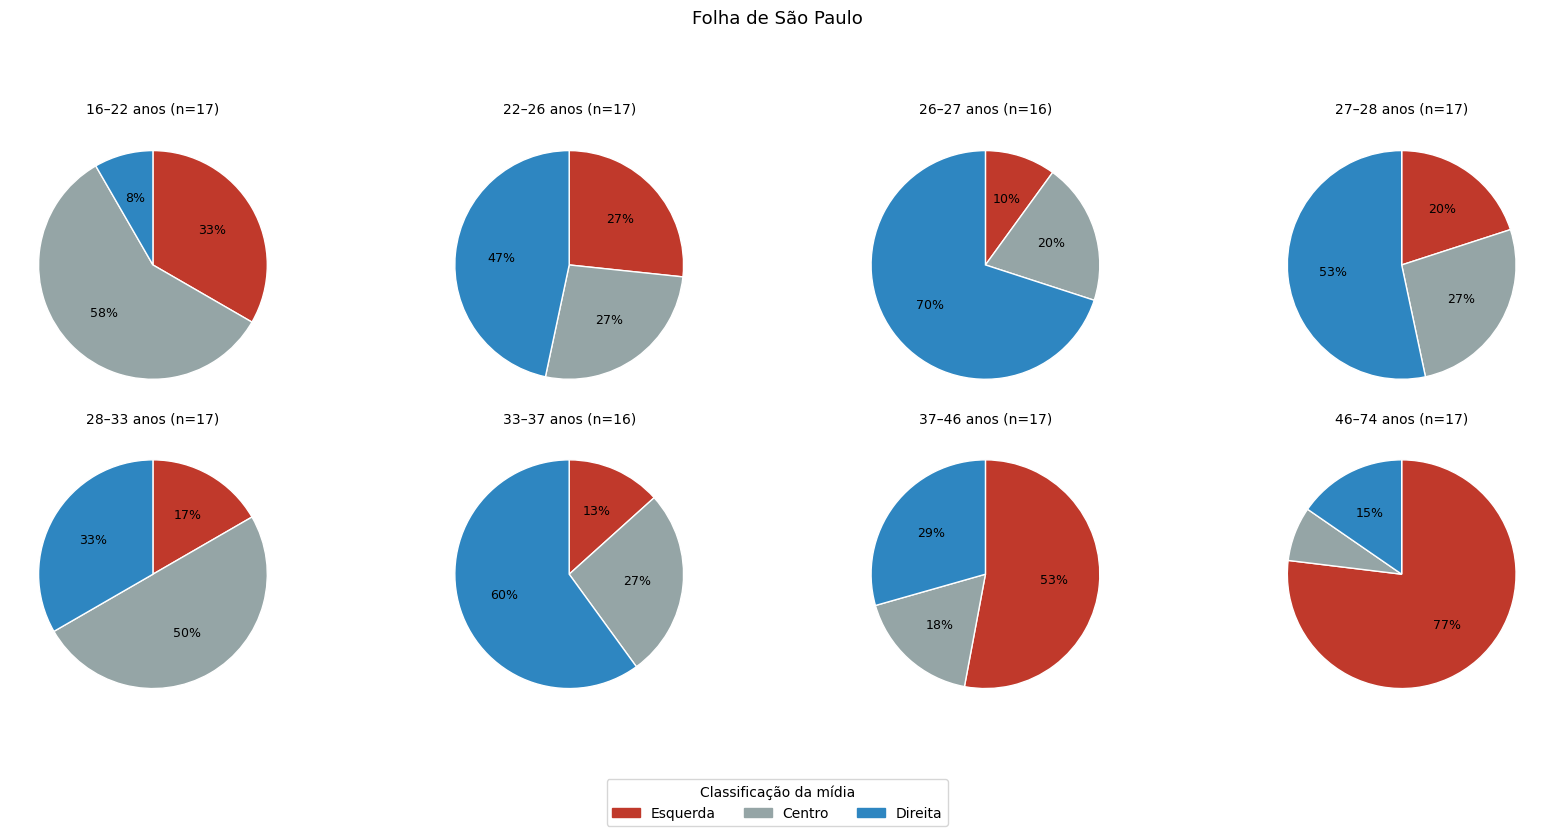

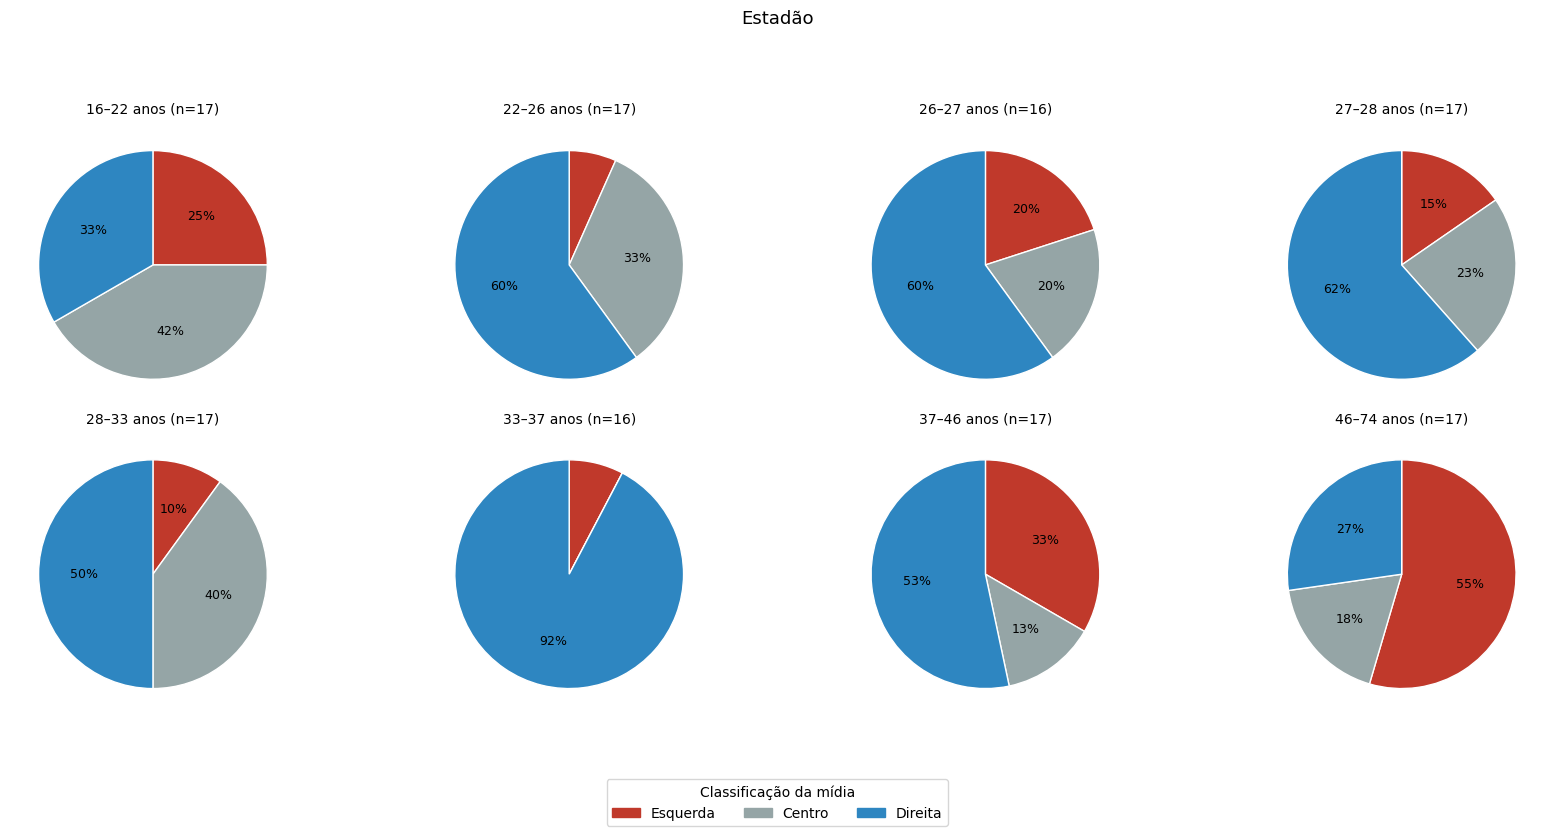

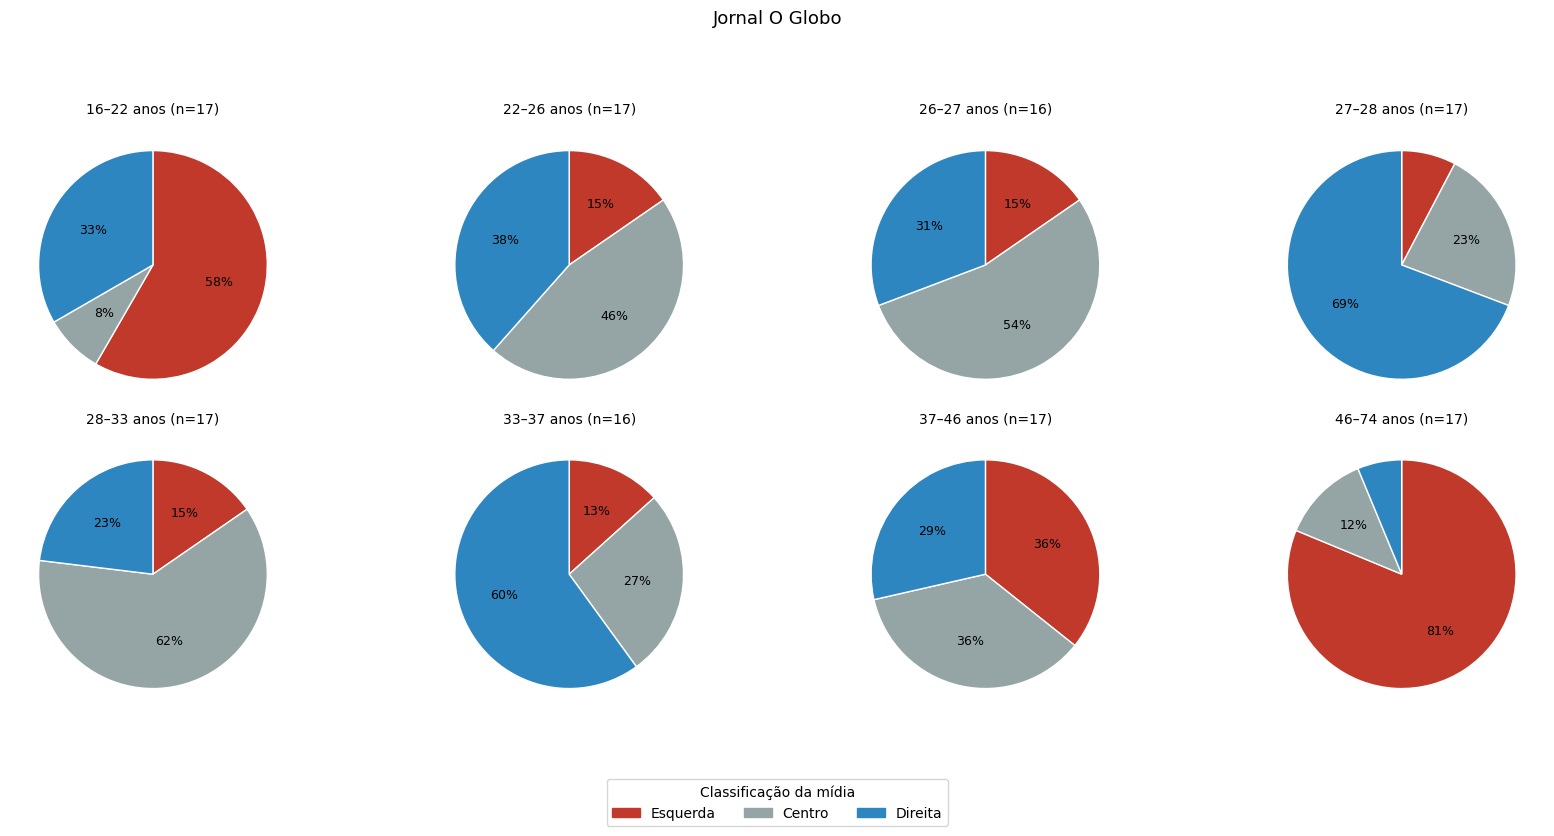

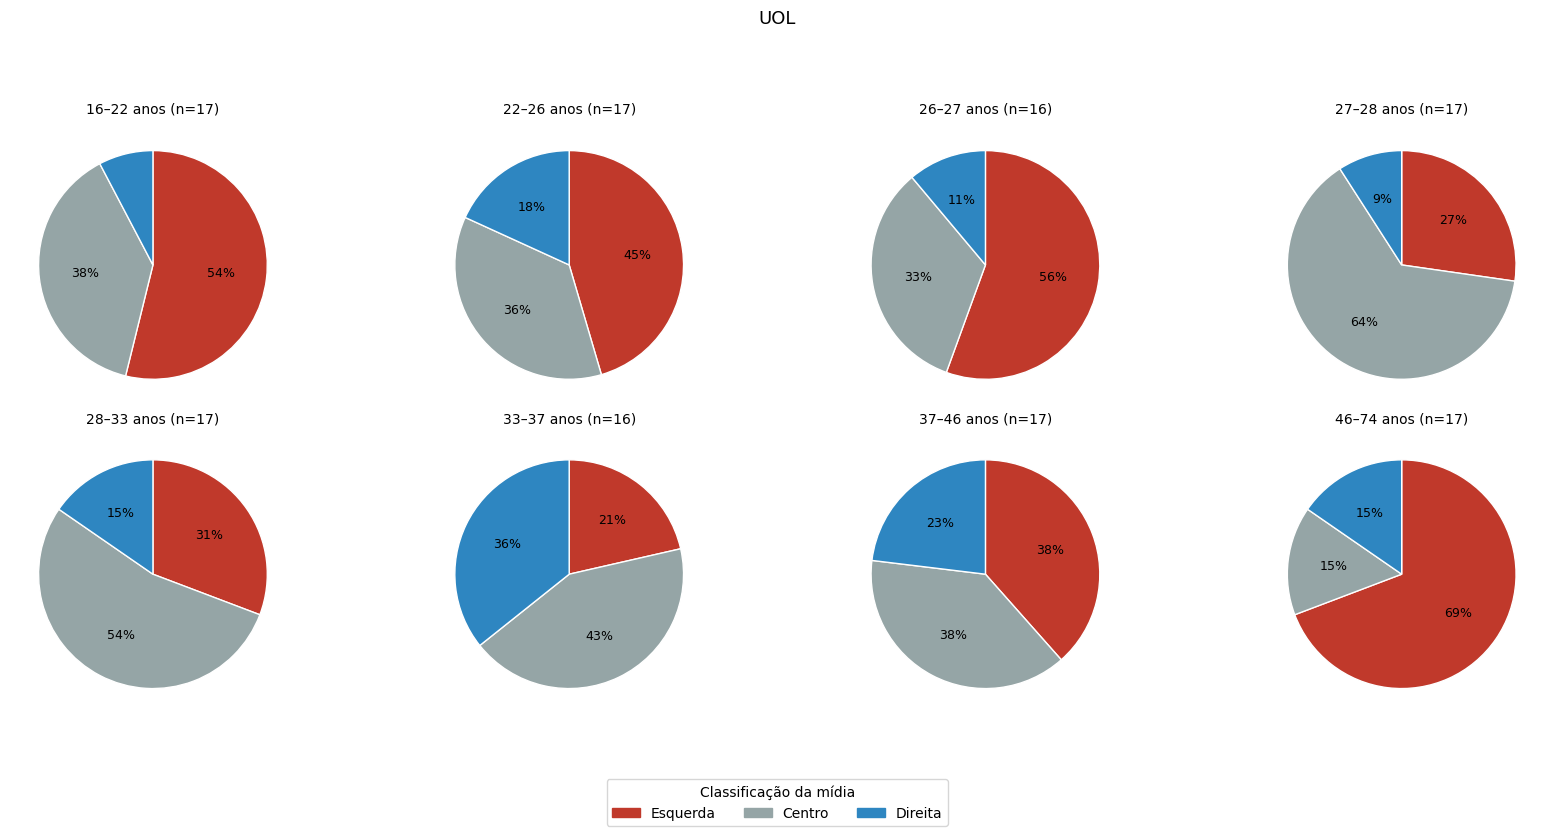

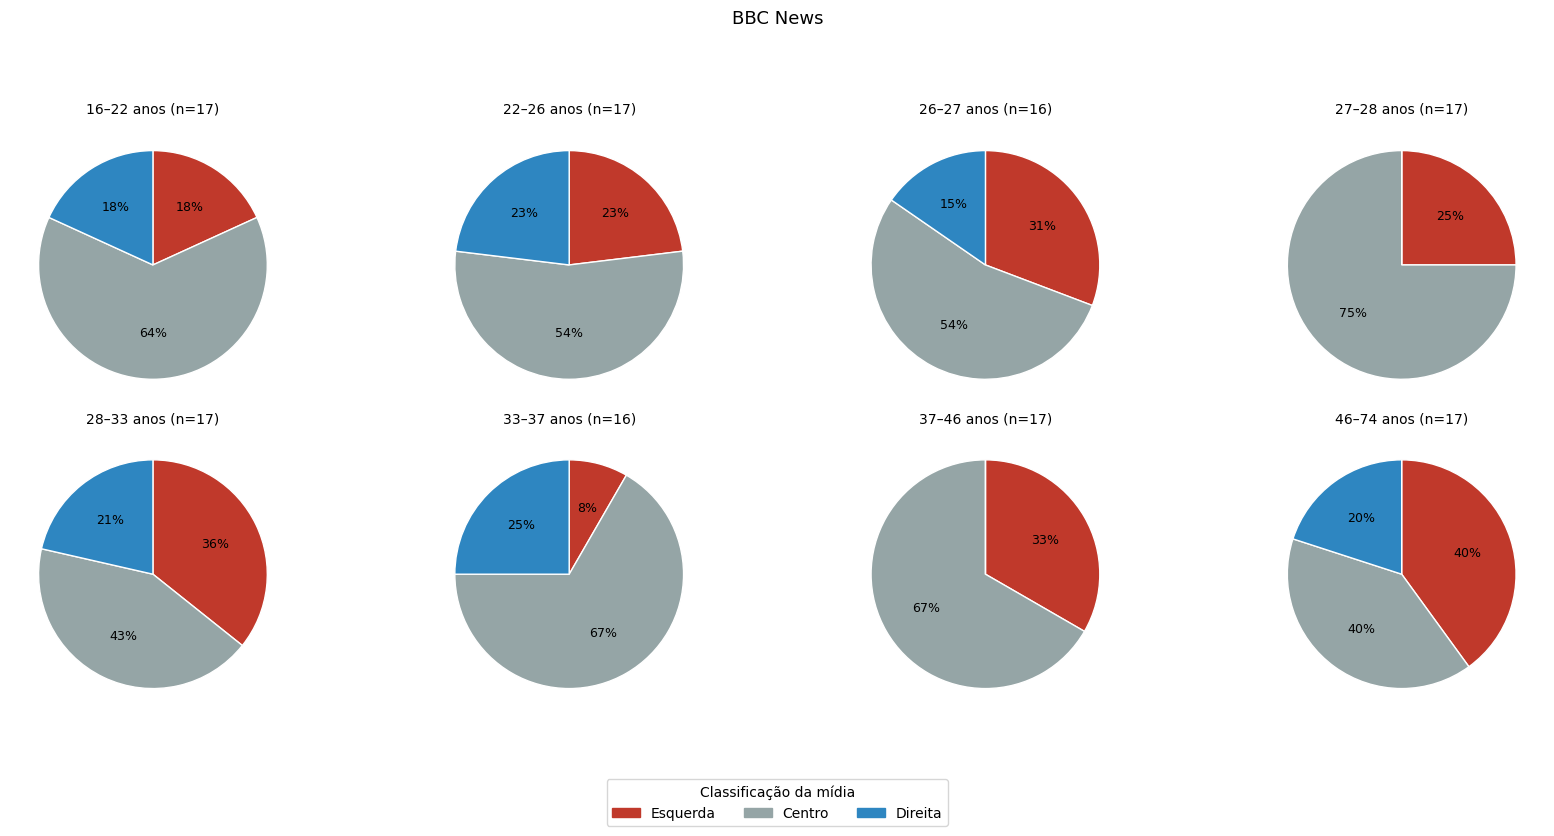

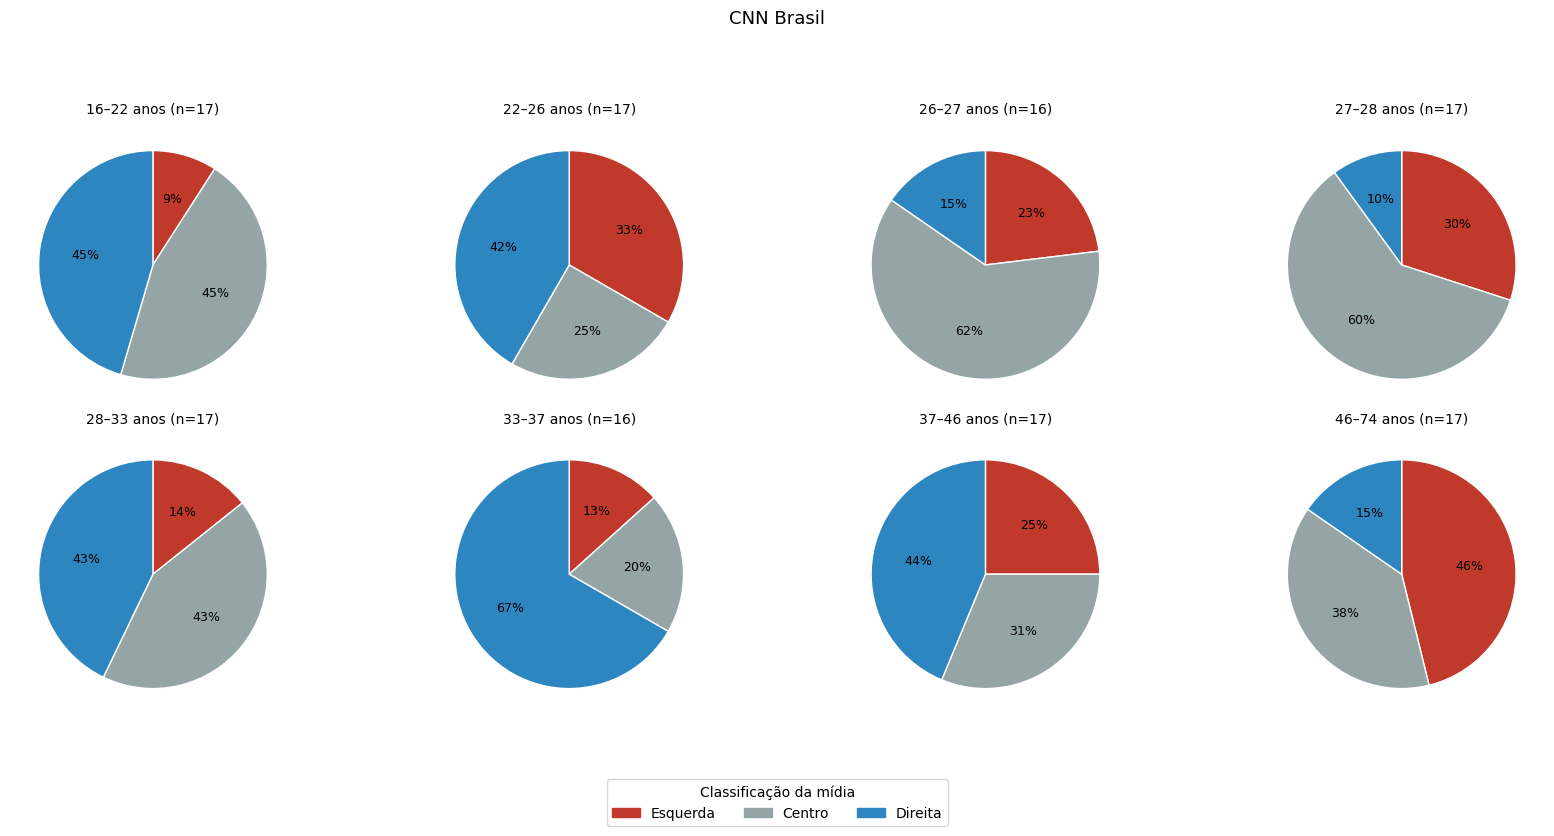

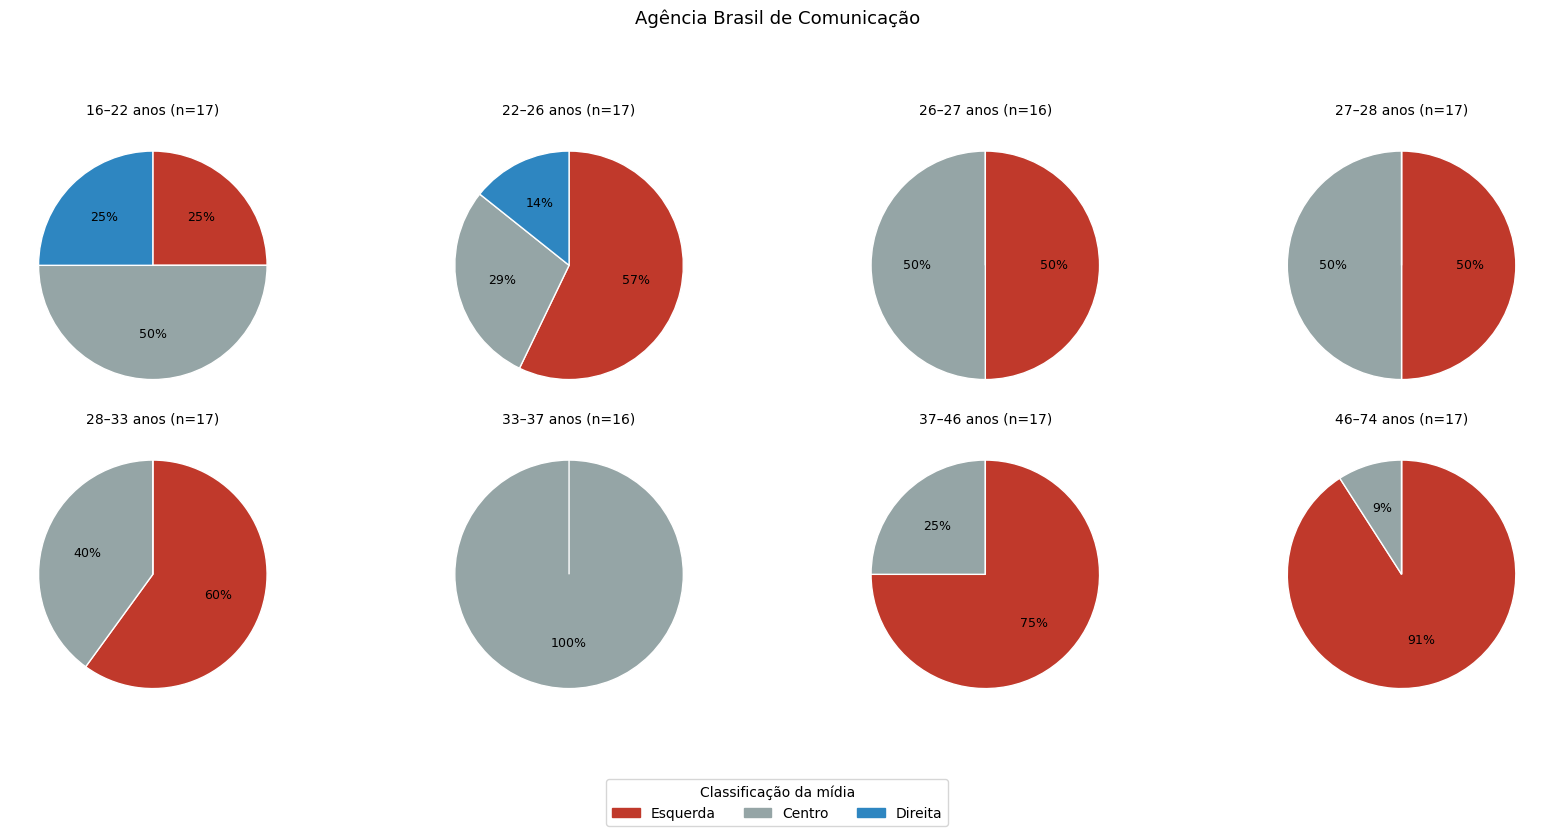

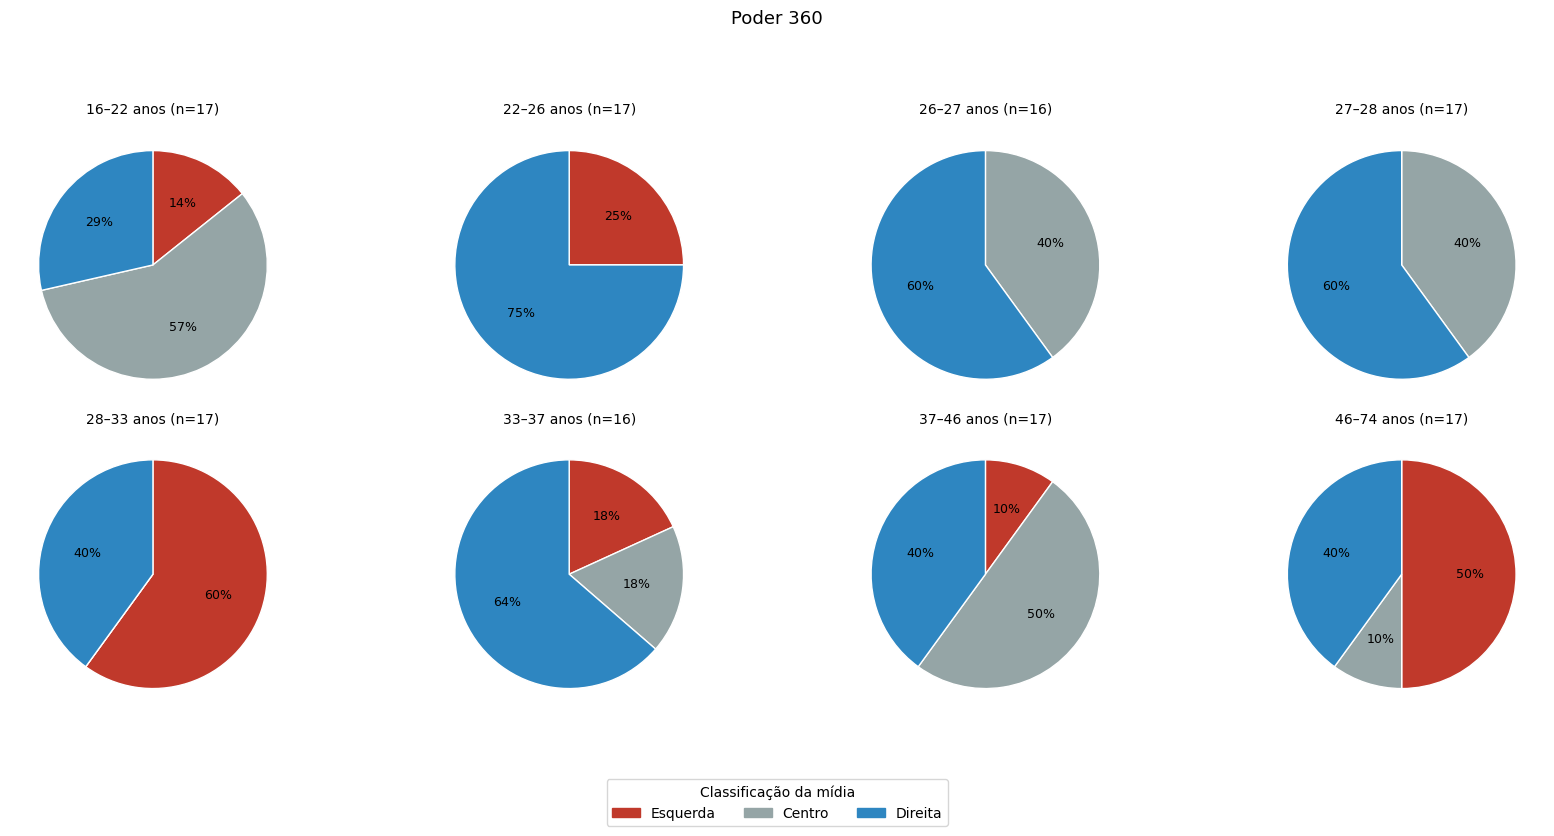

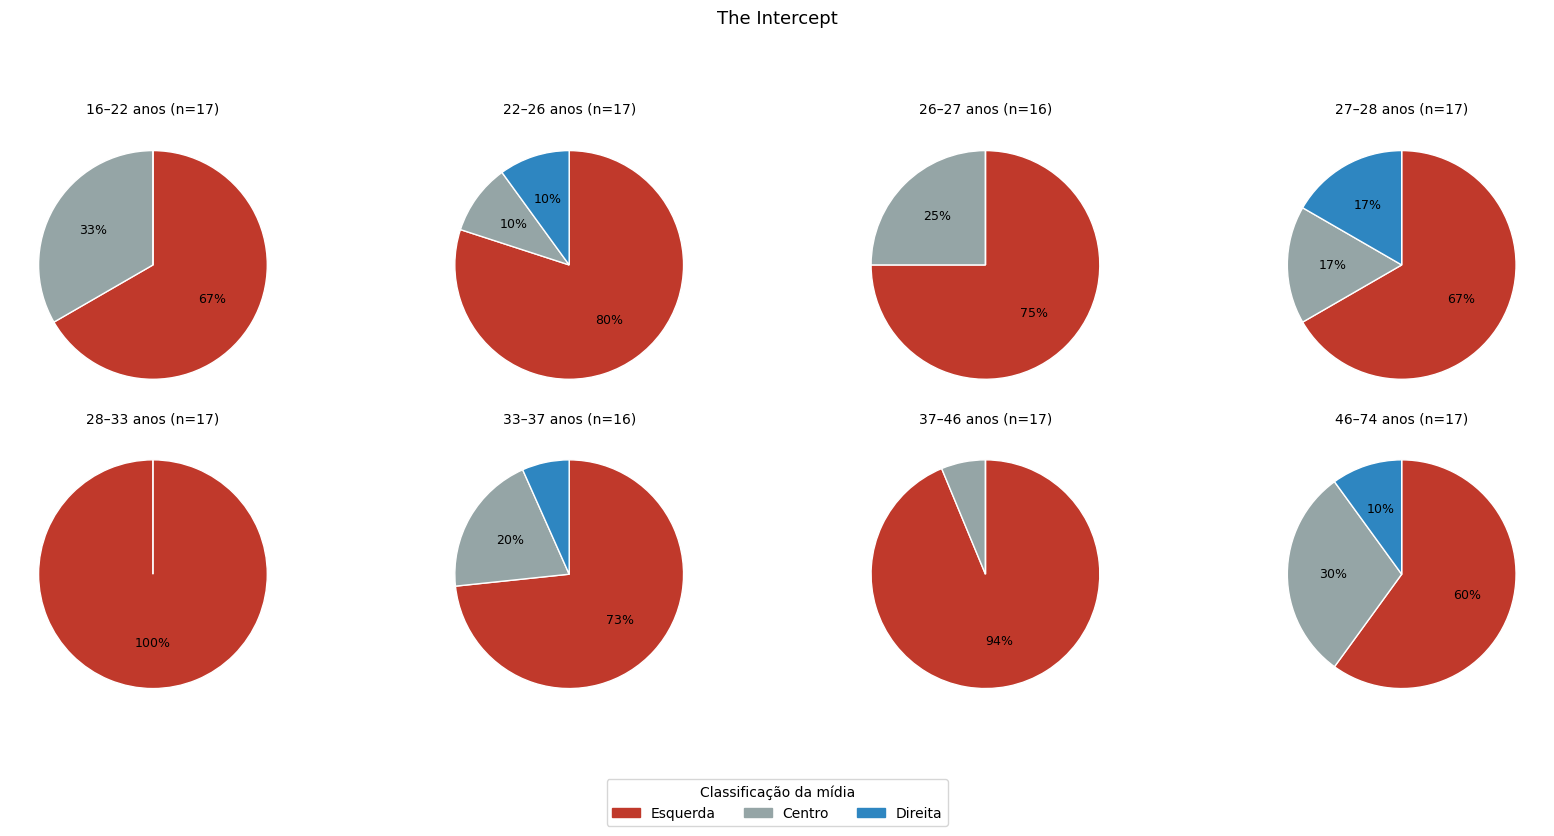

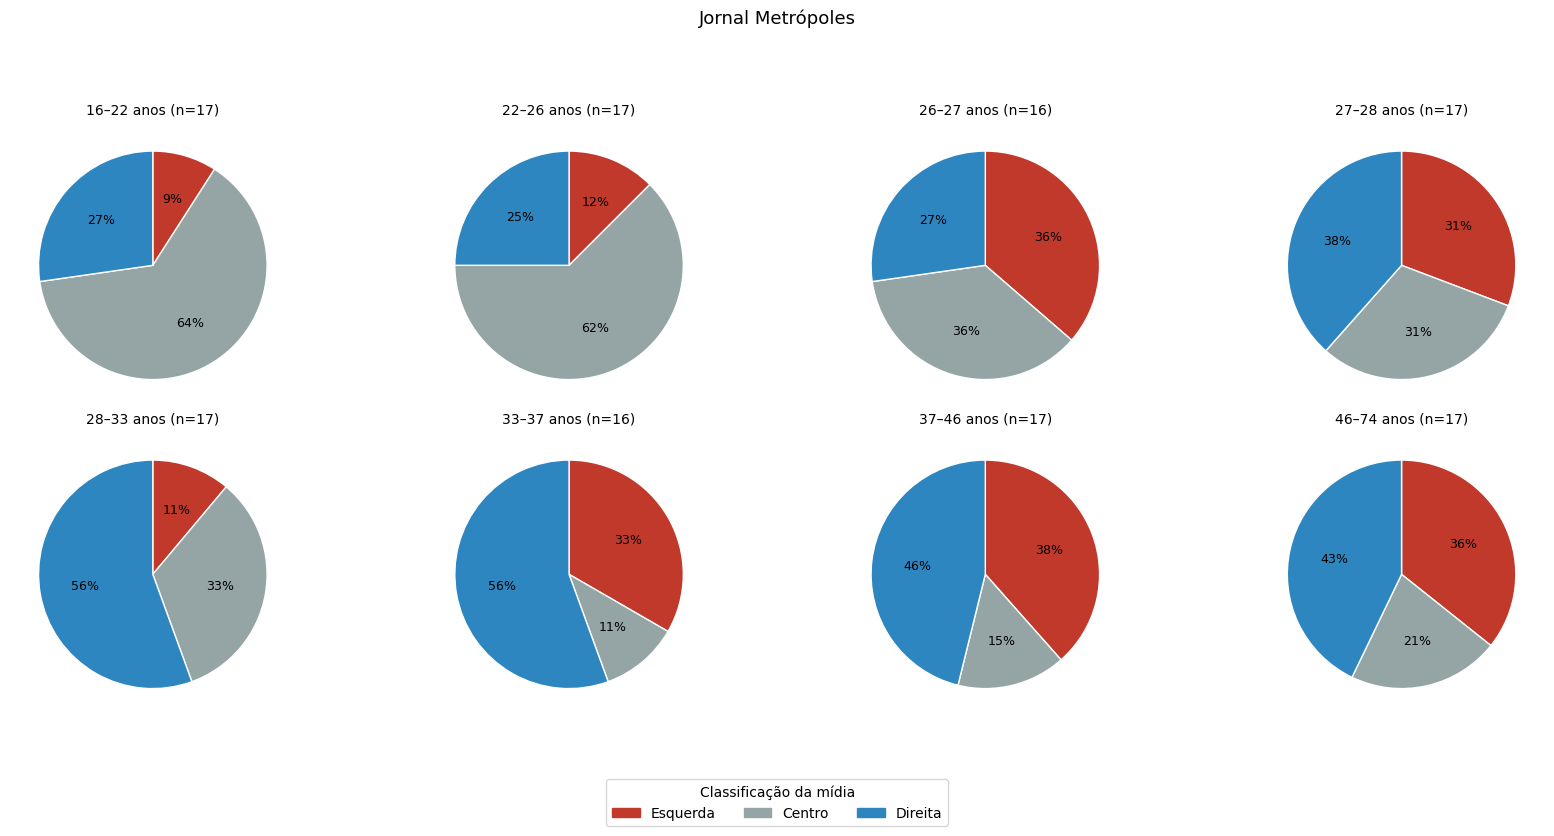

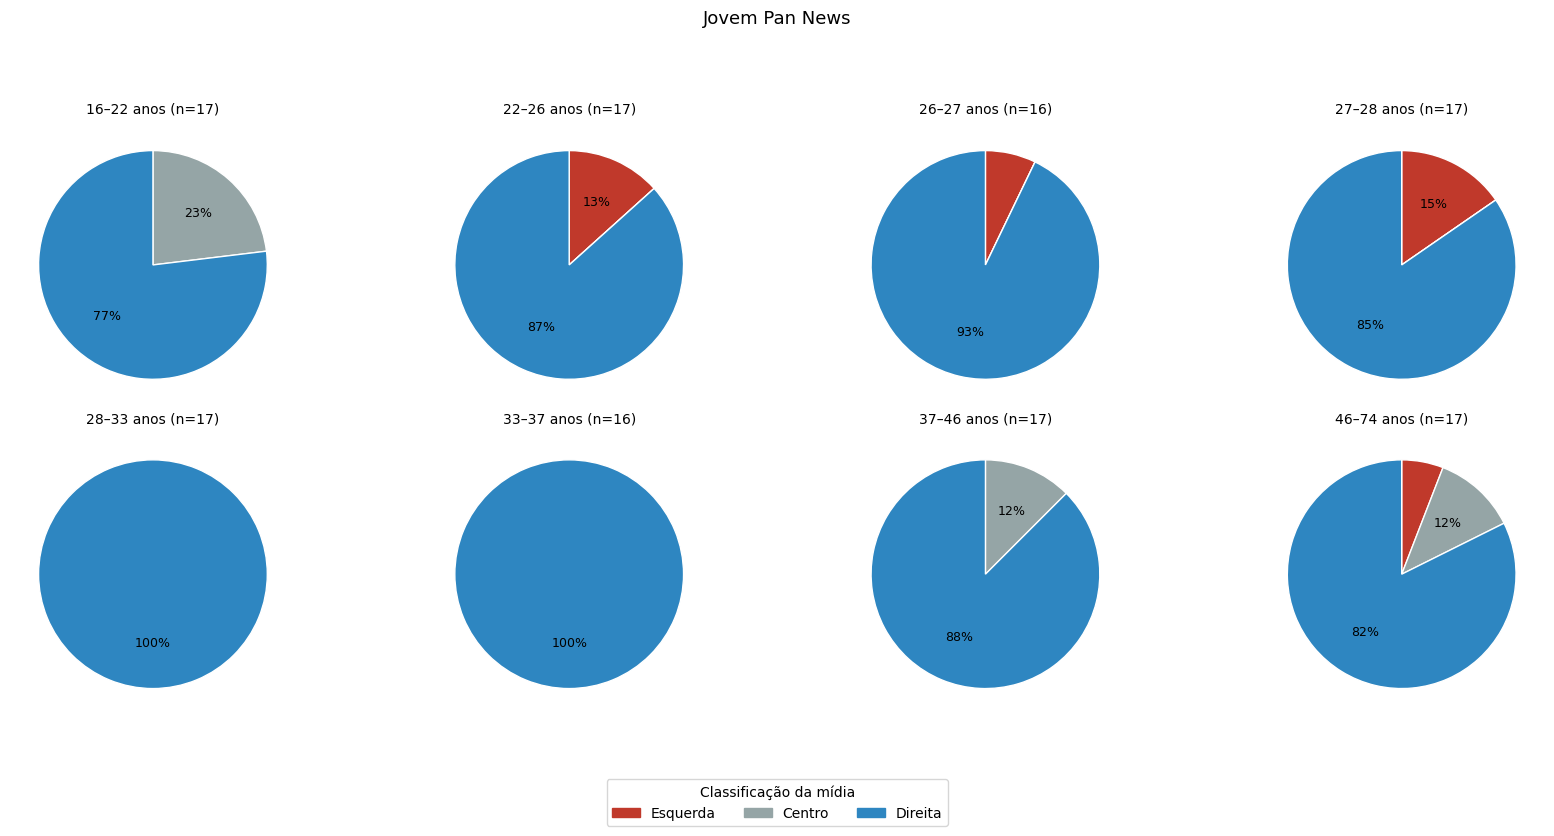

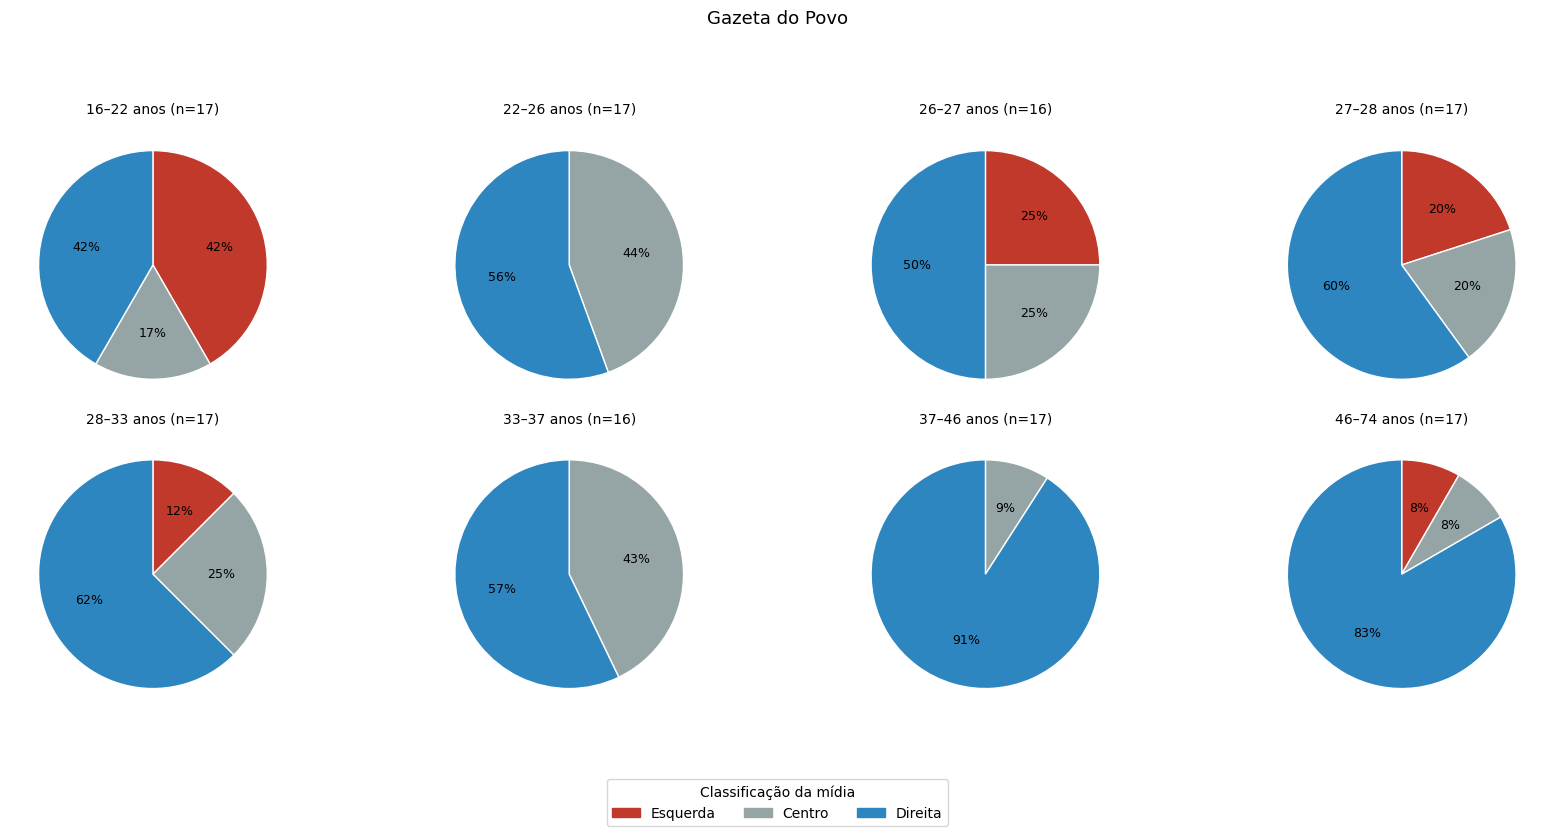

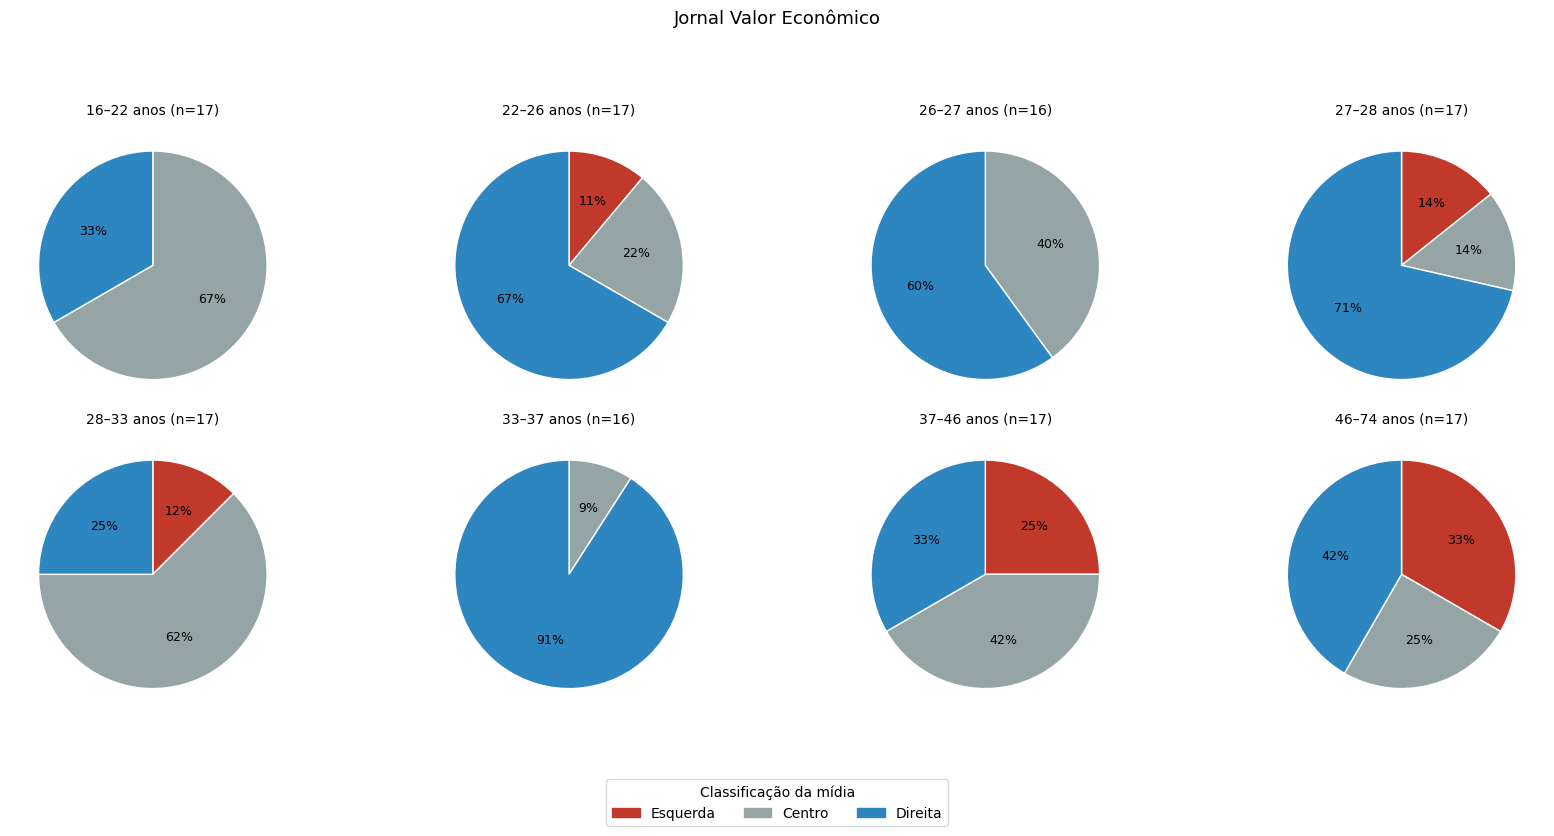

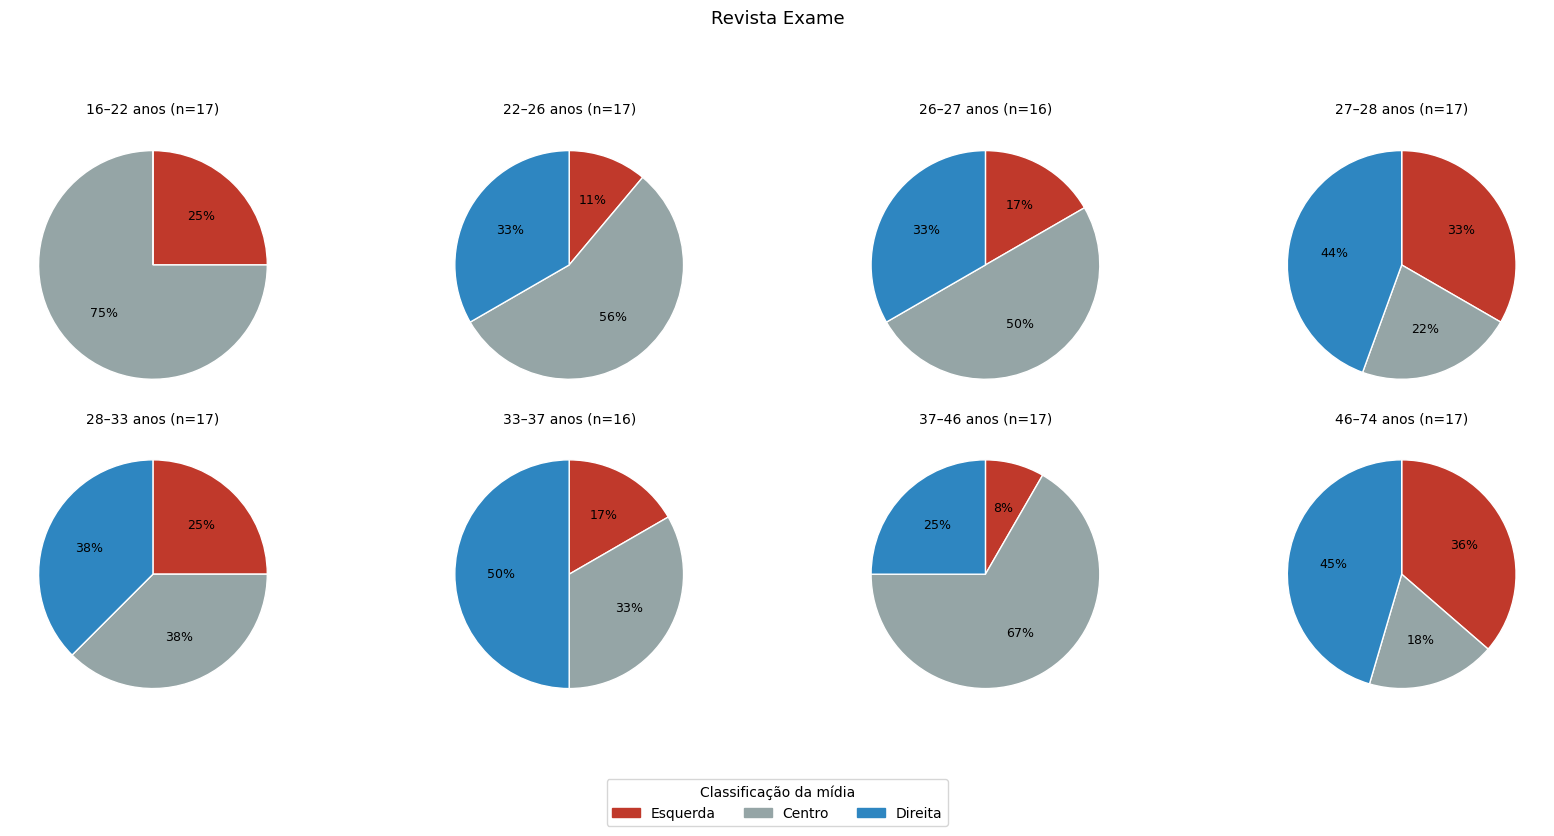

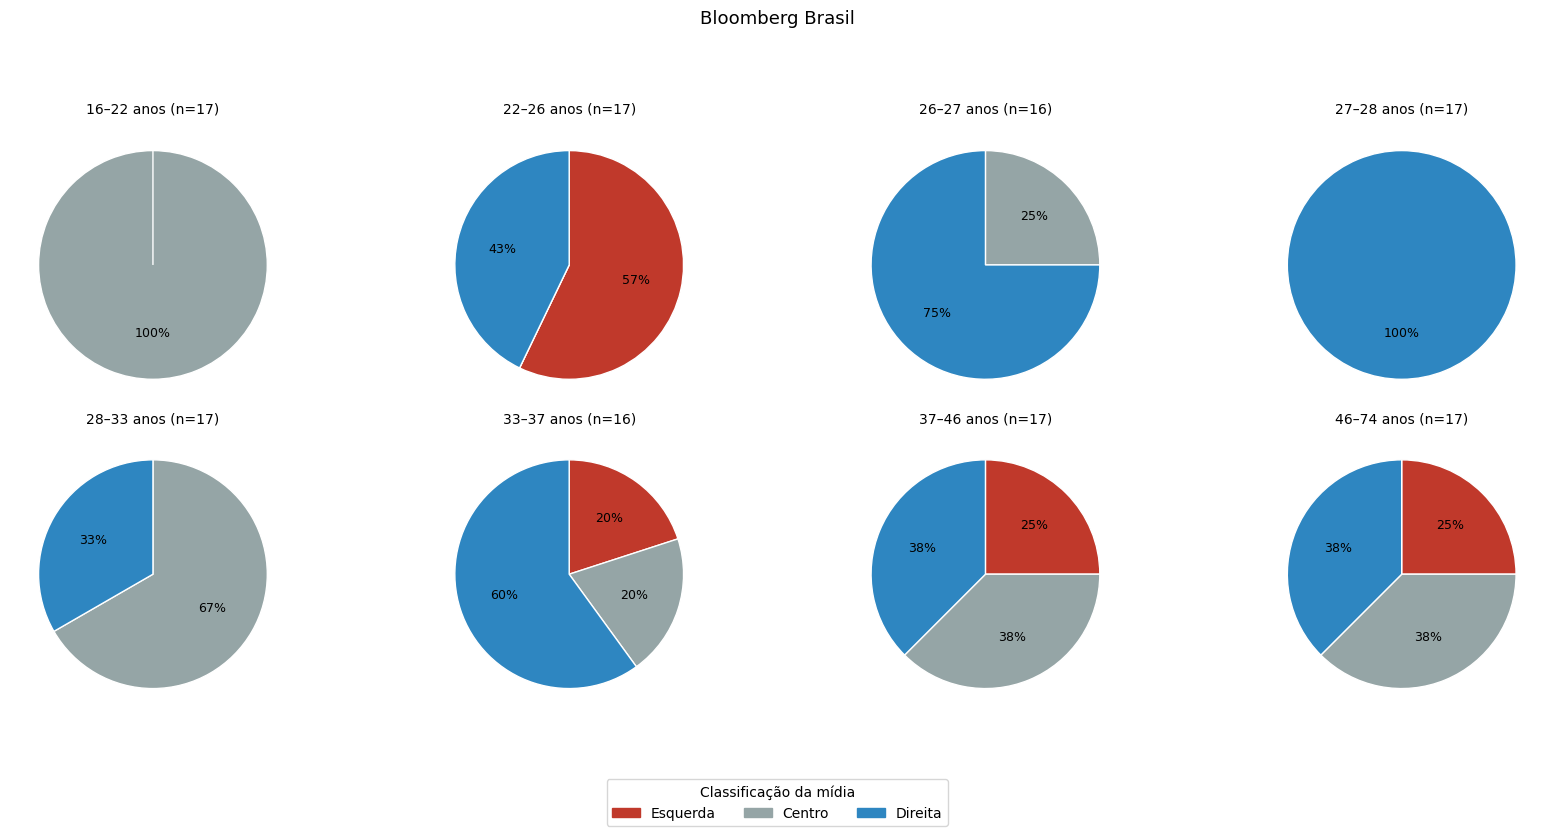

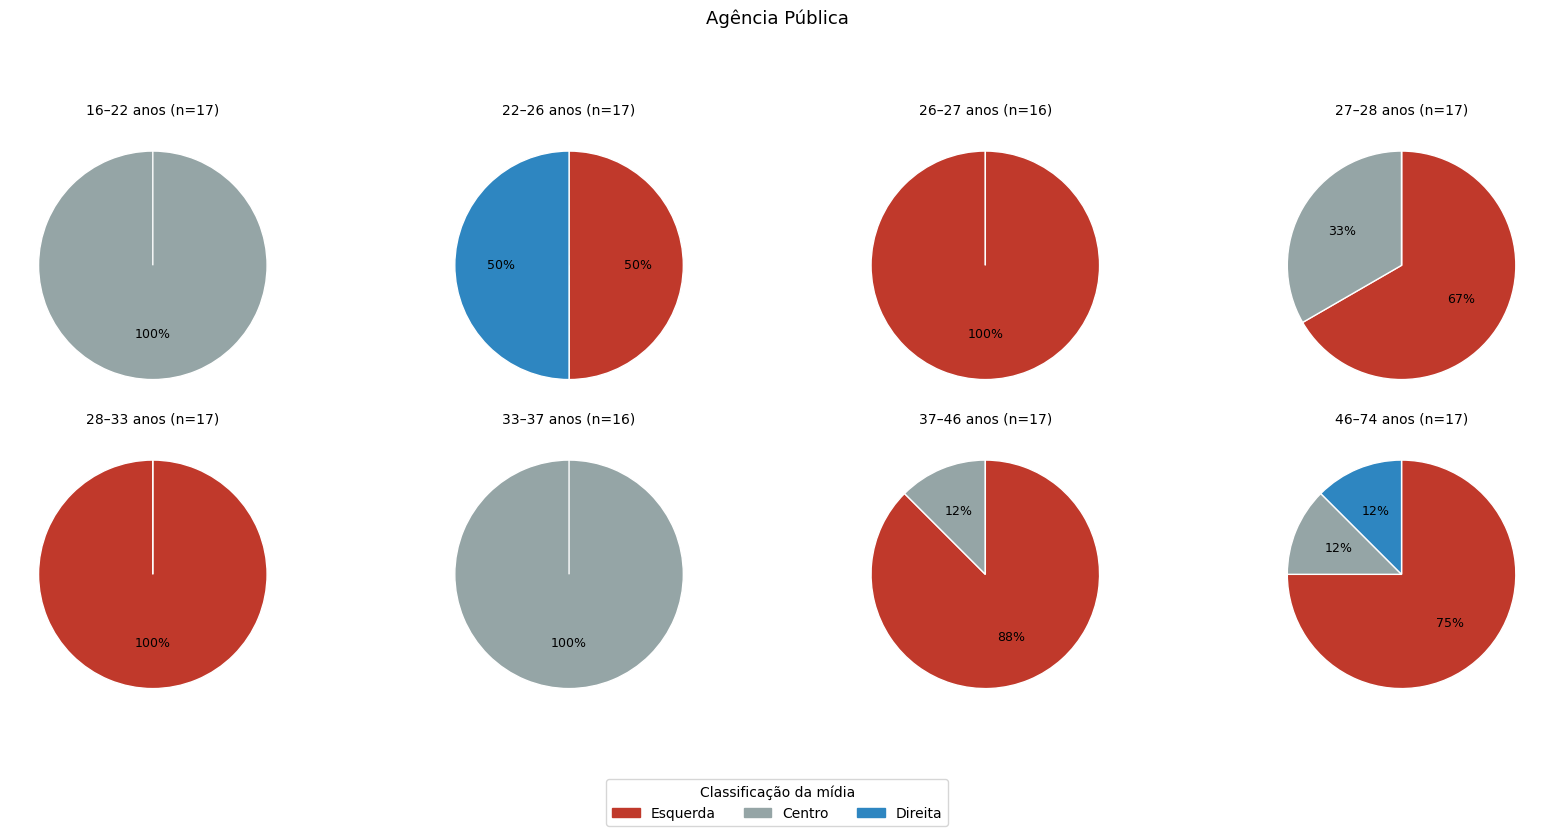

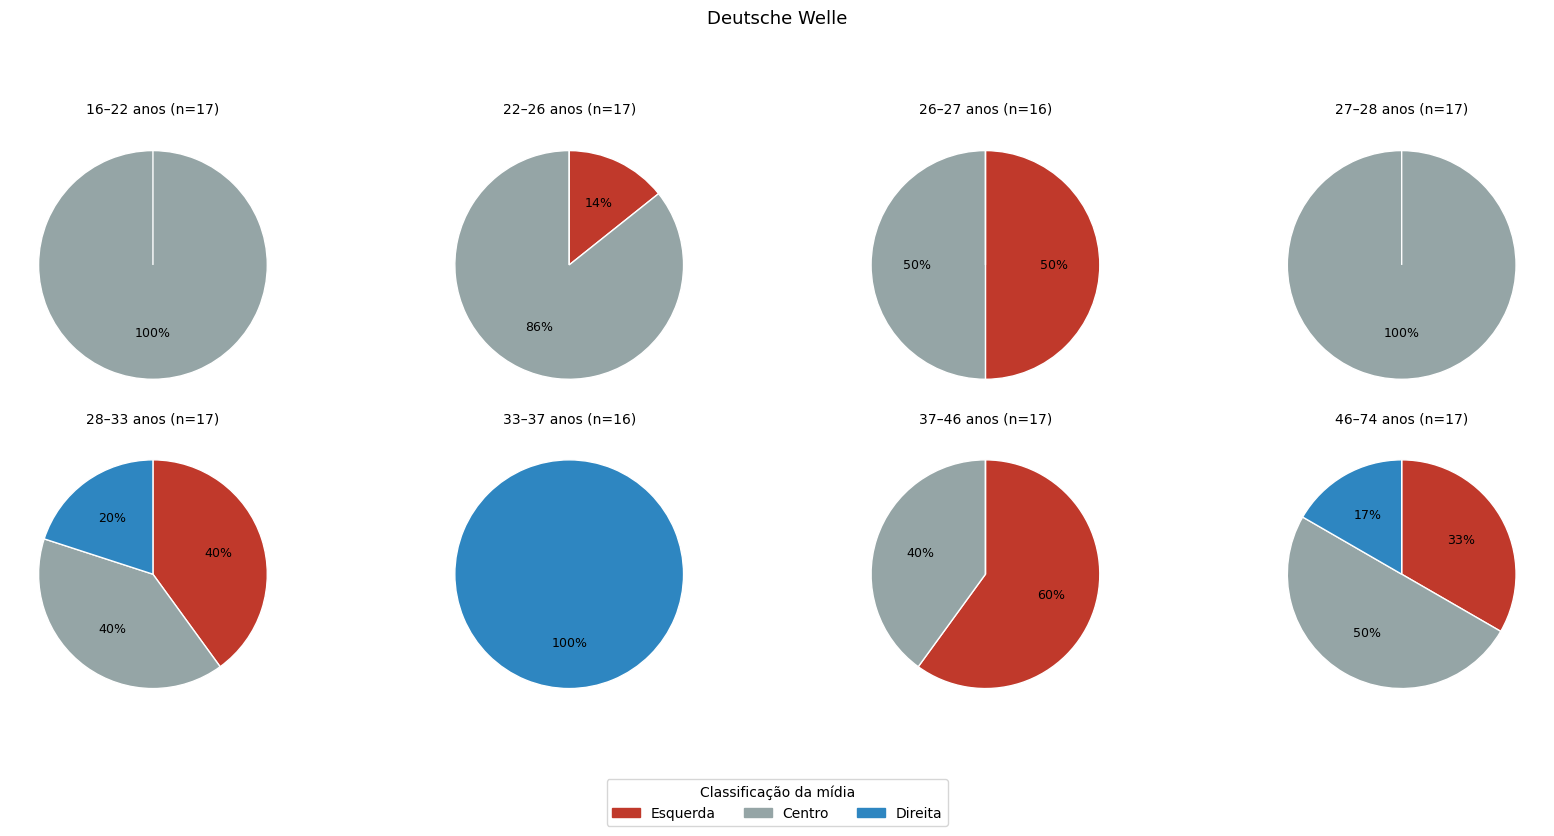

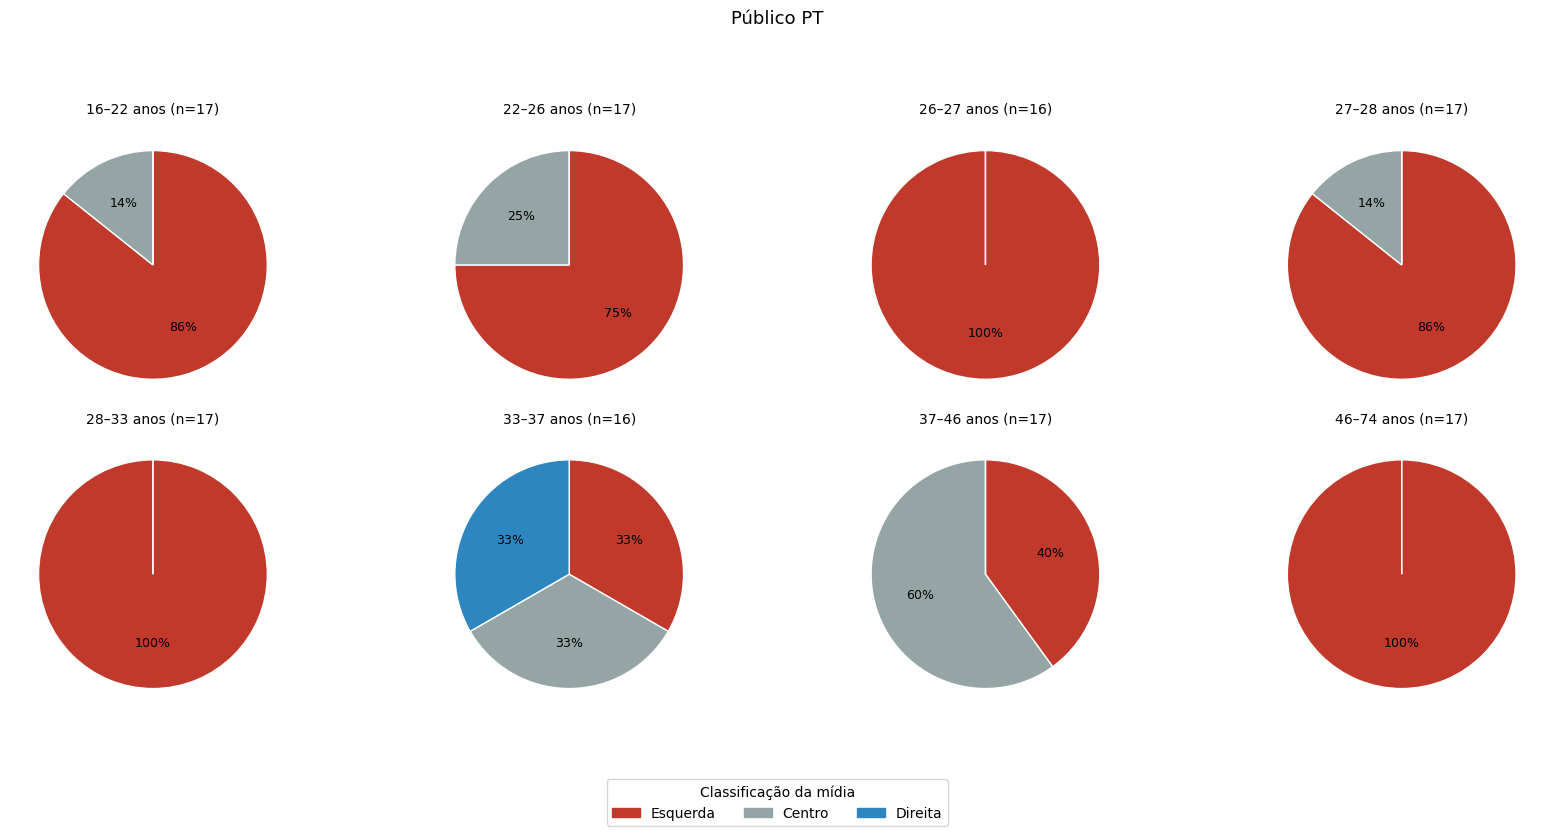

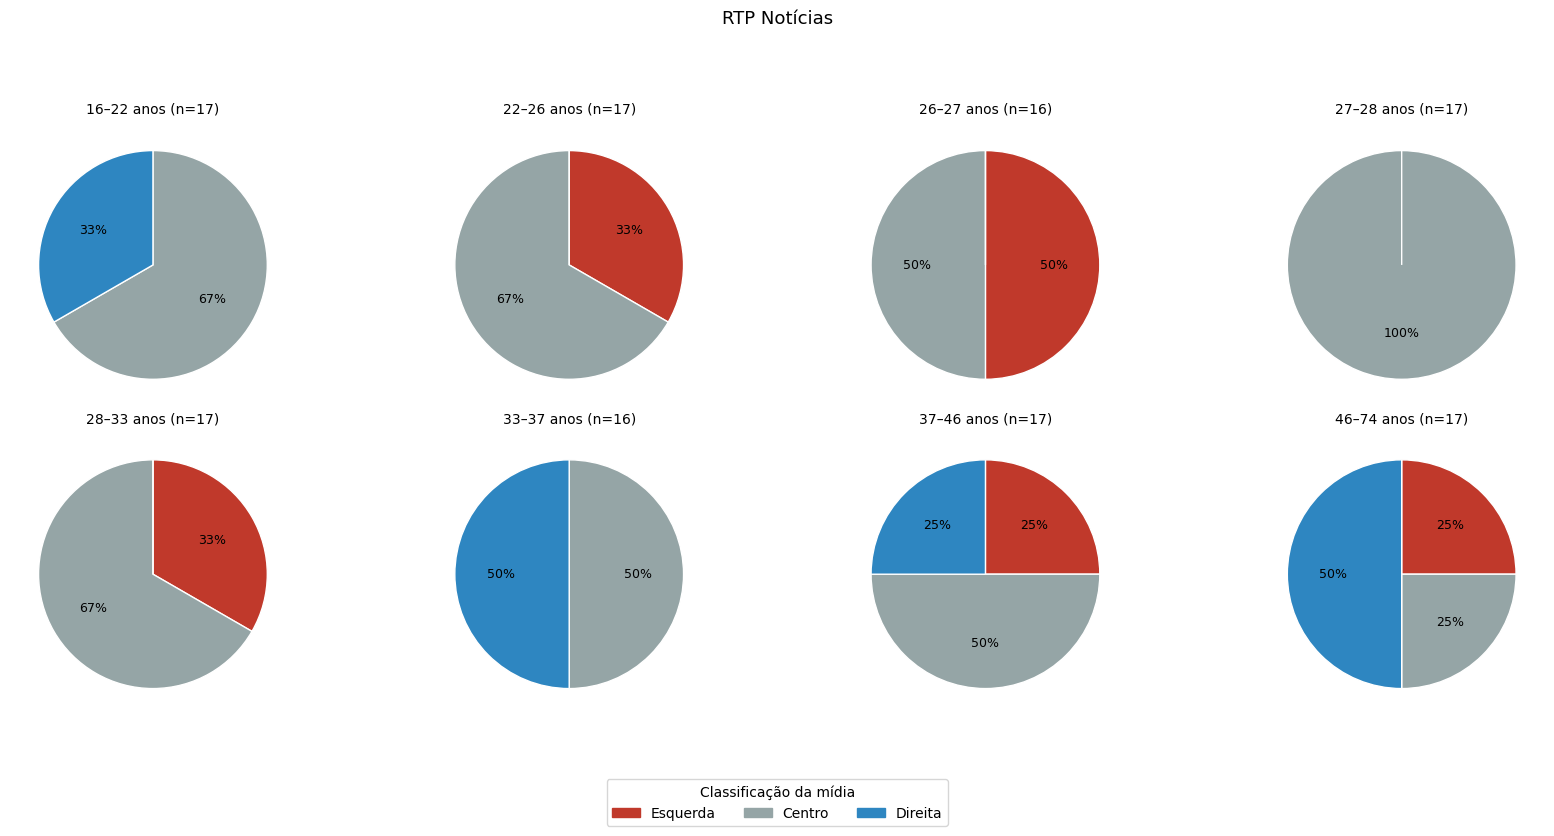

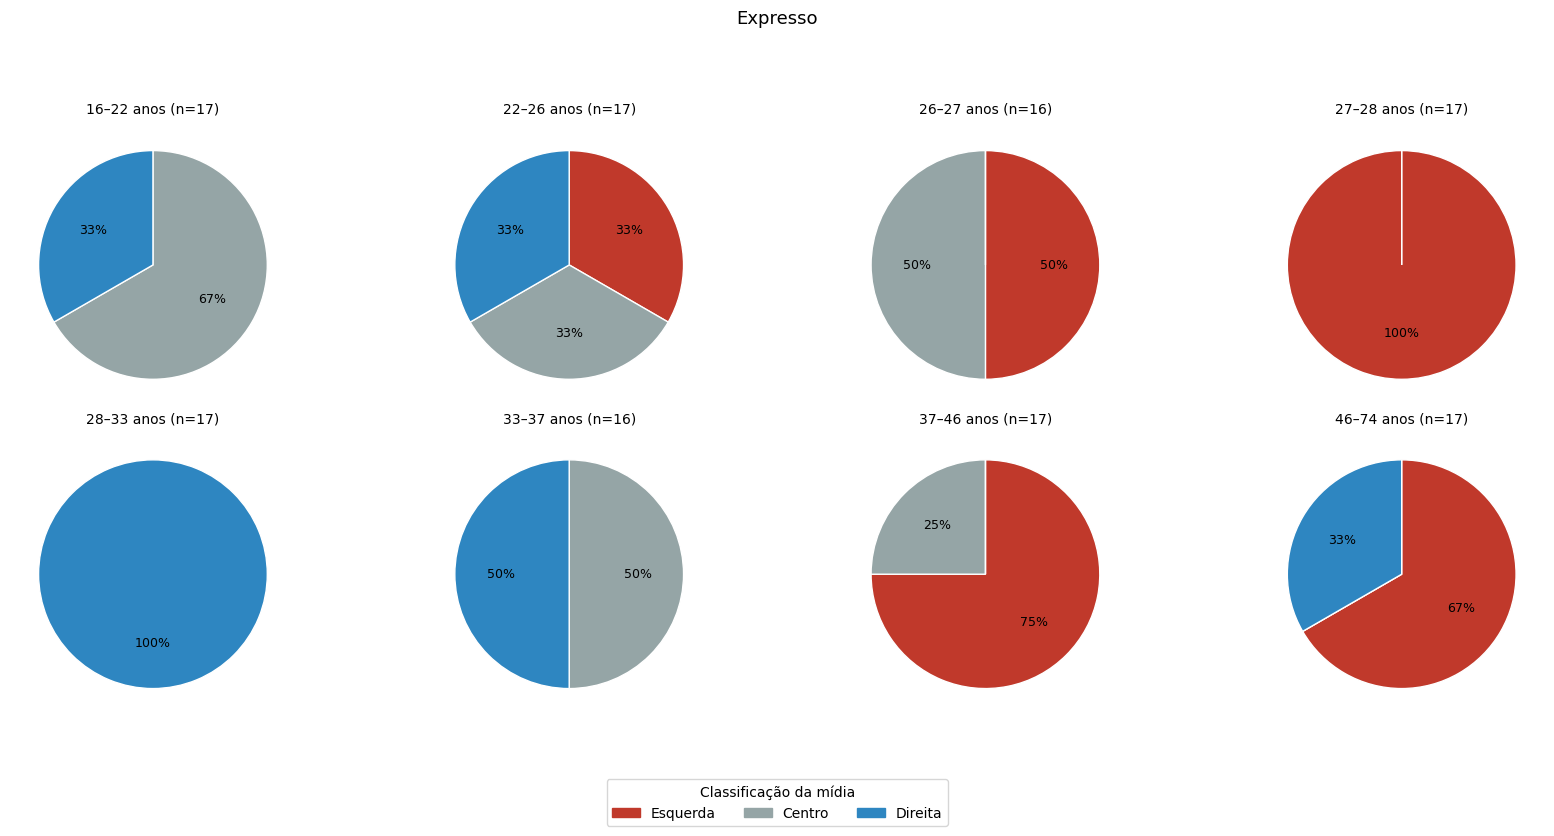

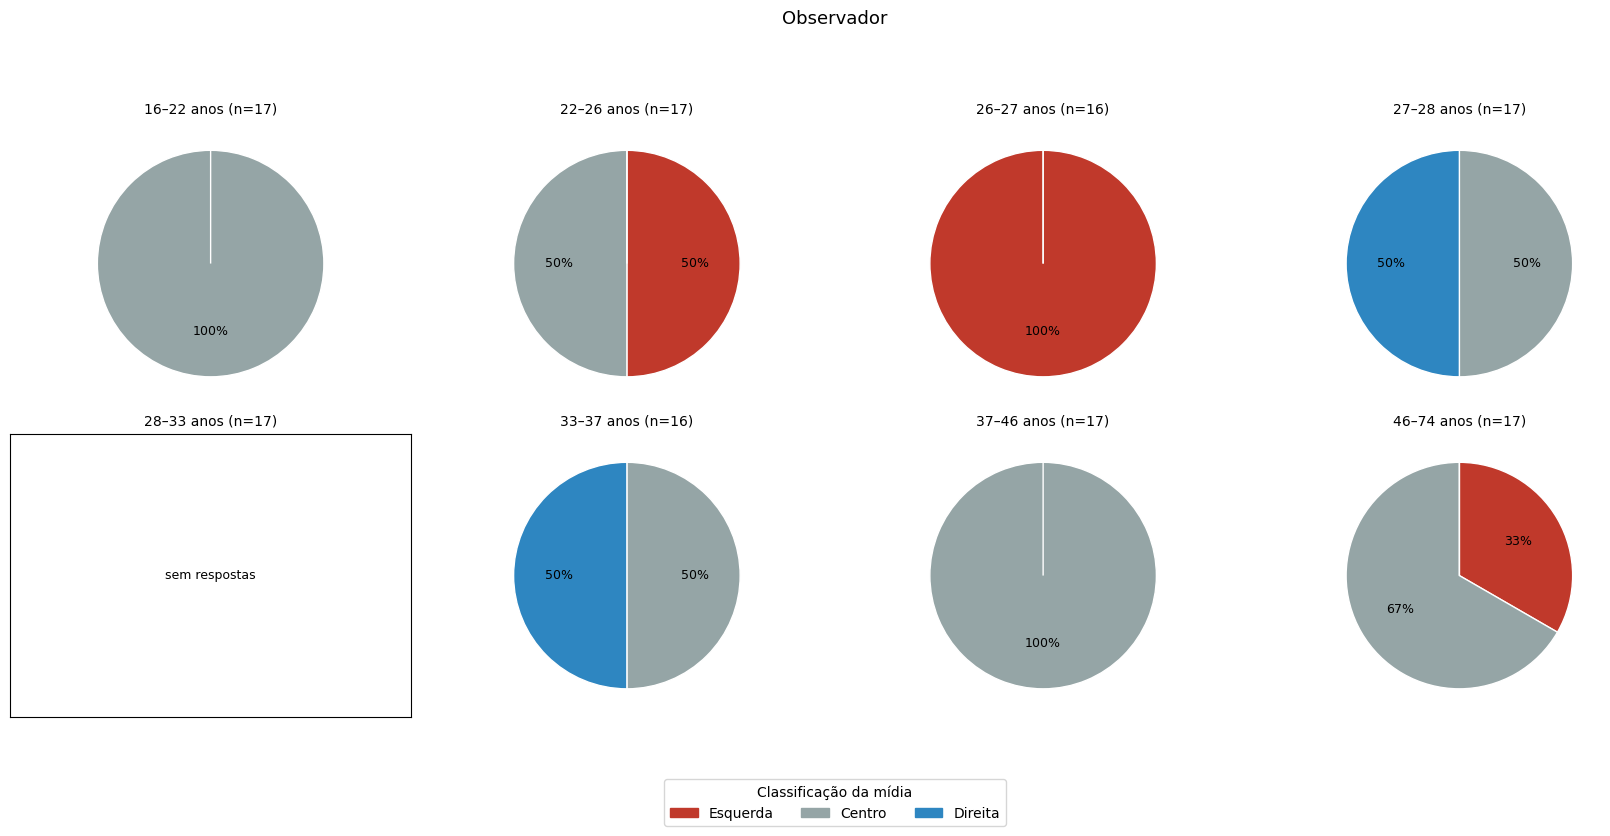

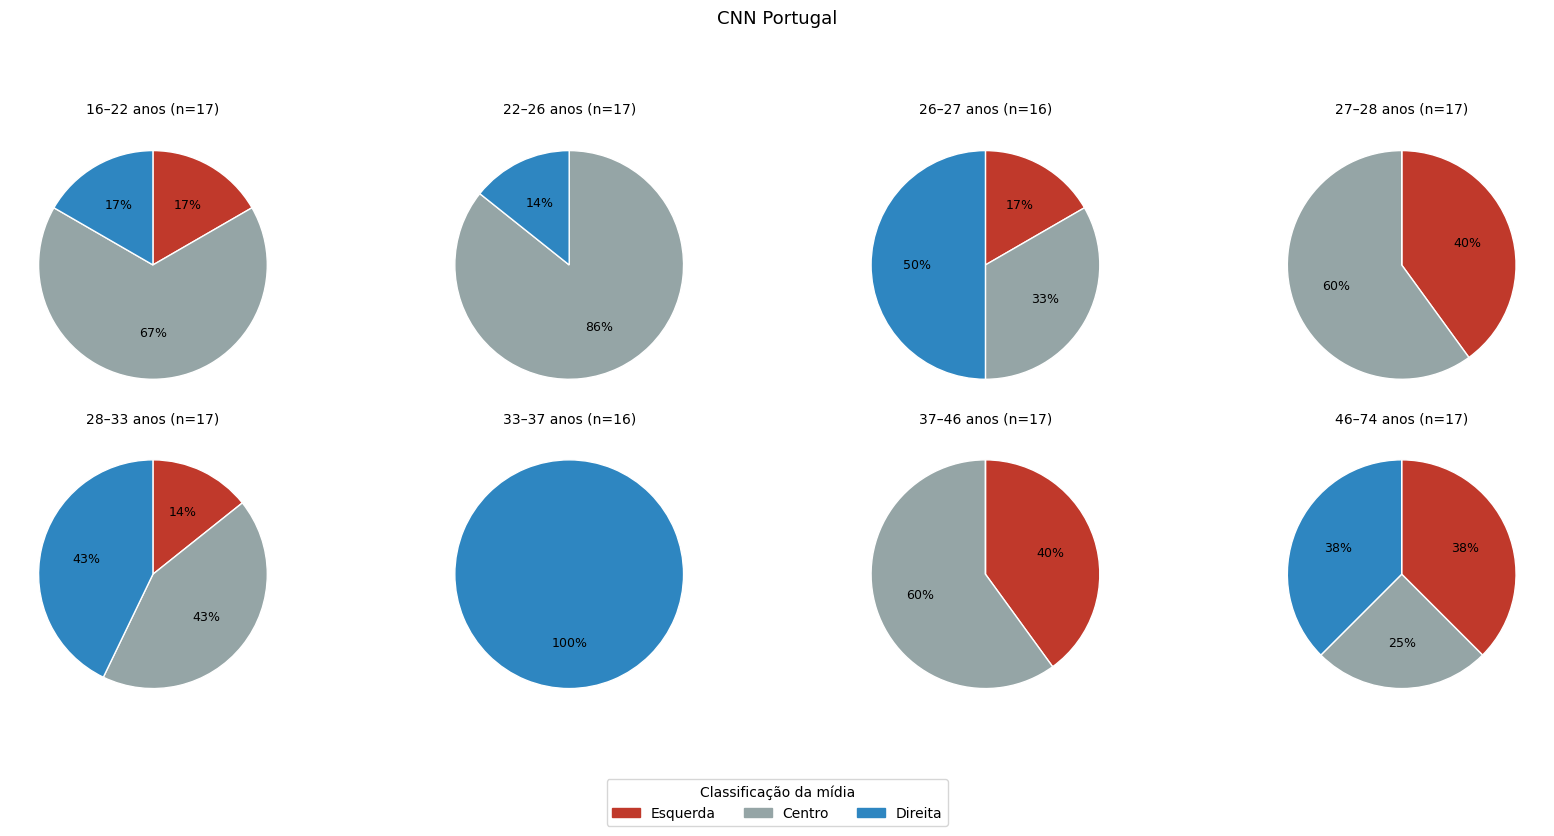

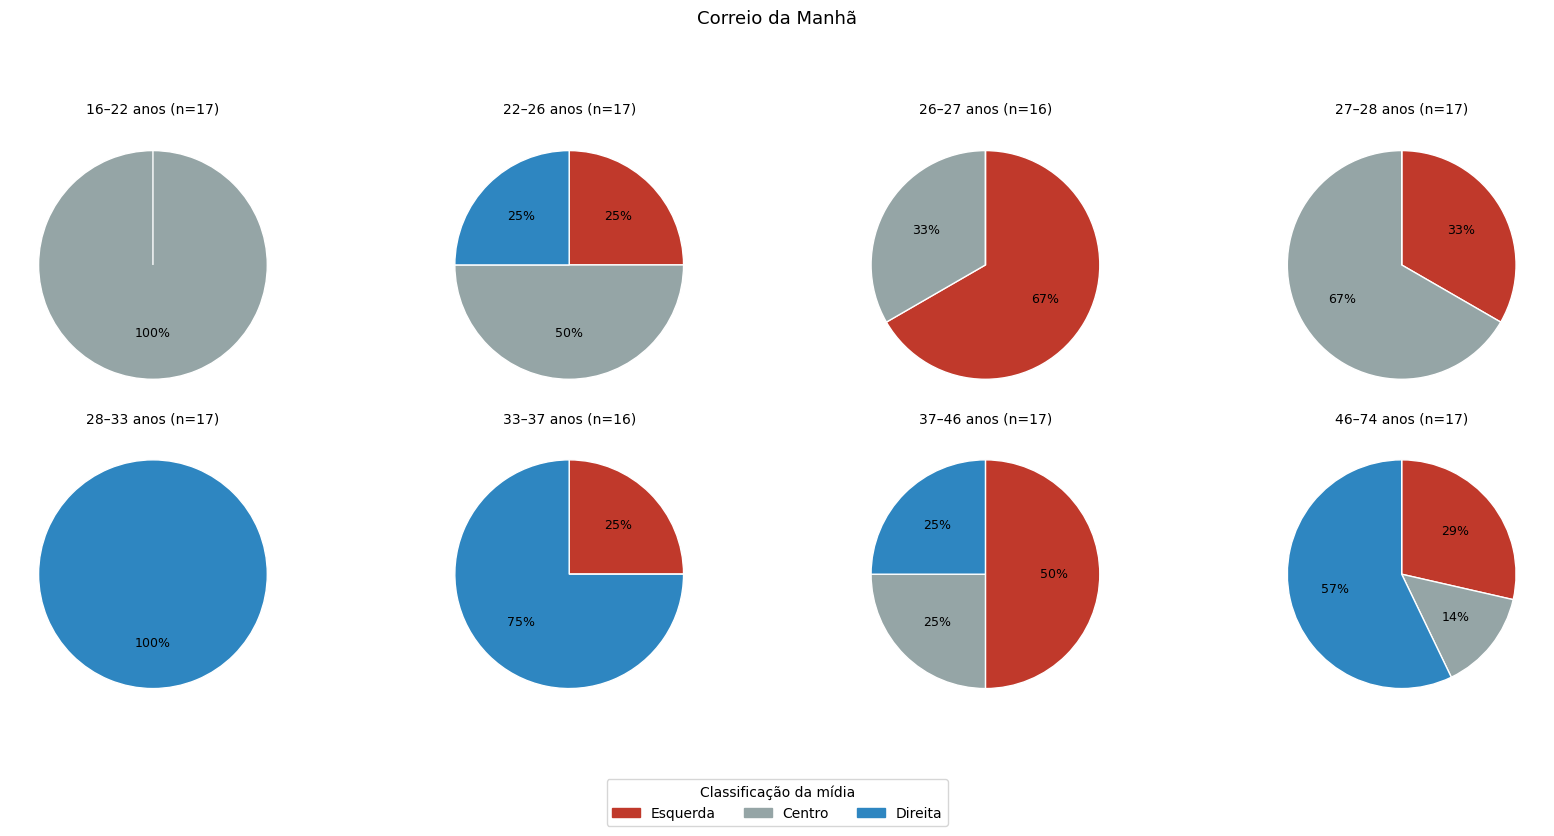

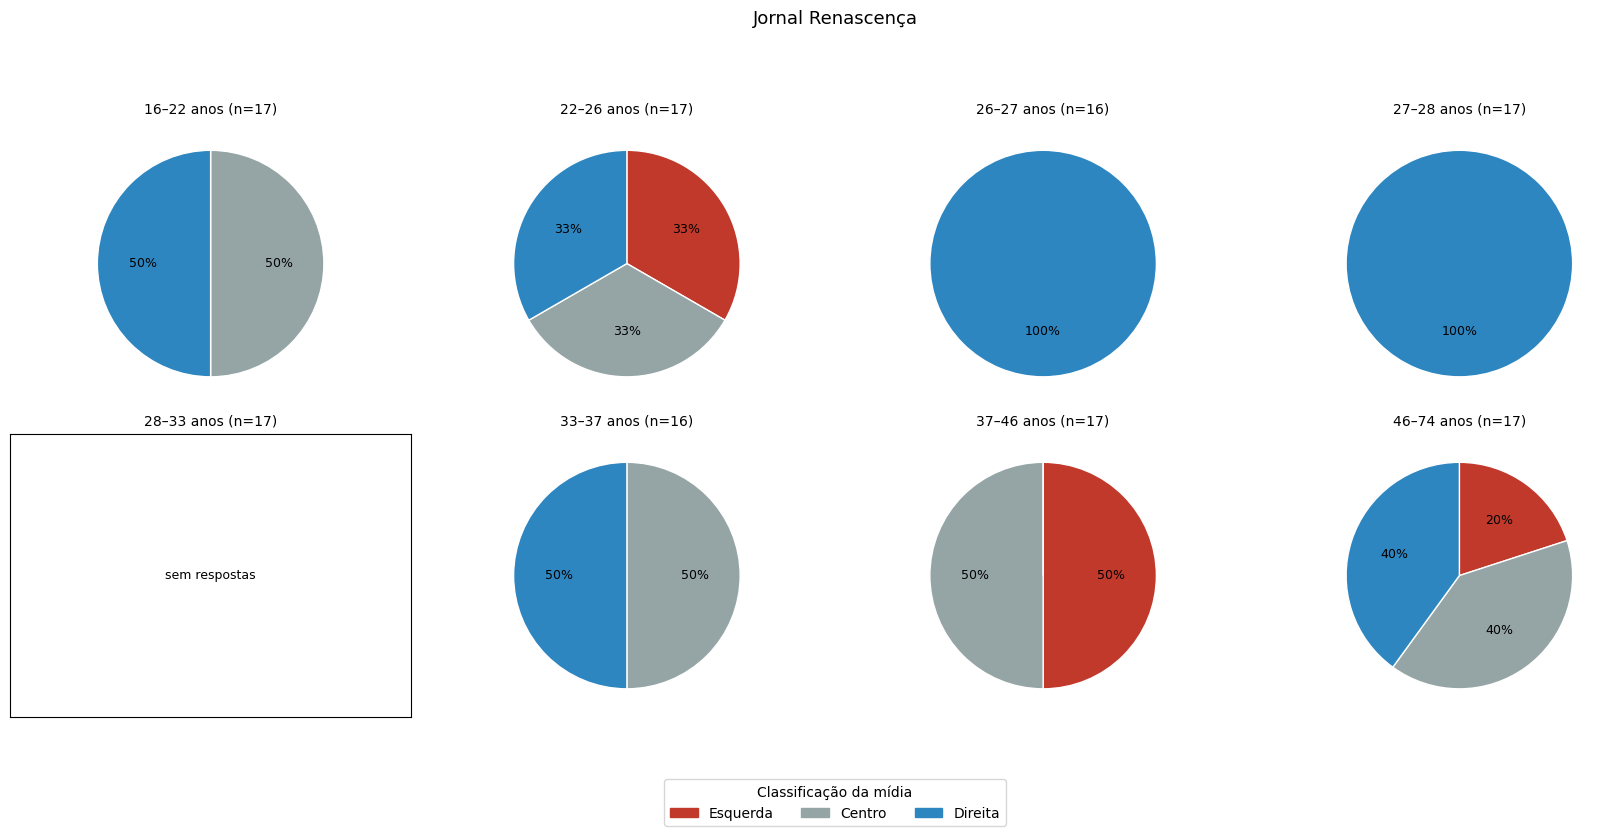

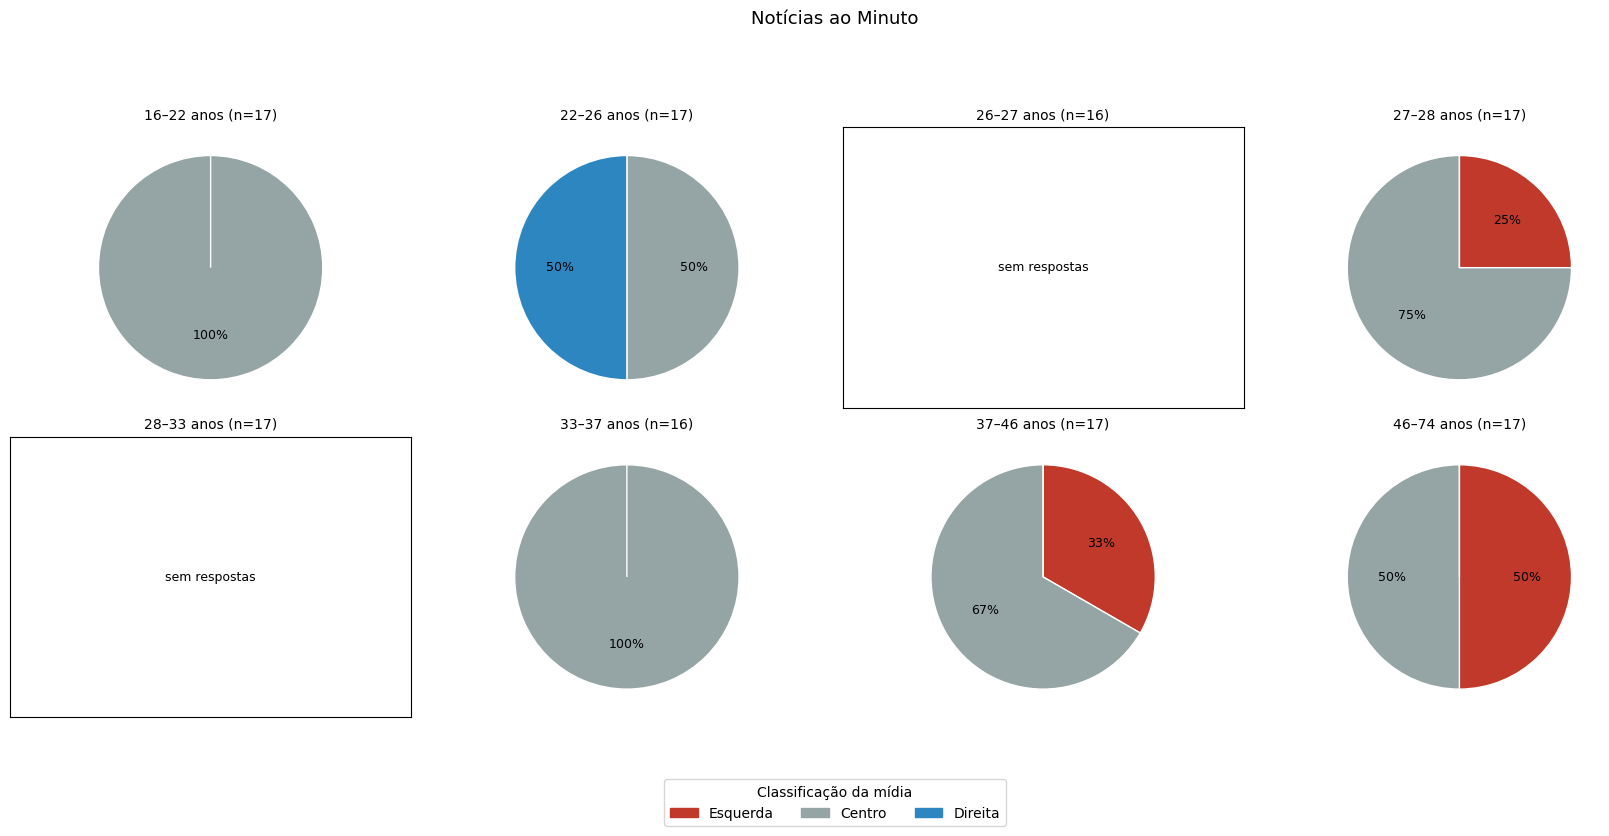

In [13]:
# Faixas etarias com tamanhos aproximadamente iguais (quantis por posicao)
N_FAIXAS = 8
RATINGS = ["Esquerda", "Centro", "Direita"]
ranks = enquete["Idade"].rank(method="first")  # desempata idades repetidas
faixa_idx = pd.qcut(ranks, q=N_FAIXAS, labels=False)
faixas = {i: f"{int(enquete.loc[faixa_idx == i, 'Idade'].min())}–{int(enquete.loc[faixa_idx == i, 'Idade'].max())} anos"
          for i in range(N_FAIXAS)}
enquete["Faixa etaria"] = faixa_idx.map(faixas)
ordem = list(faixas.values())

# pcts_idade[faixa]: linhas = midias, colunas = avaliacao (proporcao dentro da faixa)
pcts_idade = {}
for f in ordem:
    sub = enquete[enquete["Faixa etaria"] == f]
    pcts_idade[f] = pd.DataFrame({c: sub[c].value_counts(normalize=True).reindex(RATINGS, fill_value=0)
                                  for c in cols}).T

# Visualizacao sugerida por IA
colors = {"Esquerda": "#c0392b", "Centro": "#95a5a6", "Direita": "#2e86c1"}
handles = [Patch(color=colors[s], label=s) for s in RATINGS]

NCOLS = min(N_FAIXAS, 4)  # grade de no maximo 4 colunas, para que cada grafico fique grande
NROWS = -(-N_FAIXAS // NCOLS)  # divisao com arredondamento para cima

def plot_media_idade(c):
    fig, axes = plt.subplots(NROWS, NCOLS, figsize=(NCOLS * 4.2, NROWS * 4.2), squeeze=False)
    axes = axes.flatten()
    for ax in axes[N_FAIXAS:]:
        ax.set_visible(False)
    for ax, f in zip(axes, ordem):
        vals = pcts_idade[f].loc[c, RATINGS]
        n = int((enquete["Faixa etaria"] == f).sum())
        ax.set_title(f"{f} (n={n})", fontsize=10)
        if vals.sum() == 0:
            ax.text(0.5, 0.5, "sem respostas", ha="center", va="center", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
        else:
            ax.pie(vals, colors=[colors[s] for s in RATINGS],
                   autopct=lambda p: f"{p:.0f}%" if p >= 8 else "",
                   textprops={"fontsize": 9}, startangle=90, counterclock=False,
                   wedgeprops={"linewidth": 1, "edgecolor": "white"})
            ax.set_aspect("equal")
    fig.suptitle(full_names[c], fontsize=13)
    fig.legend(handles=handles, title="Classificação da mídia", loc="lower center",
               ncol=3, bbox_to_anchor=(0.5, 0.0))
    plt.tight_layout(rect=[0, 0.08 + 0.02 * NROWS, 1, 0.92])
    plt.show()

for c in cols:
    plot_media_idade(c)


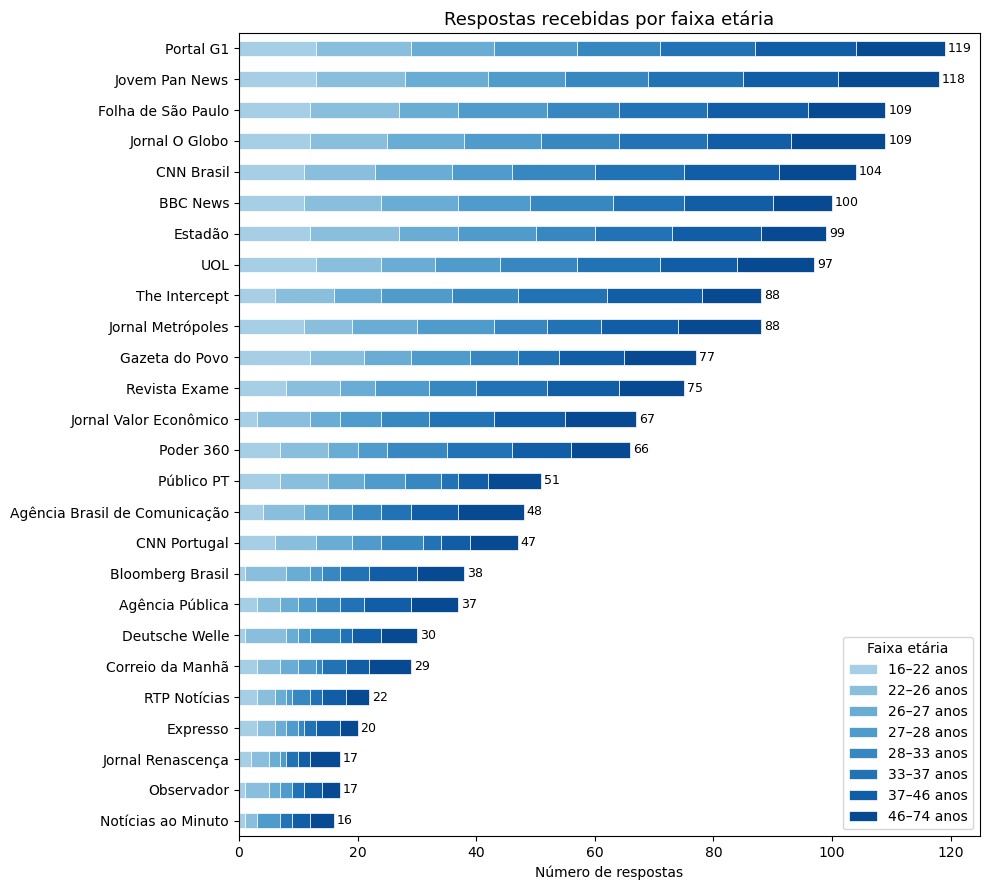

In [14]:
# Quantidade de respostas recebidas por faixa etaria, para cada midia
counts = pd.DataFrame({
    f: enquete.loc[enquete["Faixa etaria"] == f, cols].apply(lambda s: s.isin(RATINGS).sum())
    for f in ordem
})
counts.index = [full_names[c] for c in counts.index]
counts = counts.loc[counts.sum(axis=1).sort_values().index]  # midias com mais respostas no topo

fig, ax = plt.subplots(figsize=(10, 9))
counts.plot(kind="barh", stacked=True, ax=ax,
            color=plt.cm.Blues(np.linspace(0.35, 0.9, N_FAIXAS)),
            edgecolor="white", linewidth=0.5)
for i, total in enumerate(counts.sum(axis=1)):
    ax.text(total + 0.5, i, str(int(total)), va="center", fontsize=9)
ax.set_title("Respostas recebidas por faixa etária", fontsize=13)
ax.set_xlabel("Número de respostas")
ax.set_ylabel("")
ax.legend(title="Faixa etária", loc="lower right")
plt.tight_layout()
plt.show()


## Análise por região

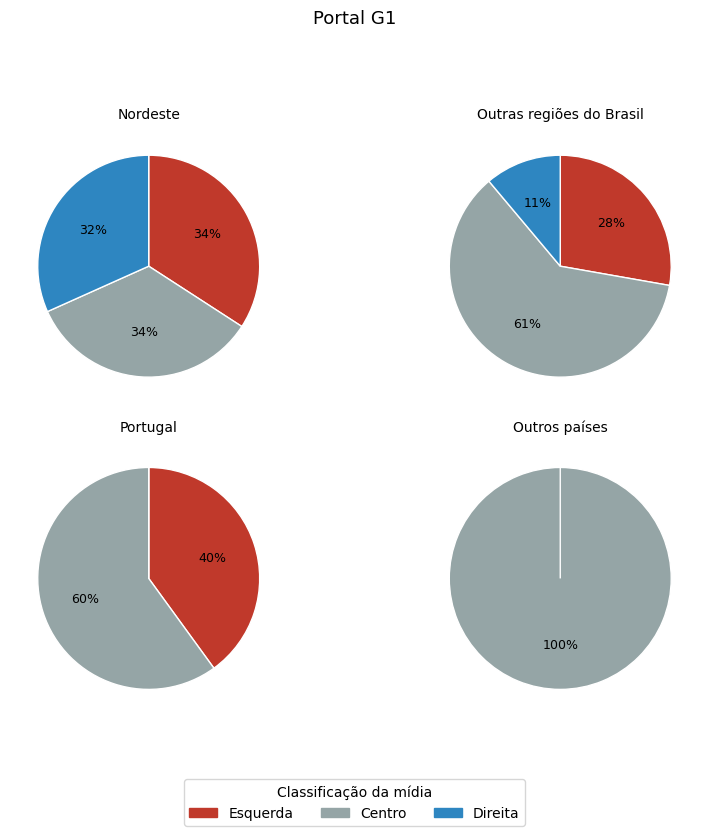

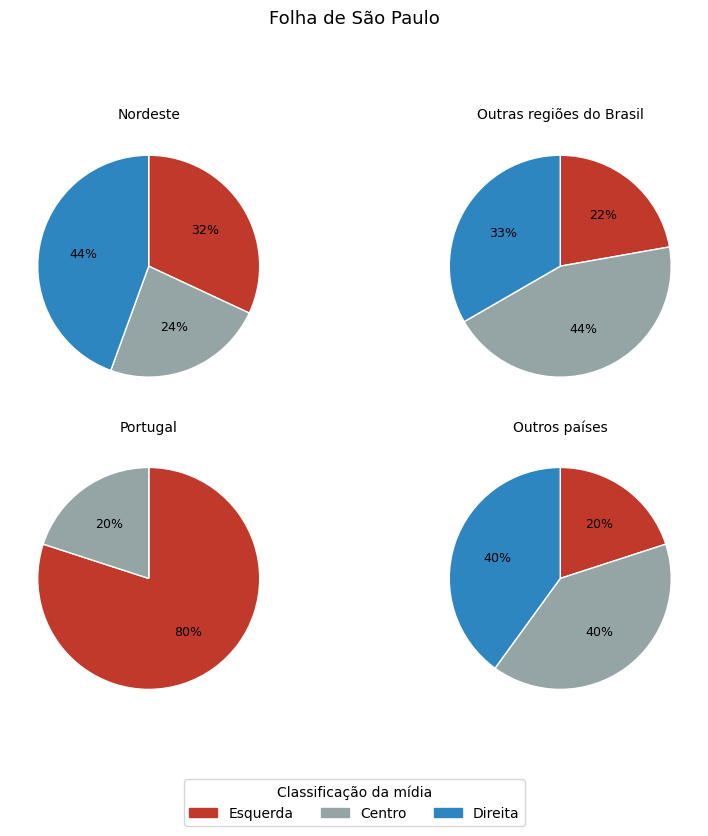

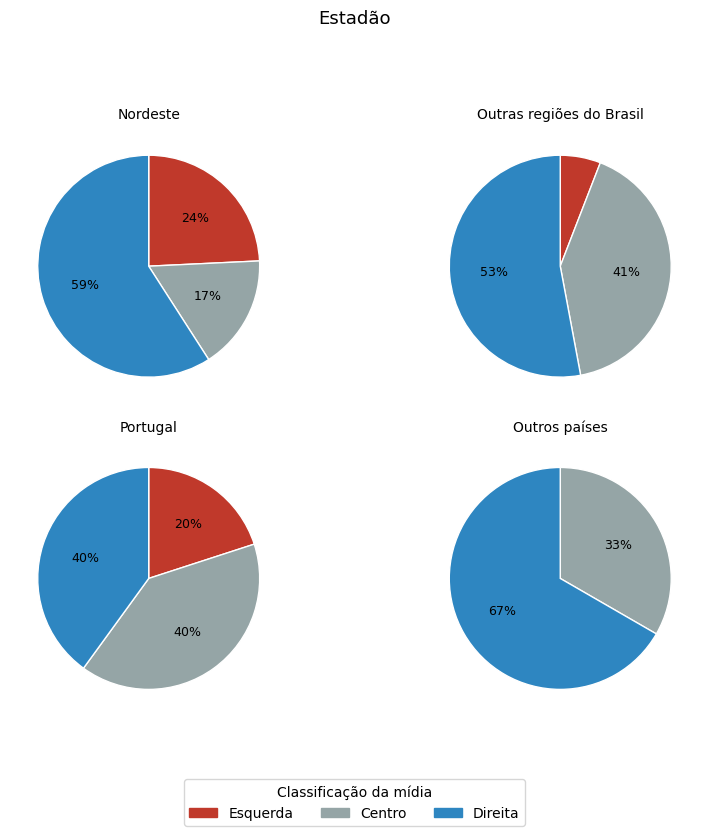

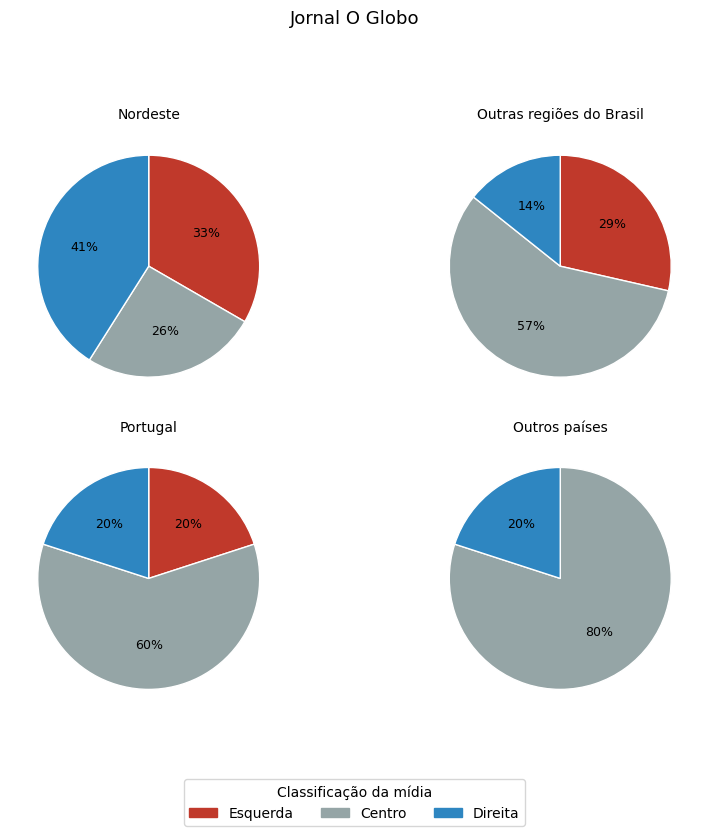

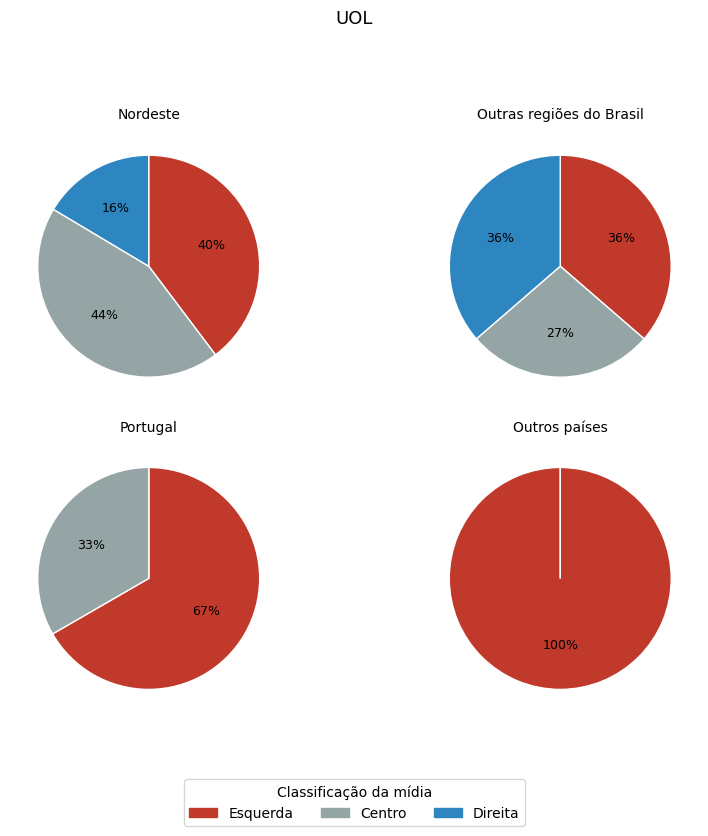

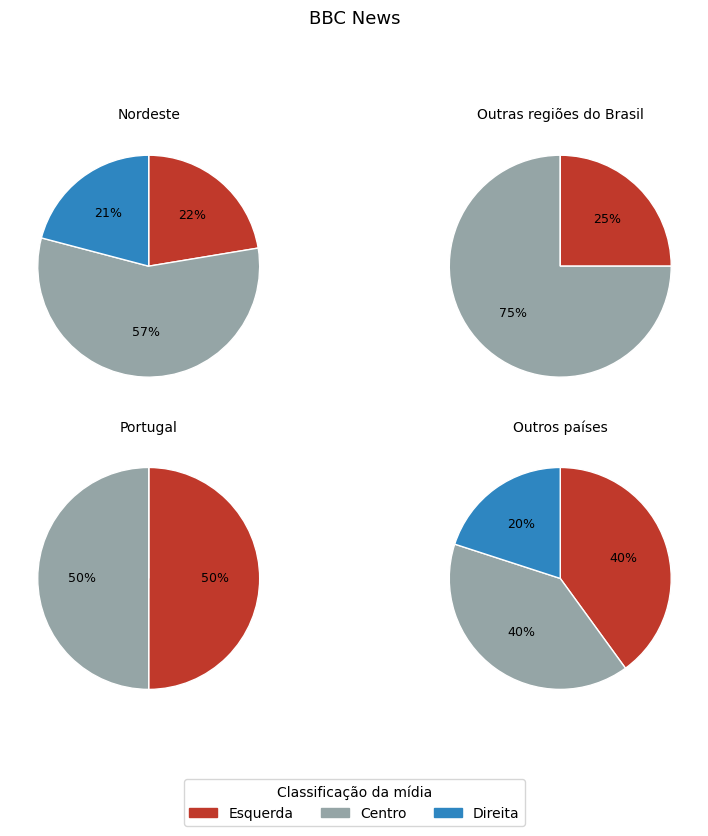

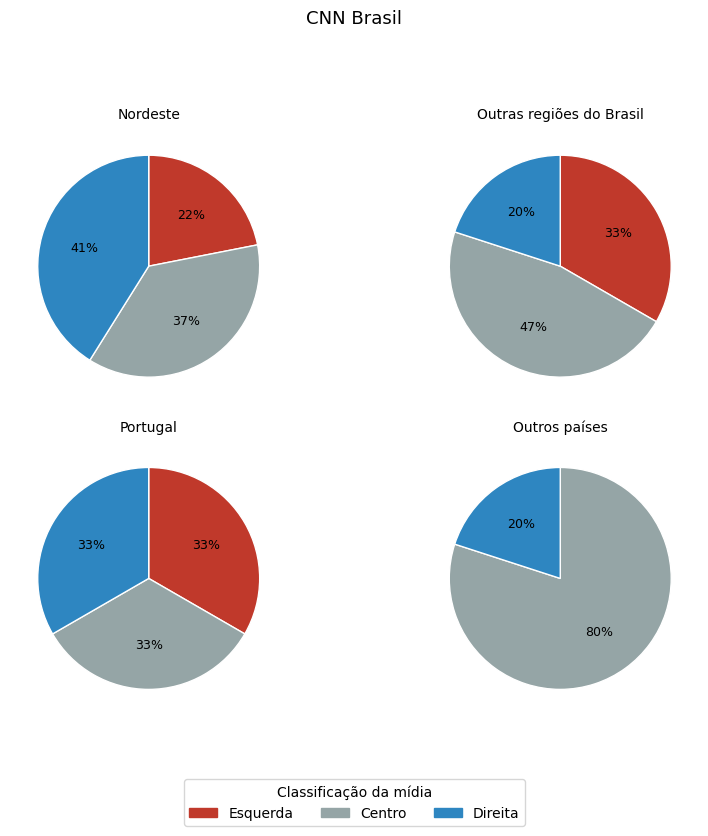

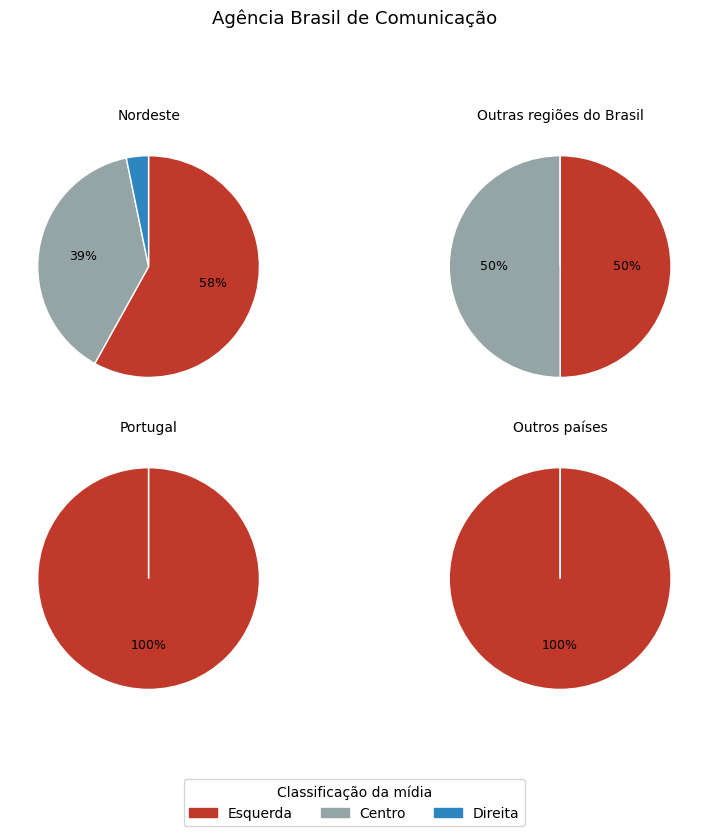

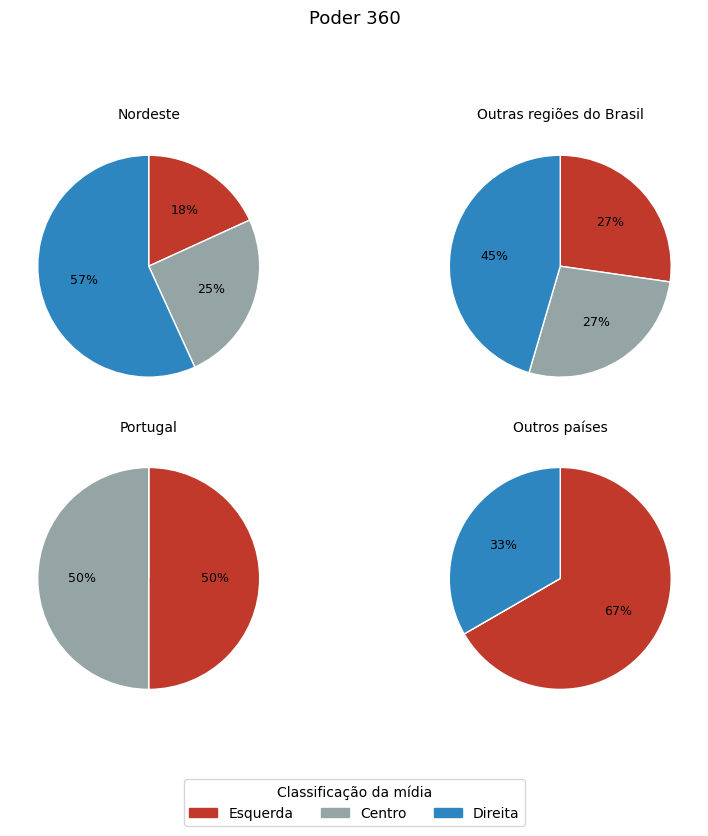

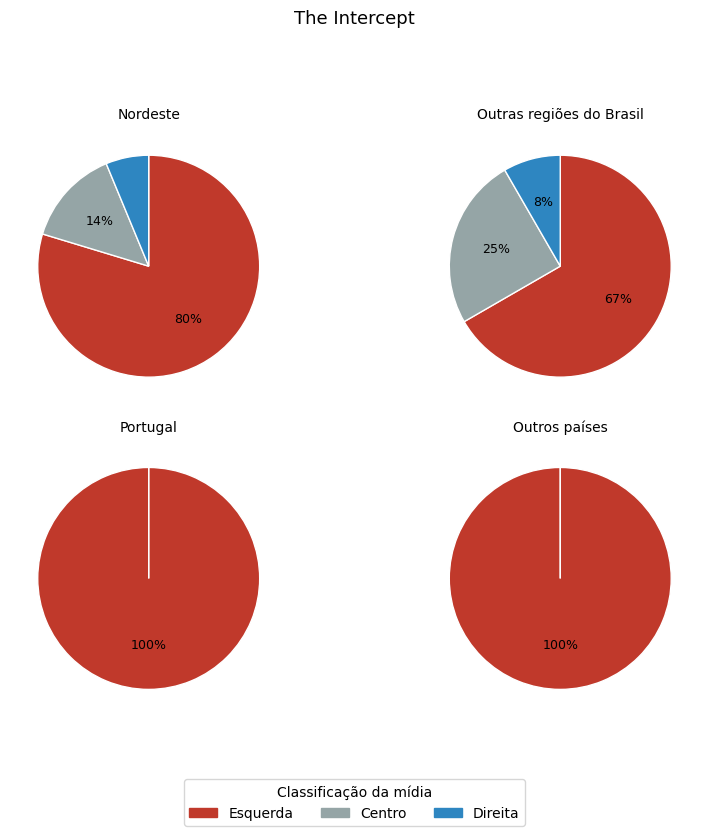

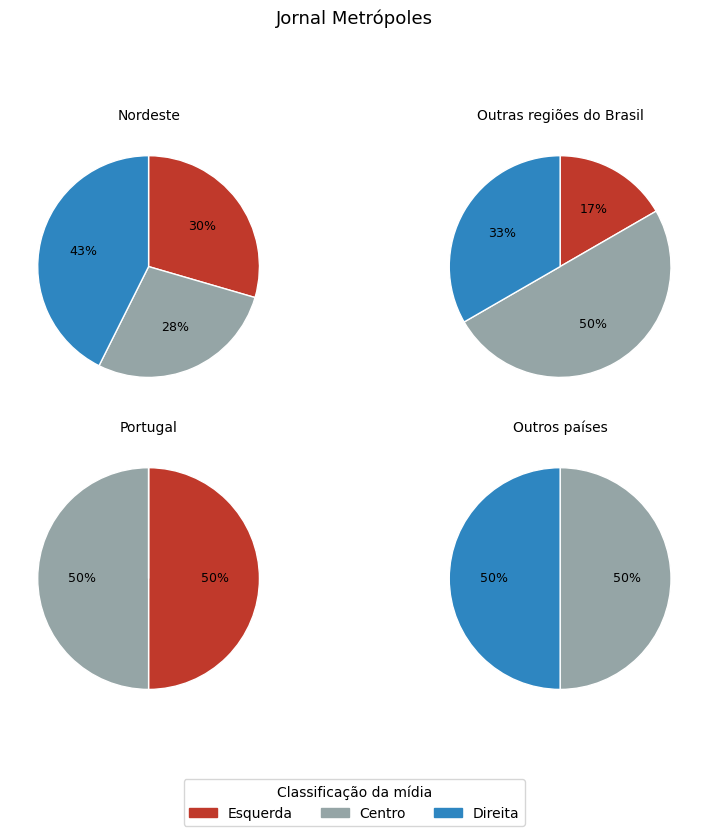

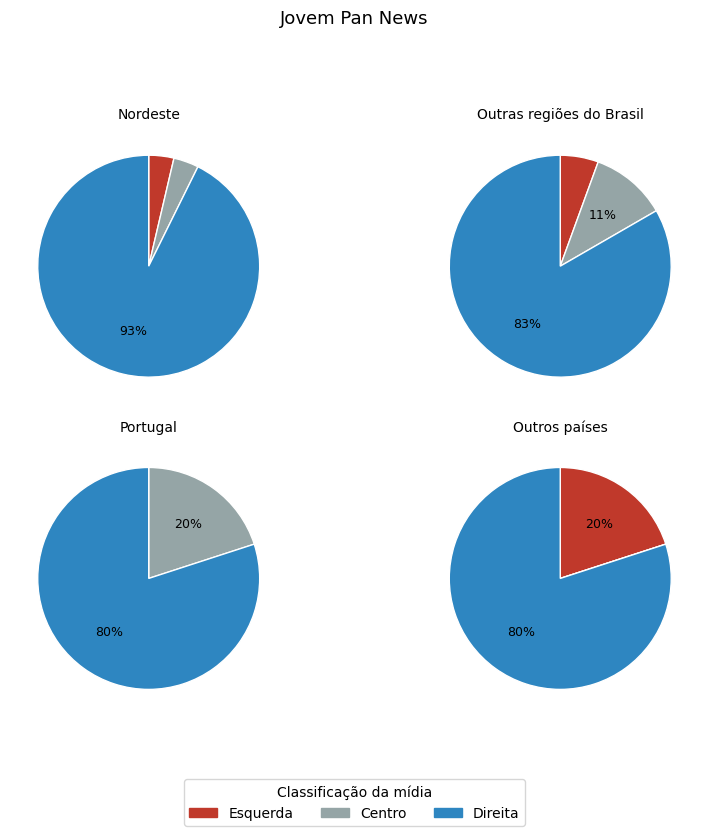

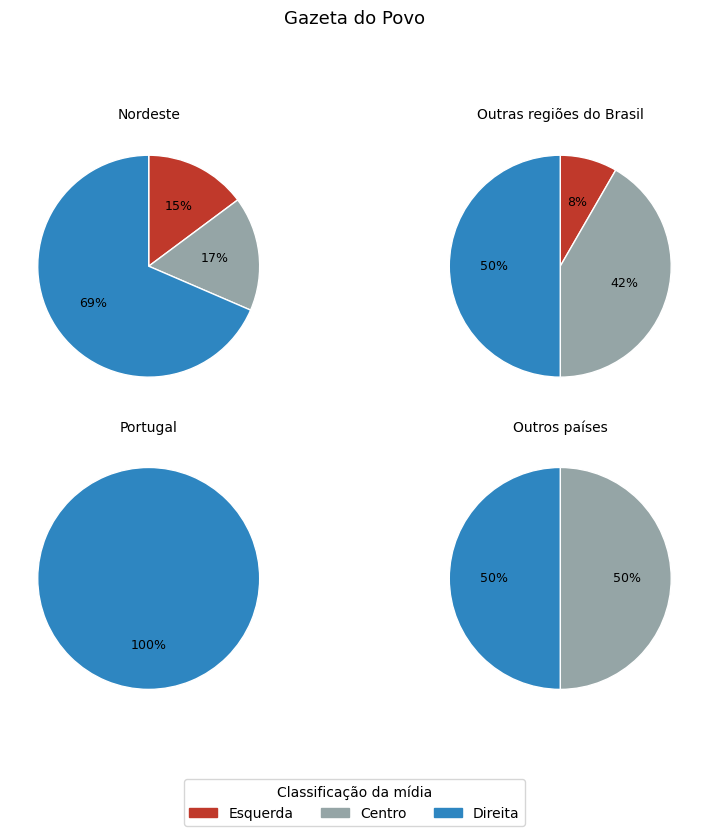

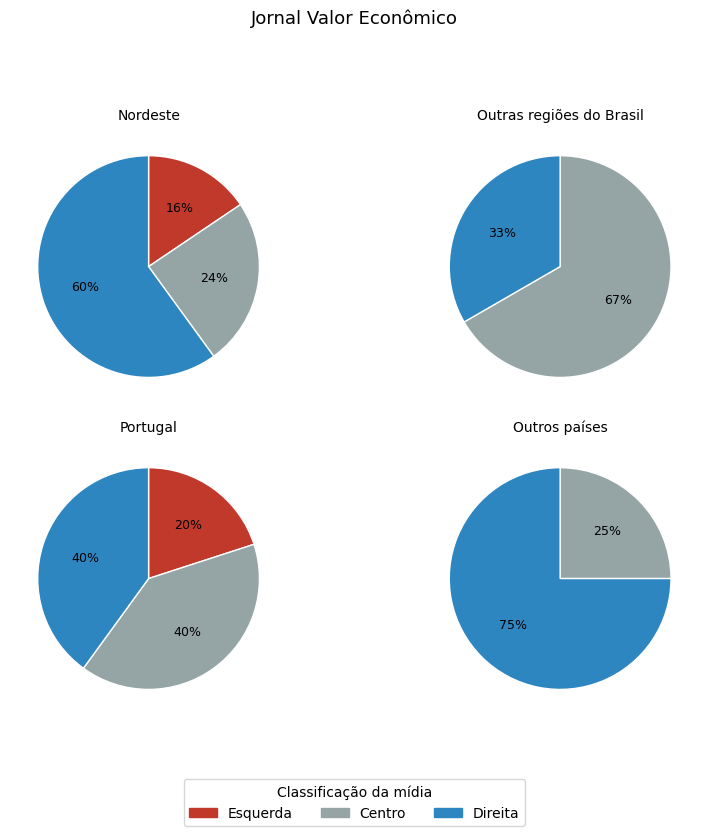

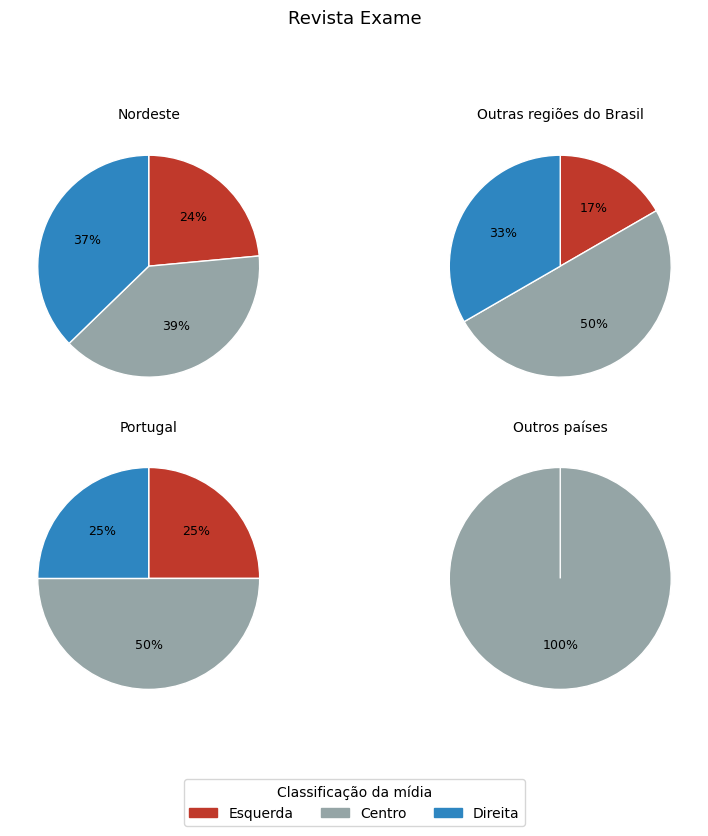

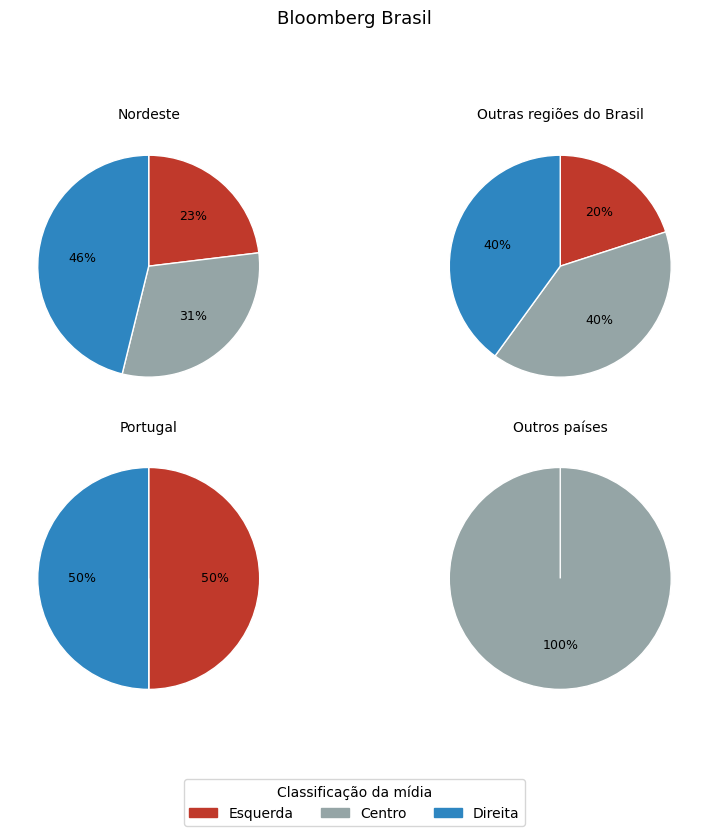

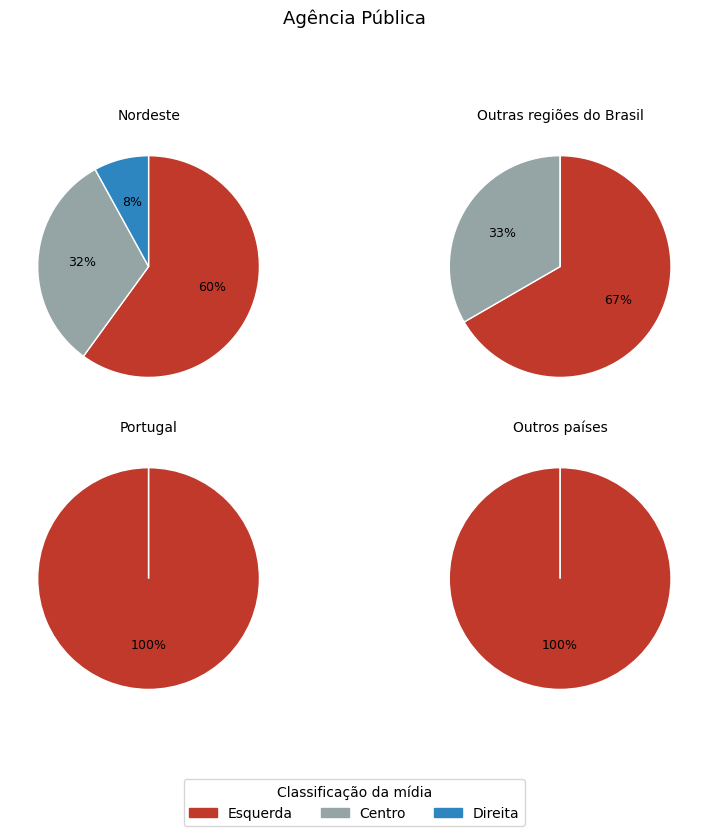

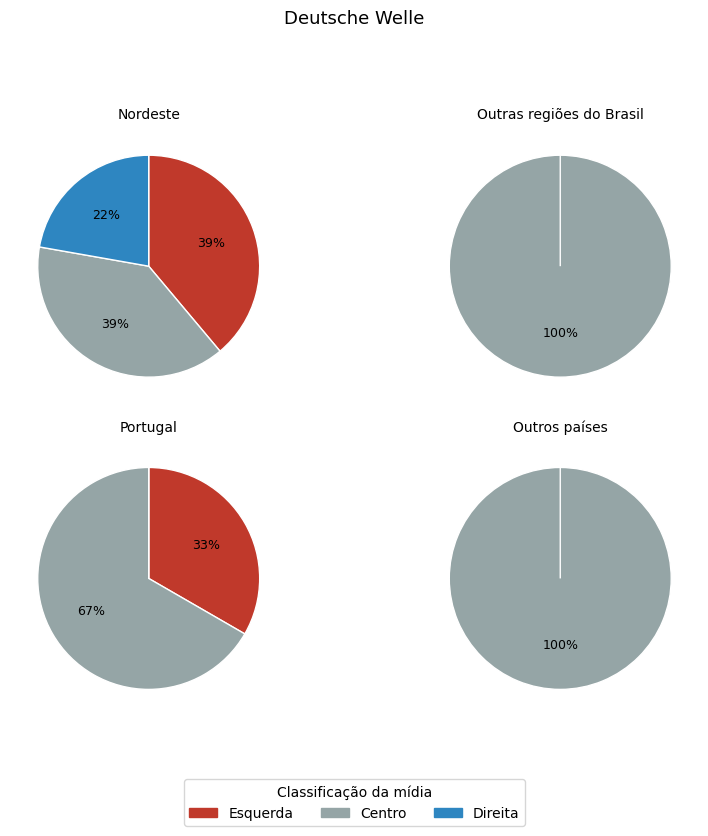

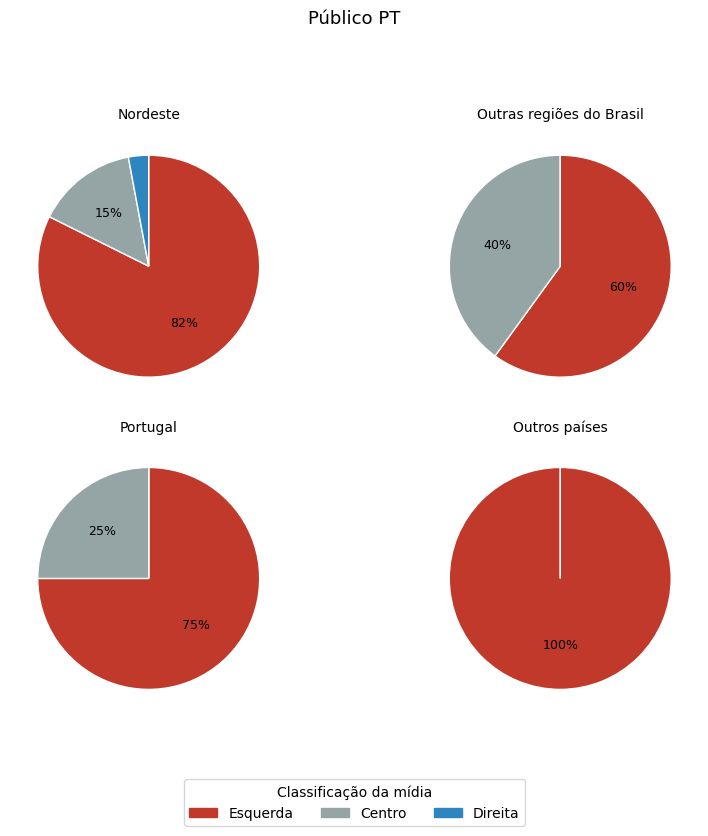

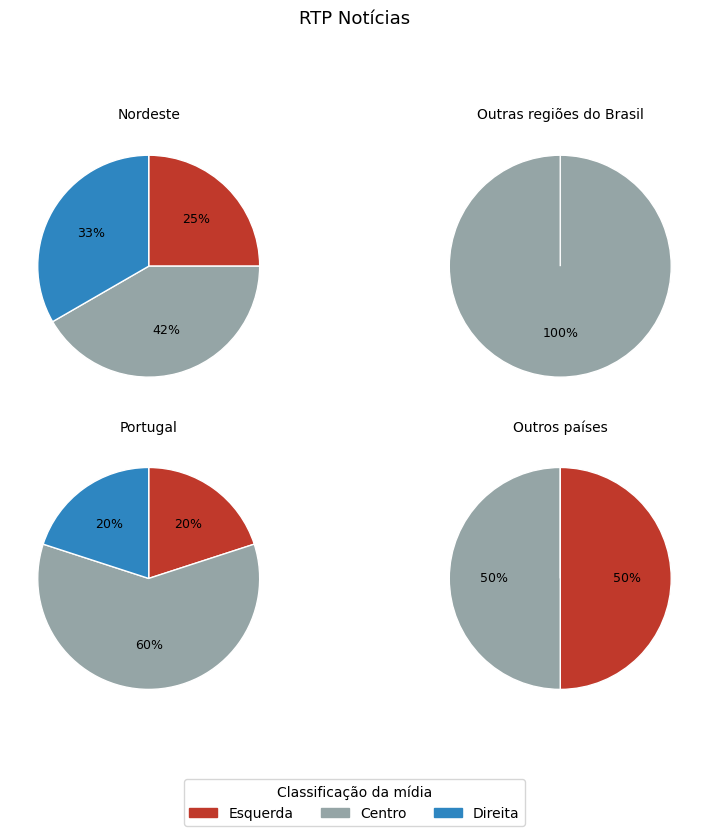

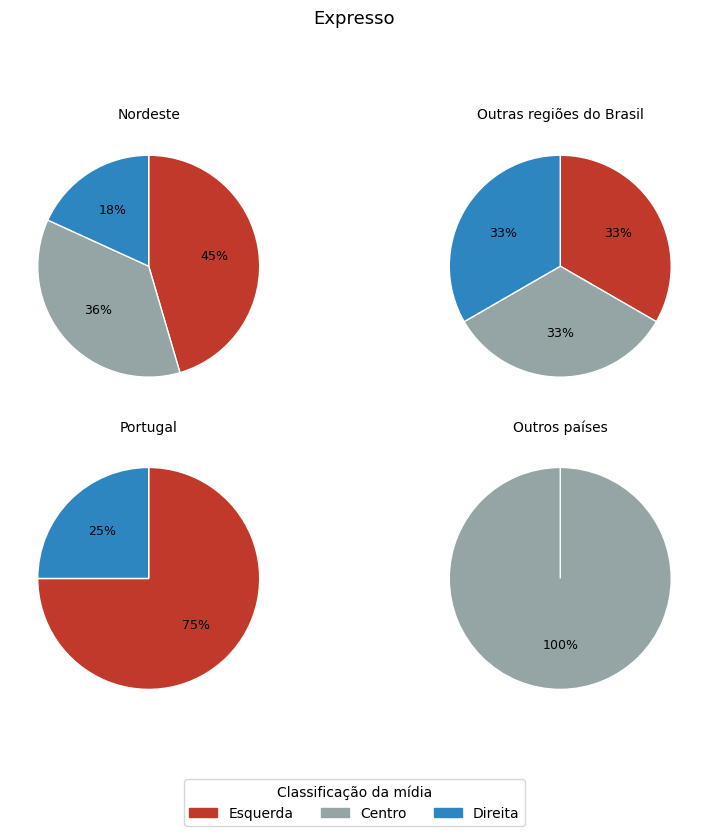

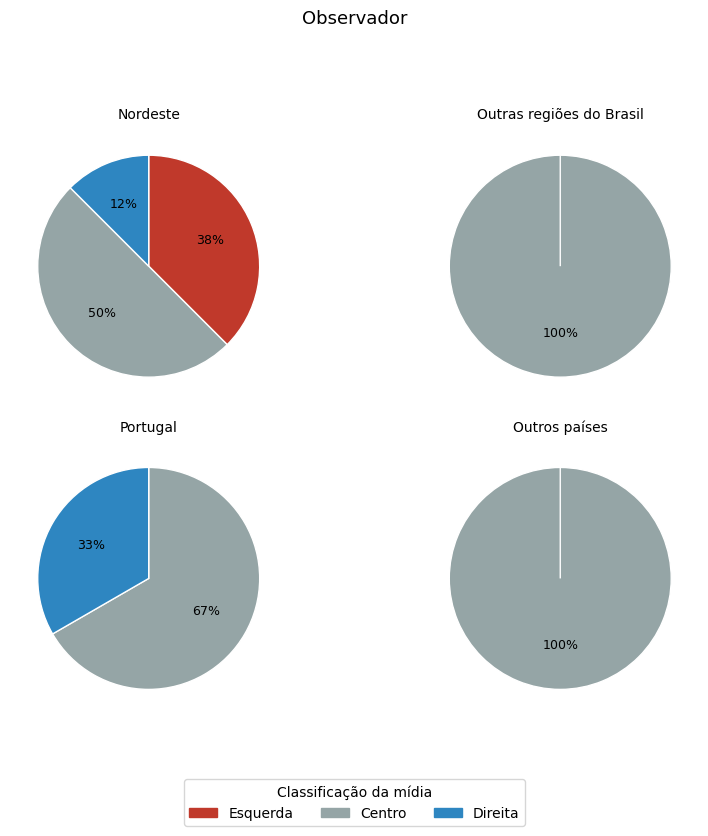

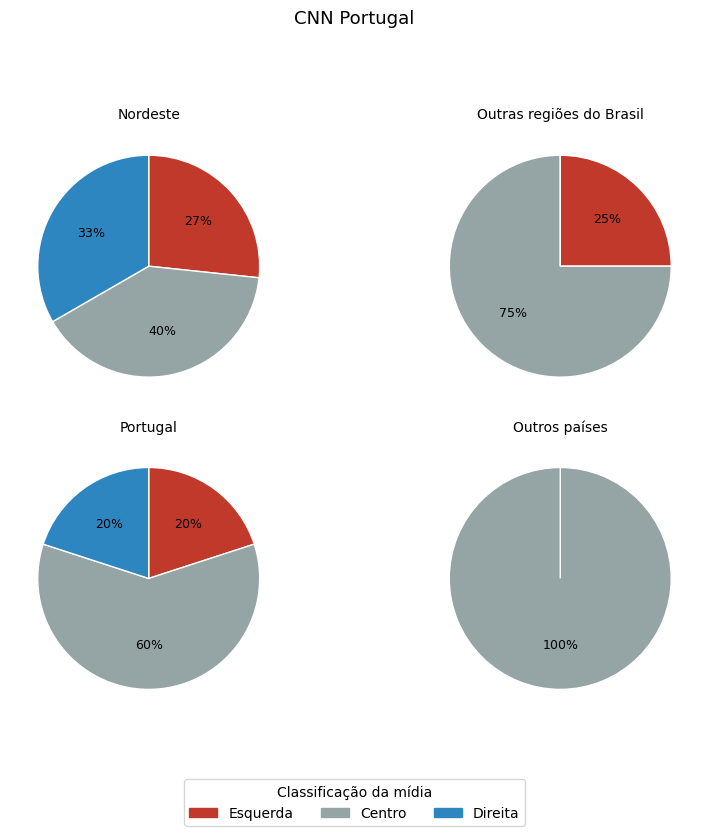

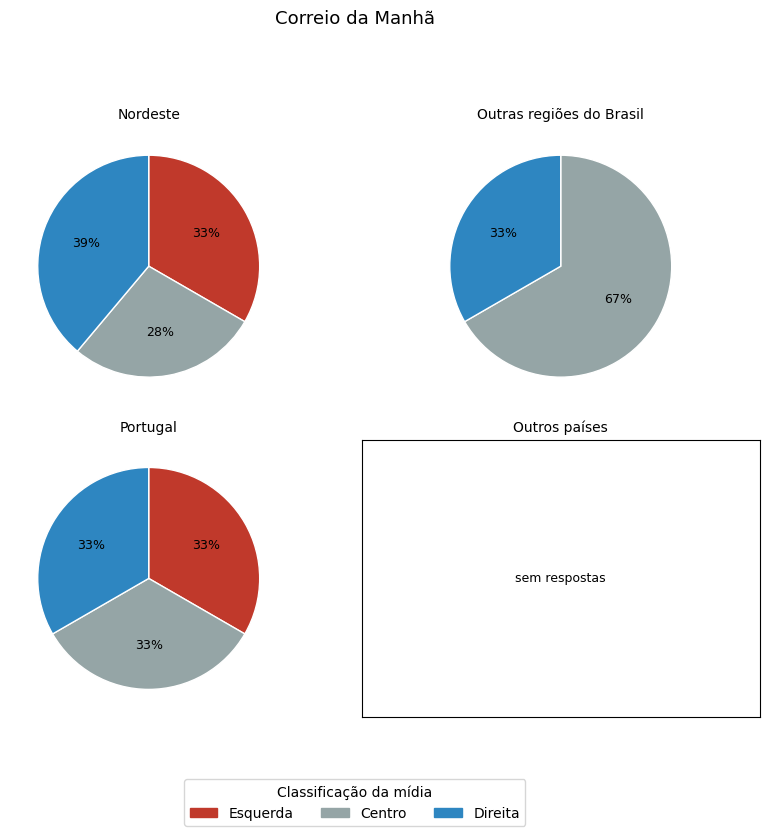

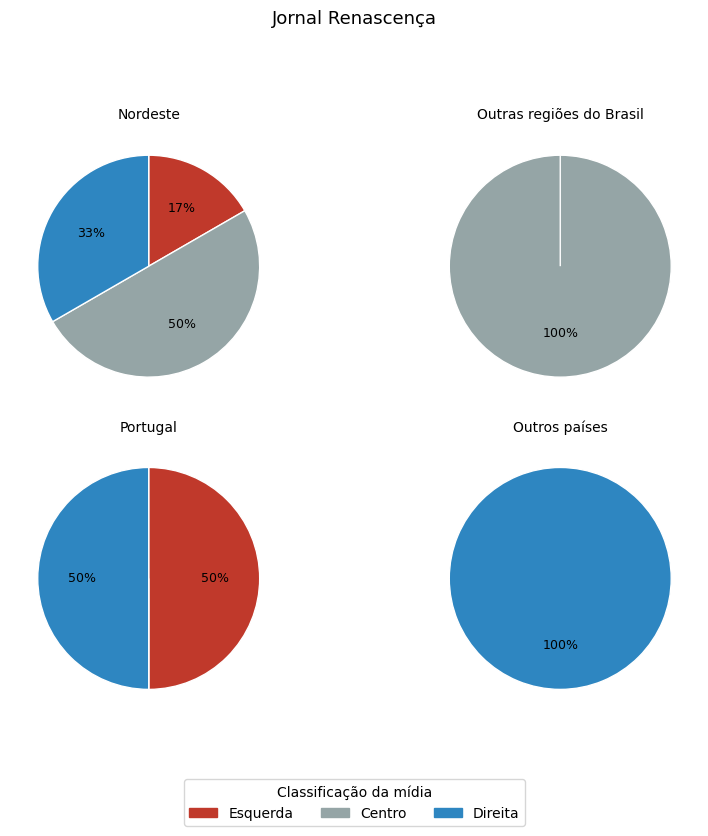

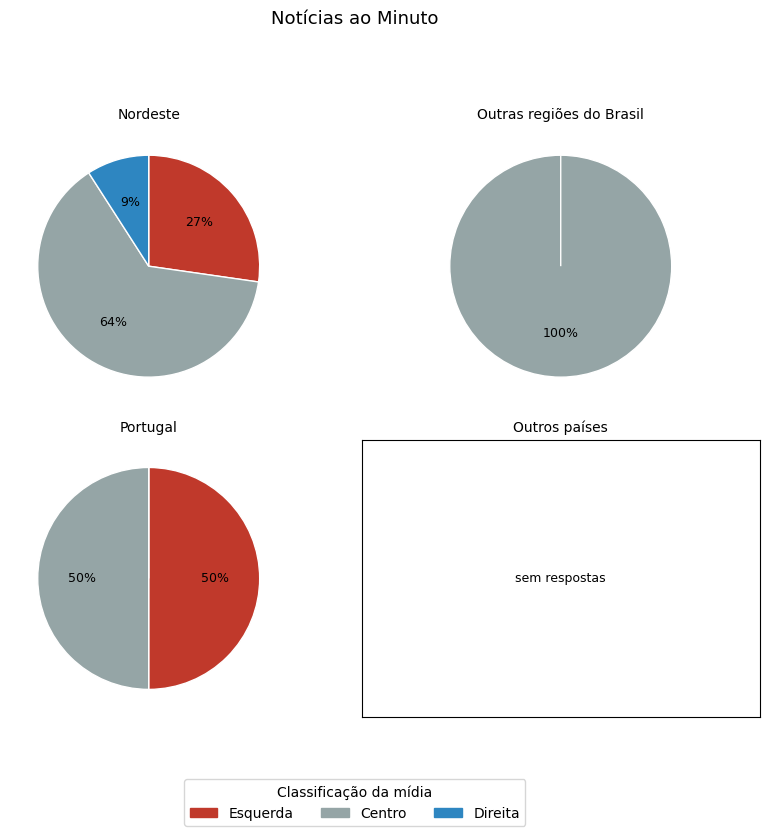

In [15]:
# Agrupamento de regiões (a maioria dos respondentes é do Nordeste, então grupos iguais não são possíveis)
REGIAO_GRUPO = {
    "Brasil (Nordeste)": "Nordeste",
    "Brasil (Sudeste)": "Outras regiões do Brasil",
    "Brasil (Sul)": "Outras regiões do Brasil",
    "Brasil (Centro-Oeste)": "Outras regiões do Brasil",
    "Brasil (Norte)": "Outras regiões do Brasil",
    "Portugal": "Portugal",
    "Europa": "Outros países",
    "América do Sul": "Outros países",
    "Ásia": "Outros países",
}
enquete["Grupo regiao"] = enquete["Regiao"].map(REGIAO_GRUPO)
ordem_regiao = ["Nordeste", "Outras regiões do Brasil", "Portugal", "Outros países"]
RATINGS = ["Esquerda", "Centro", "Direita"]

# pcts_regiao[grupo]: linhas = midias, colunas = avaliacao (proporcao dentro do grupo)
pcts_regiao = {}
for g_ in ordem_regiao:
    sub = enquete[enquete["Grupo regiao"] == g_]
    pcts_regiao[g_] = pd.DataFrame({c: sub[c].value_counts(normalize=True).reindex(RATINGS, fill_value=0)
                                    for c in cols}).T

NCOLS = 2  # grade 2x2 para que cada gráfico fique grande
NROWS = -(-len(ordem_regiao) // NCOLS)

def plot_media_regiao(c):
    fig, axes = plt.subplots(NROWS, NCOLS, figsize=(NCOLS * 4.2, NROWS * 4.2), squeeze=False)
    axes = axes.flatten()
    for ax in axes[len(ordem_regiao):]:
        ax.set_visible(False)
    for ax, g_ in zip(axes, ordem_regiao):
        vals = pcts_regiao[g_].loc[c, RATINGS]
        n = int((enquete["Grupo regiao"] == g_).sum())
        ax.set_title(f"{g_}", fontsize=10)
        if vals.sum() == 0:
            ax.text(0.5, 0.5, "sem respostas", ha="center", va="center", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
        else:
            ax.pie(vals, colors=[colors[s] for s in RATINGS],
                   autopct=lambda p: f"{p:.0f}%" if p >= 8 else "",
                   textprops={"fontsize": 9}, startangle=90, counterclock=False,
                   wedgeprops={"linewidth": 1, "edgecolor": "white"})
            ax.set_aspect("equal")
    fig.suptitle(full_names[c], fontsize=13)
    fig.legend(handles=handles, title="Classificação da mídia", loc="lower center",
               ncol=3, bbox_to_anchor=(0.5, 0.0))
    plt.tight_layout(rect=[0, 0.08 + 0.02 * NROWS, 1, 0.92])
    plt.show()

for c in cols:
    plot_media_regiao(c)


----
# 4. Sugestão de classificação dos meios de comunicação
- [x] Normalização das classificações por espectros (como se houvesse uma única resposta por espectro, usando ela como base para a classificação), usando os dados em -1, 0 e 1
- [x] Usar esses dados com thresholds para reclassificação dos meios de comunicação
- [x] Ver uma comparação entre as opiniões por espectro político e o veredito dado 

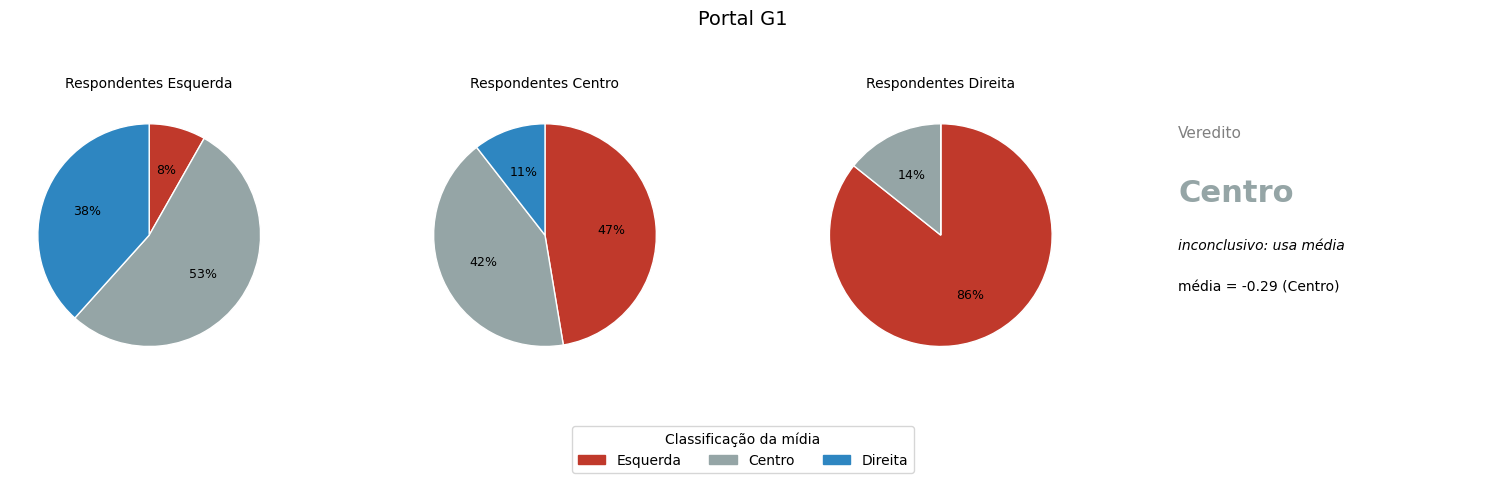

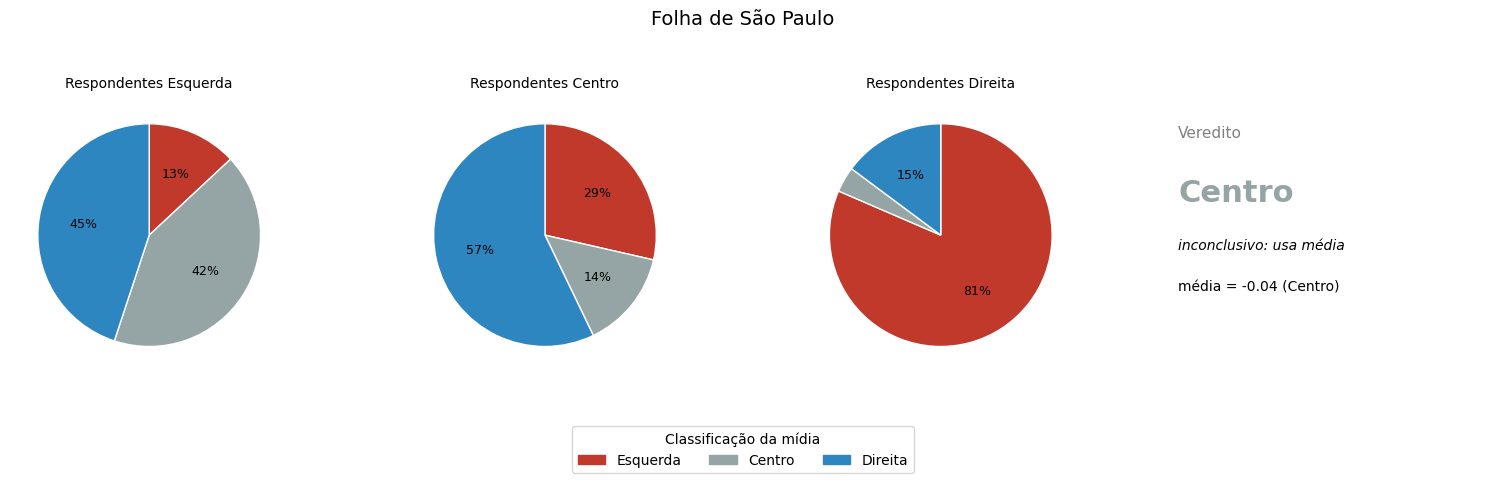

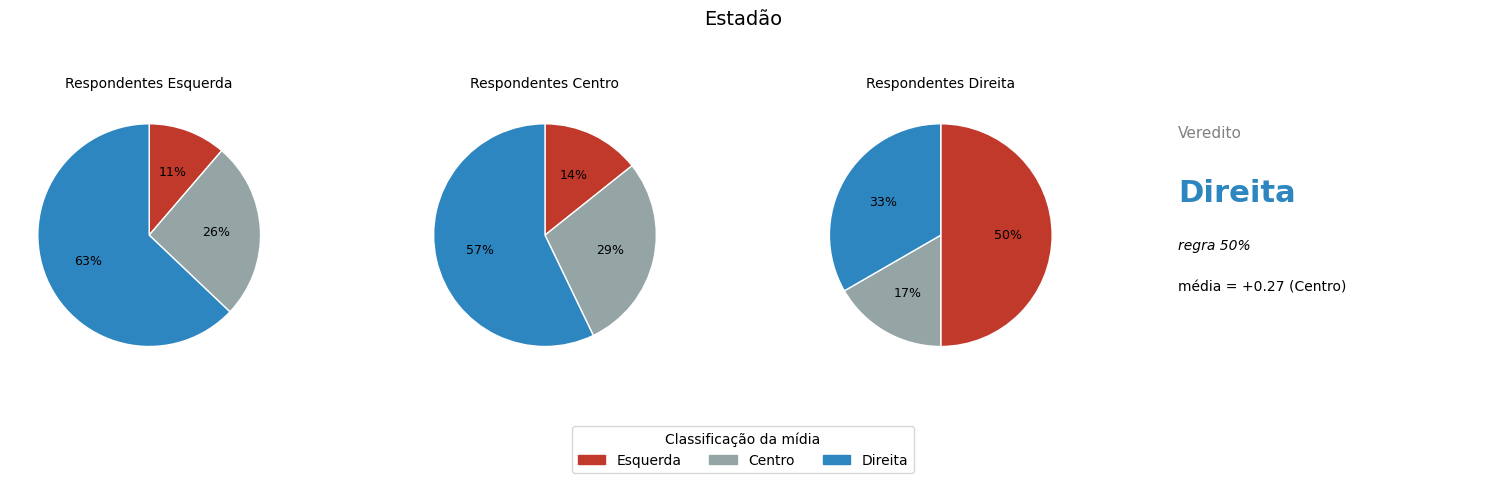

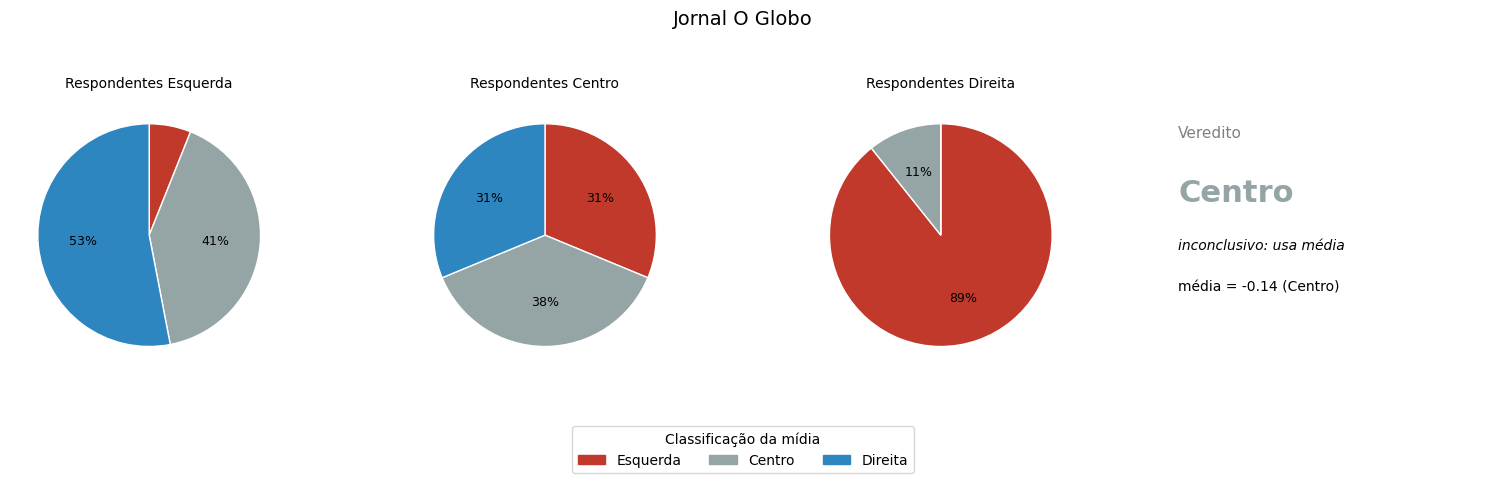

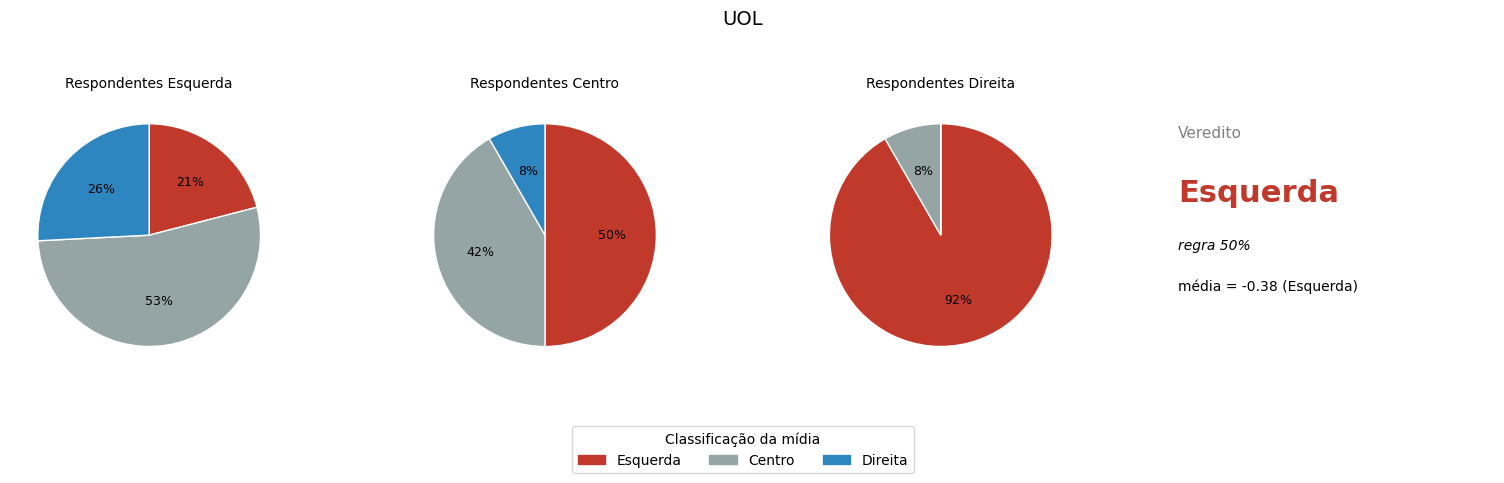

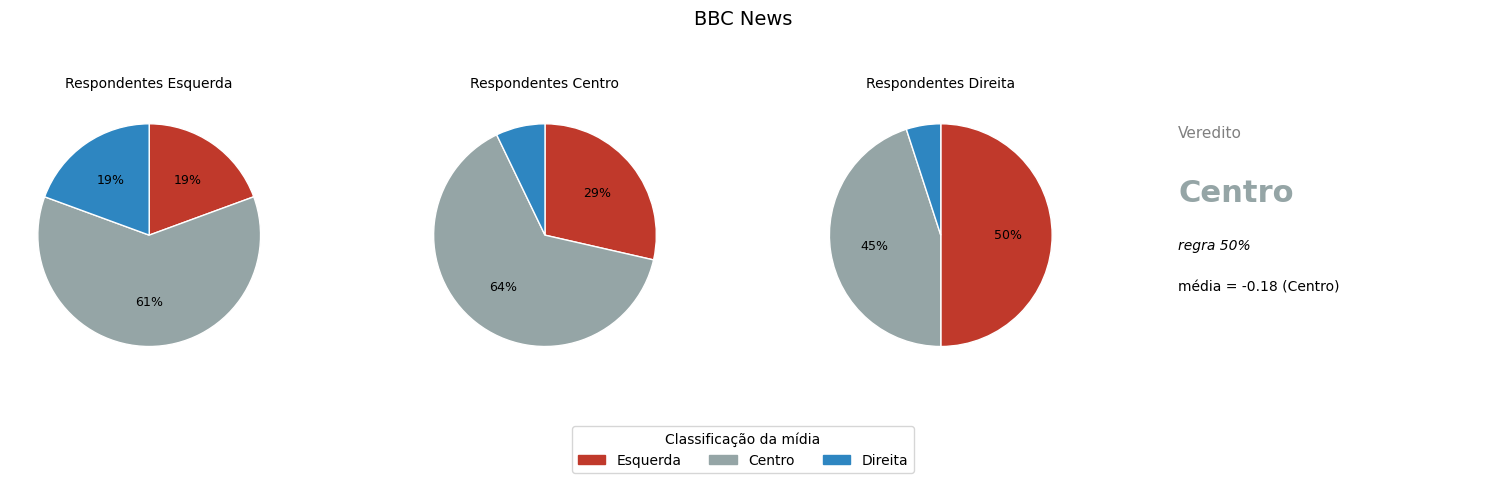

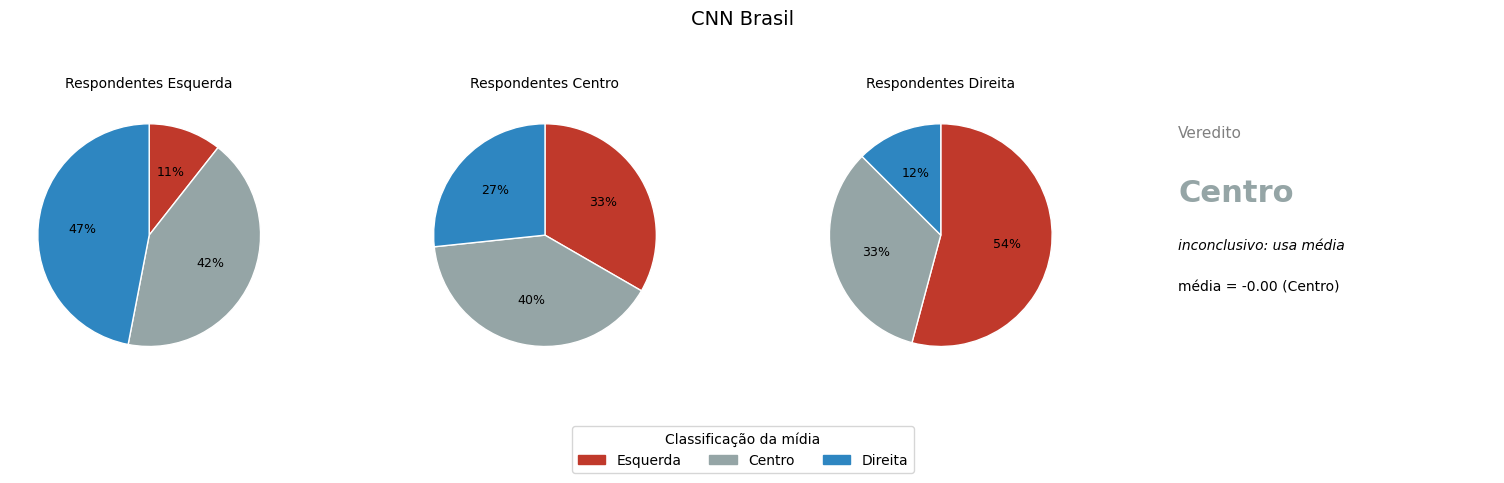

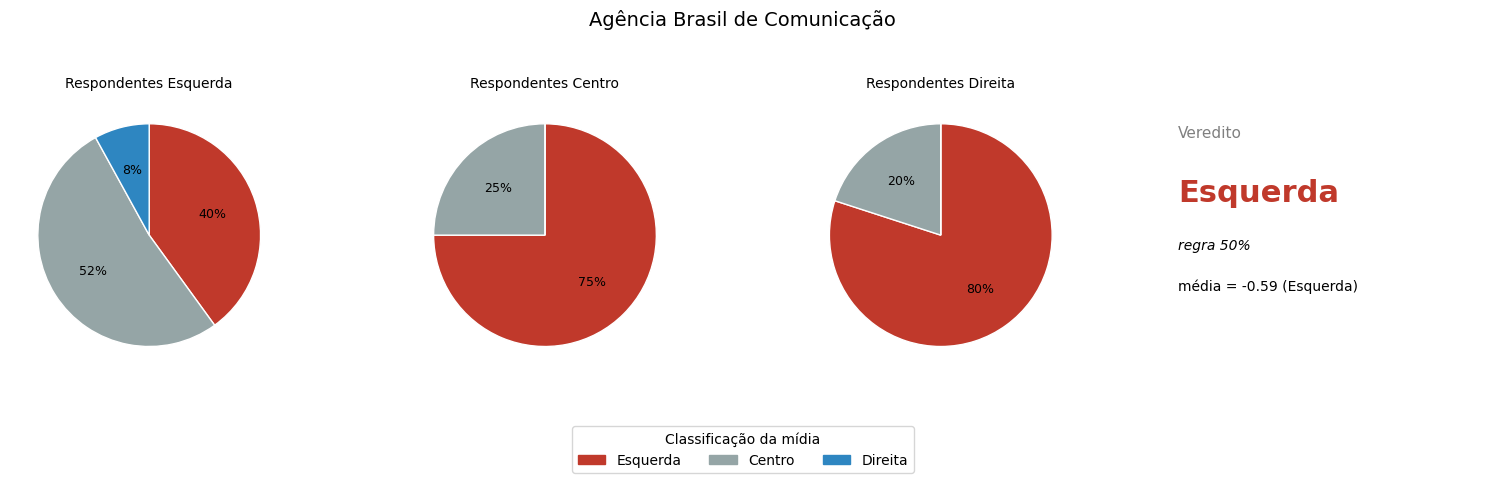

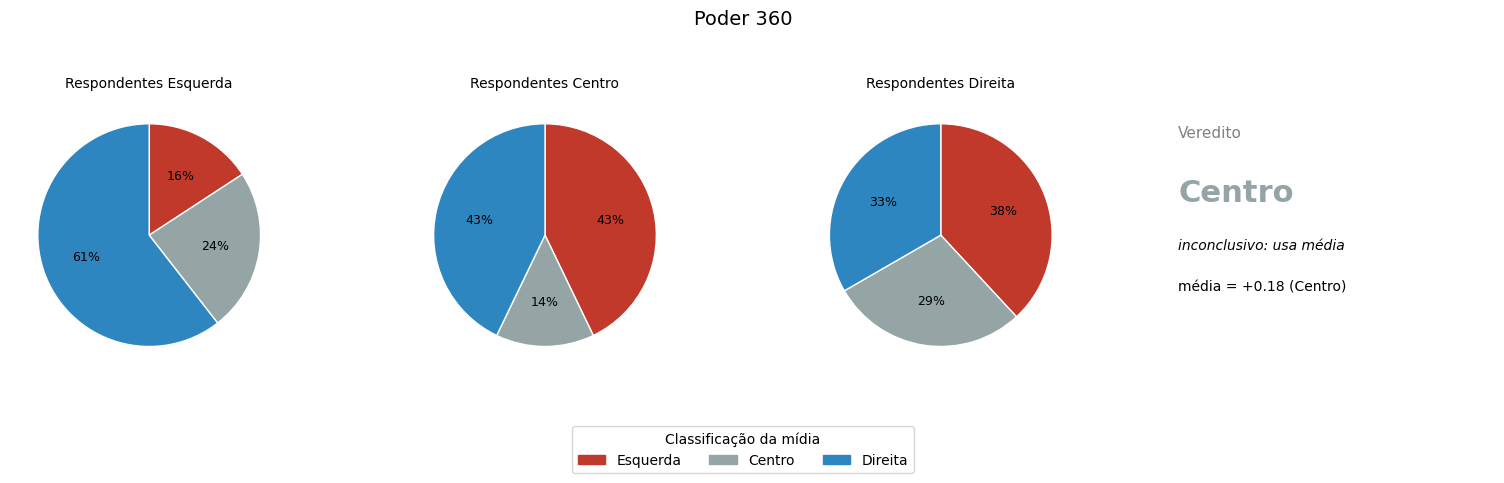

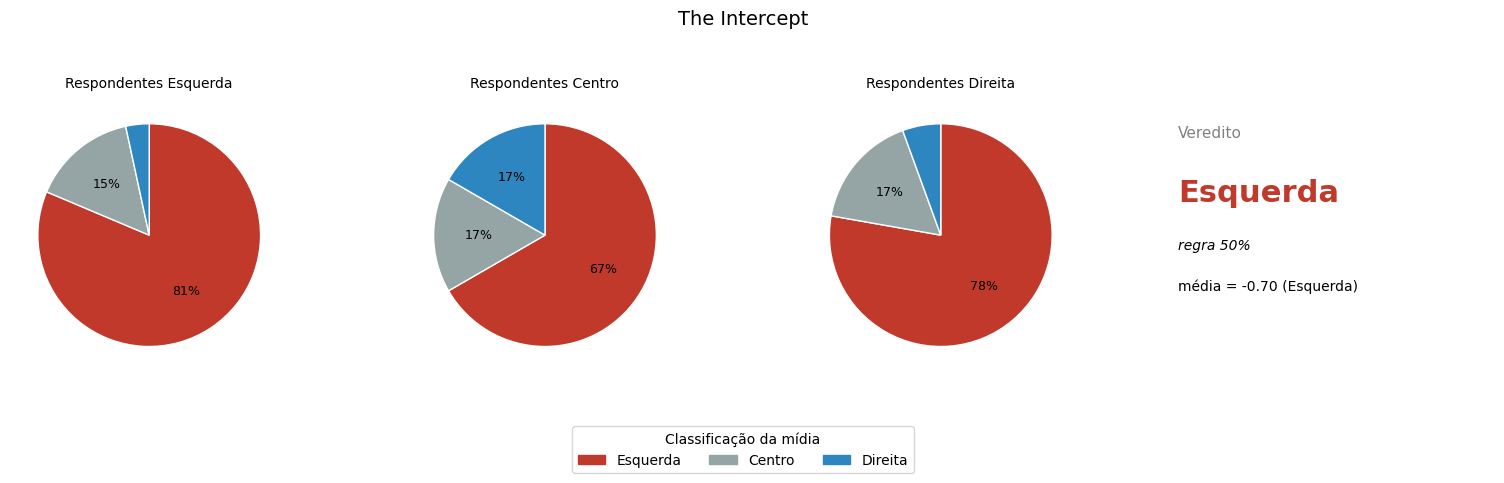

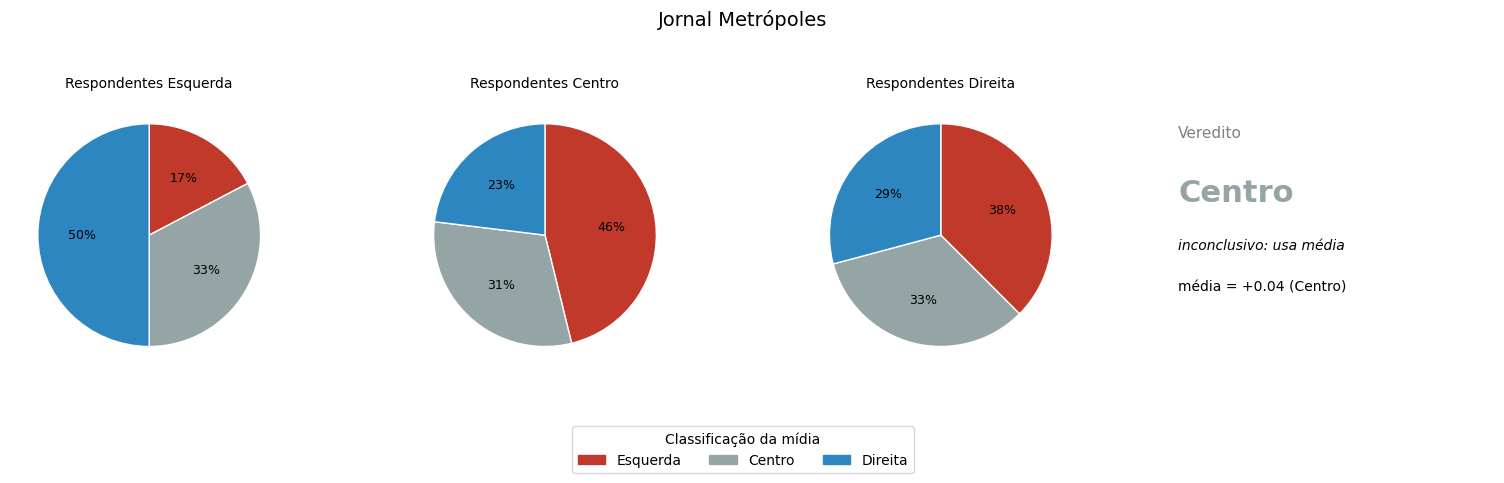

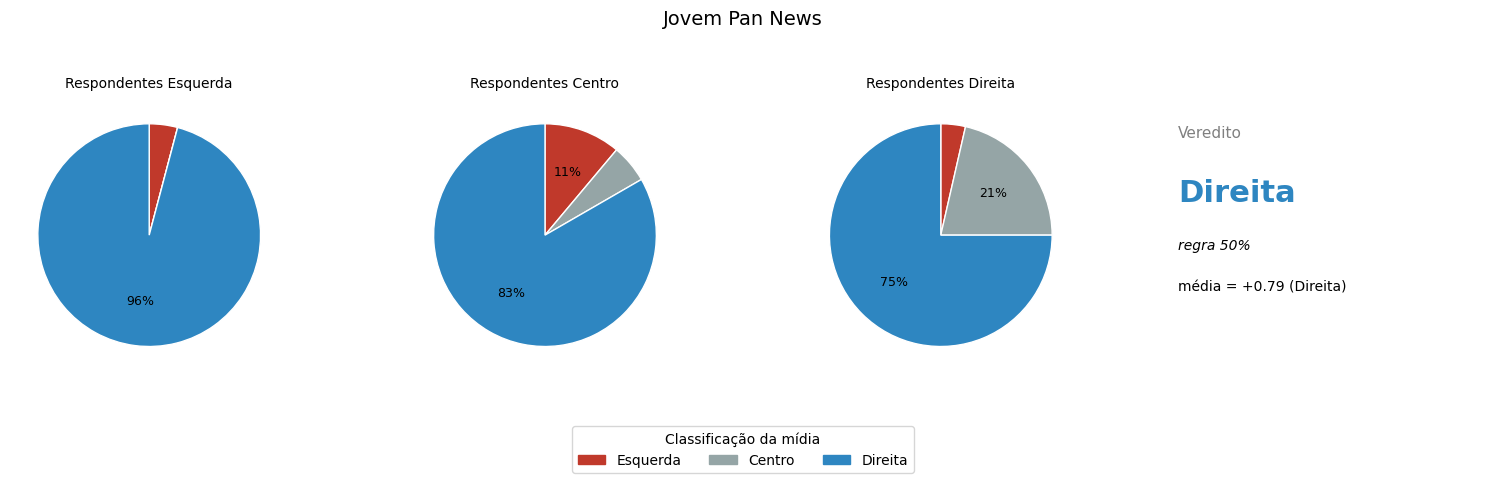

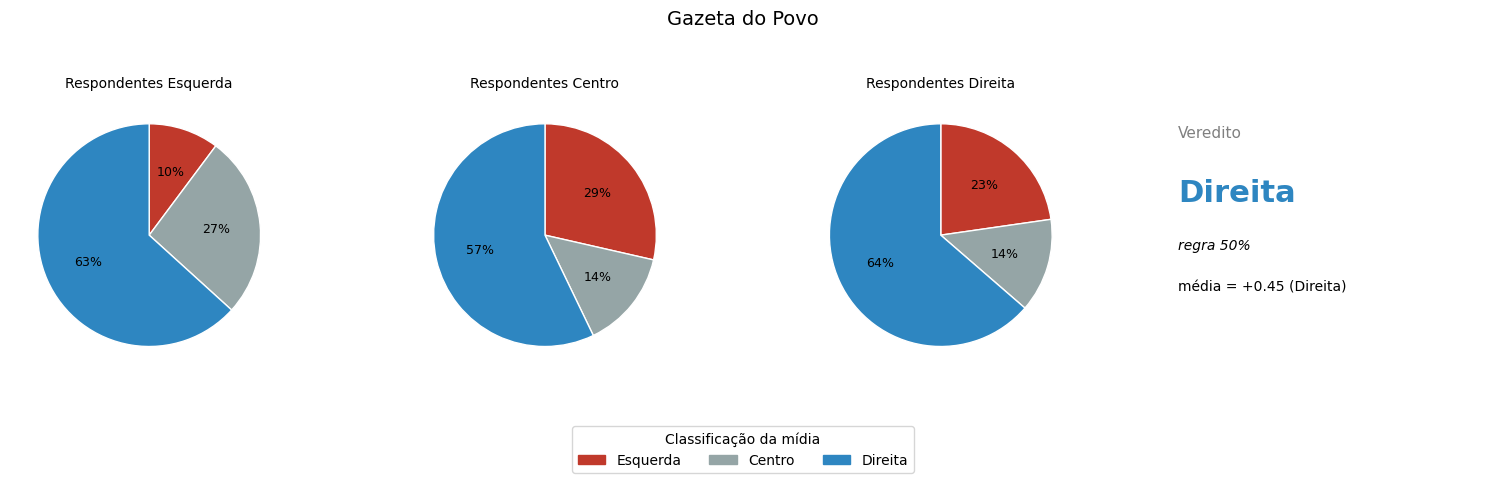

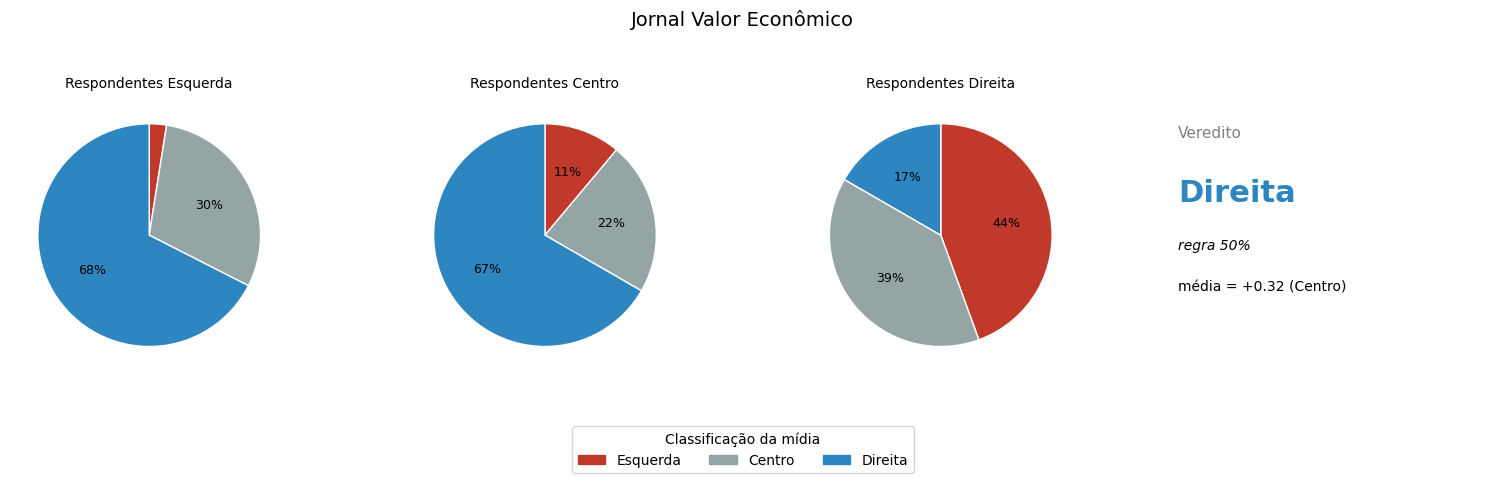

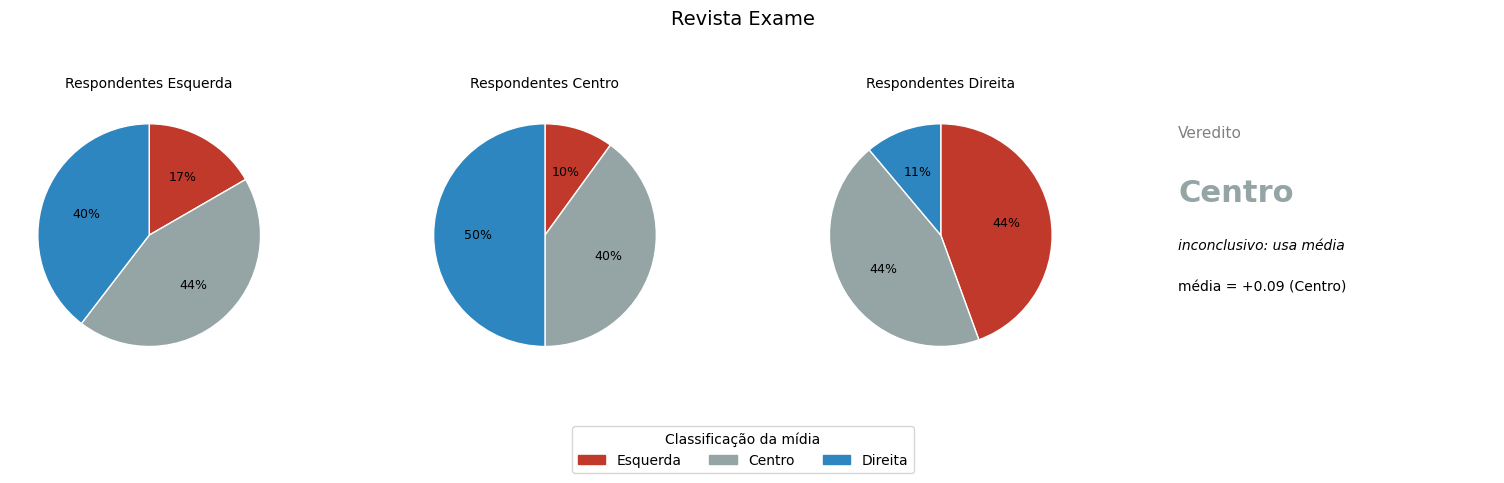

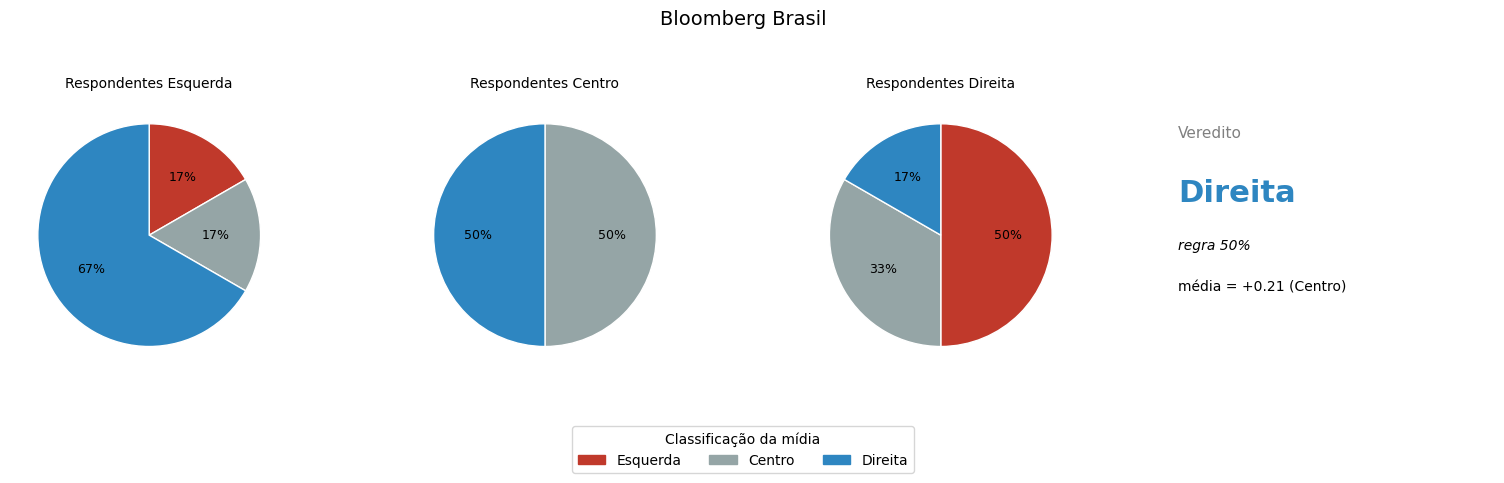

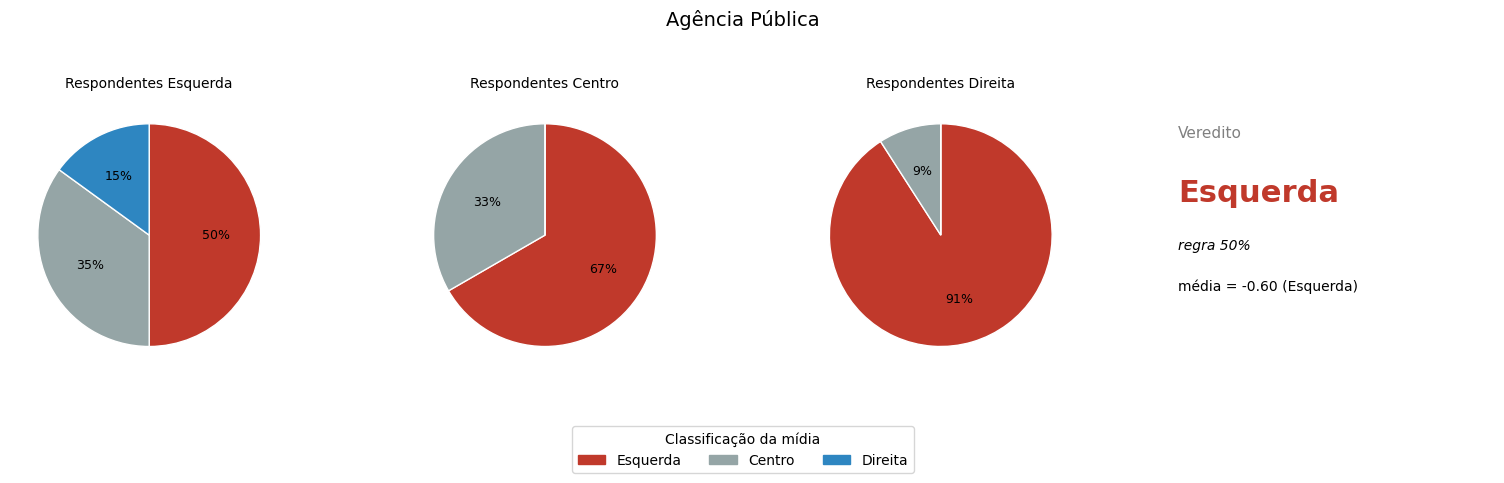

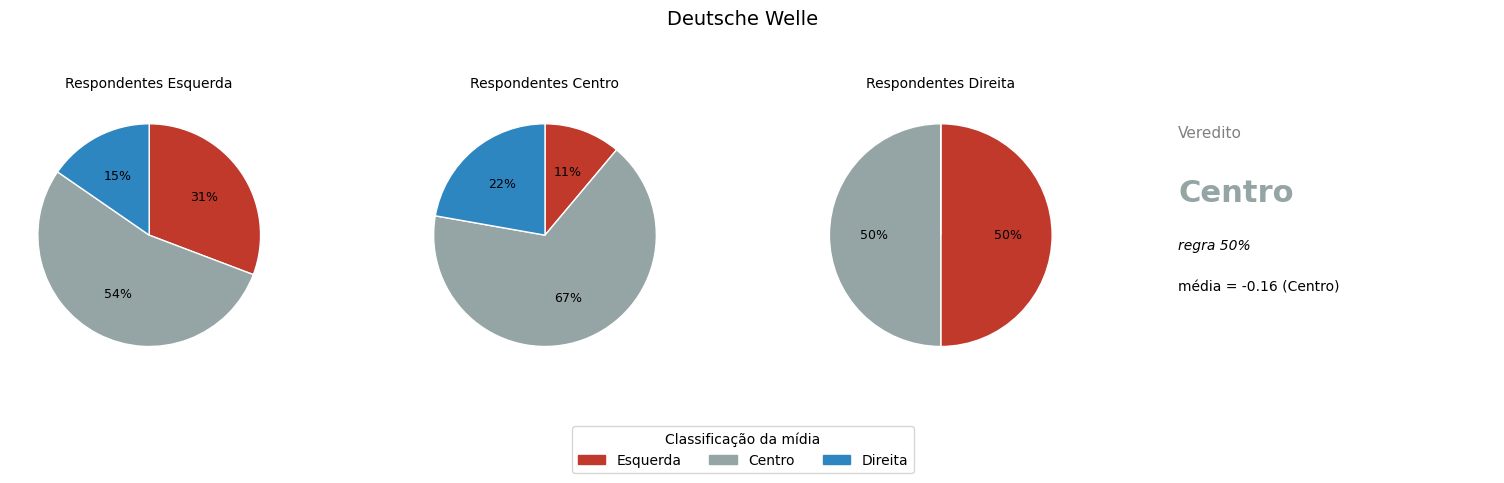

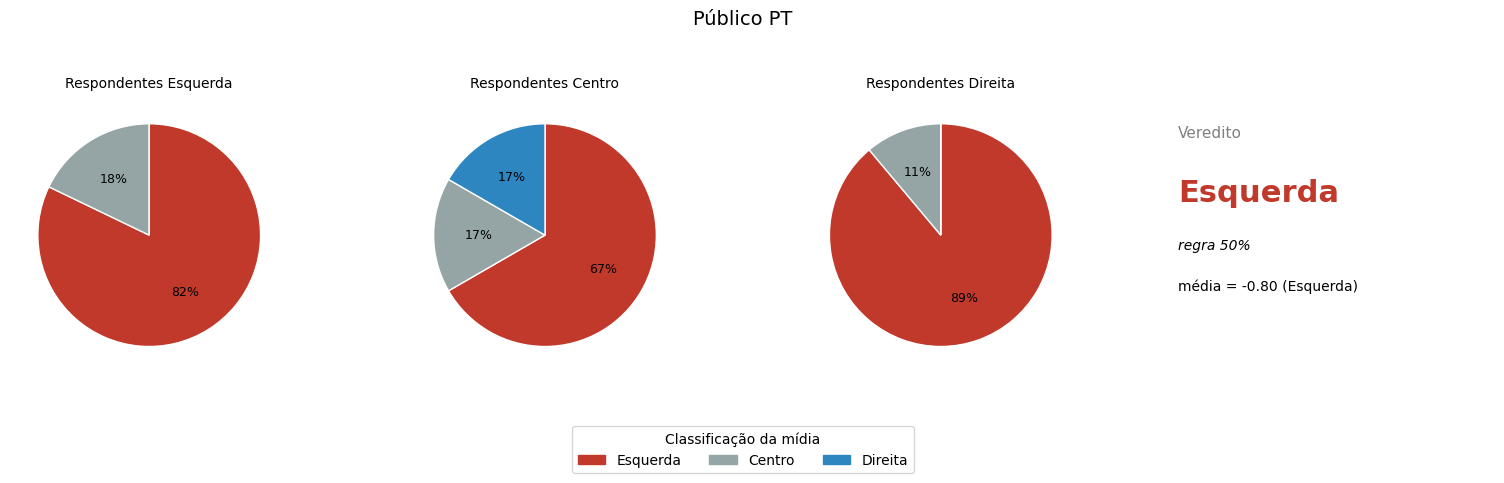

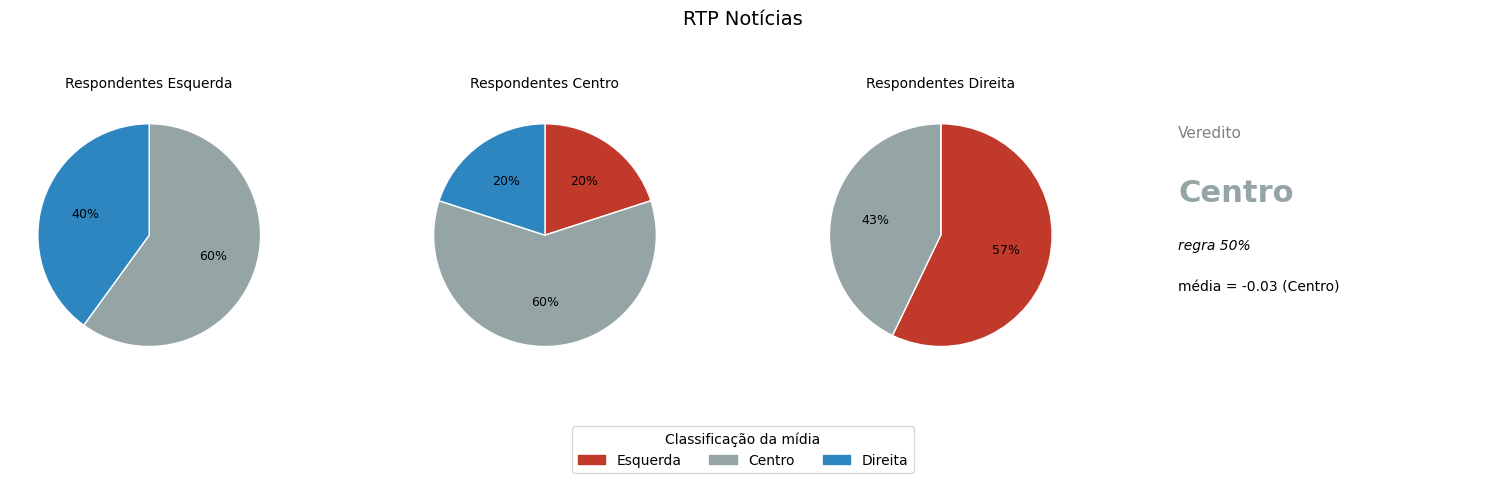

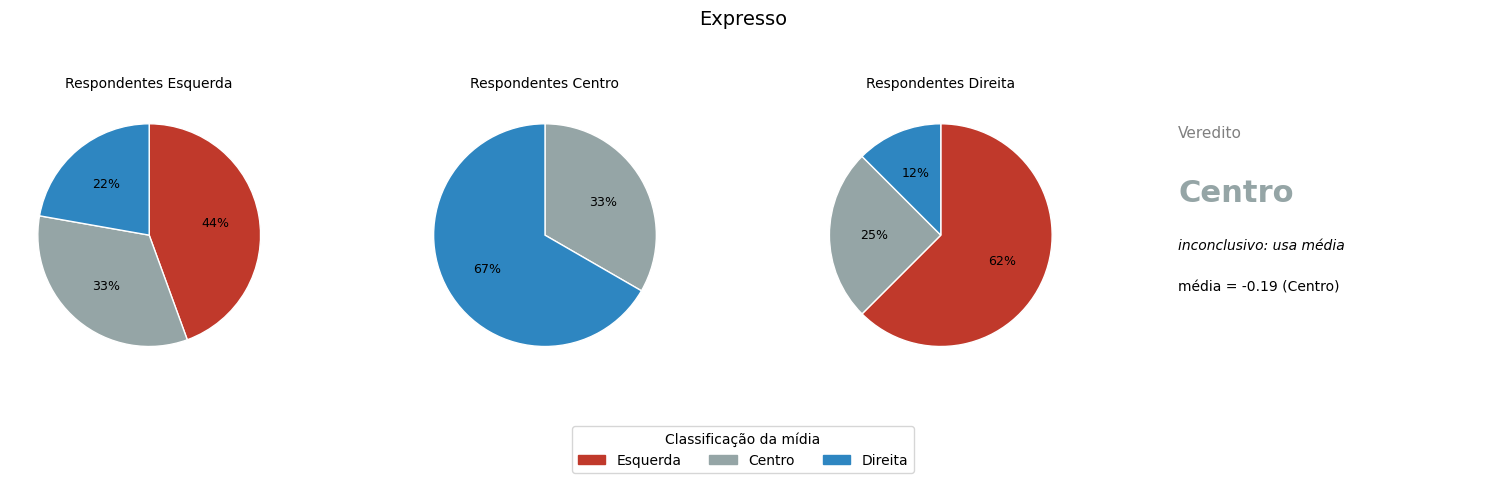

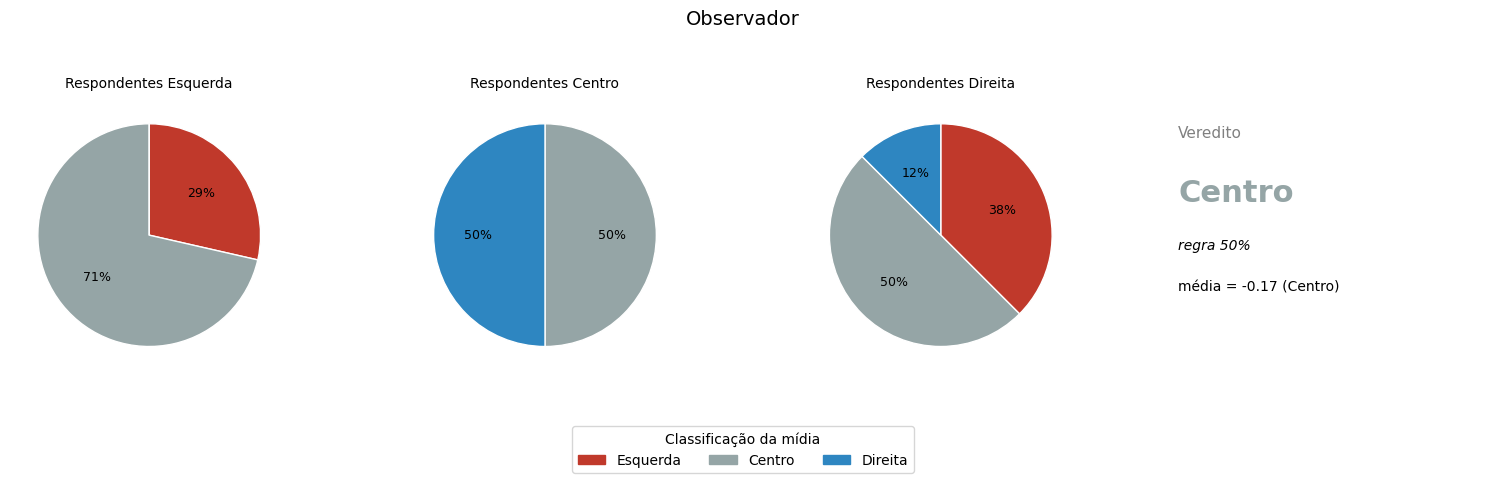

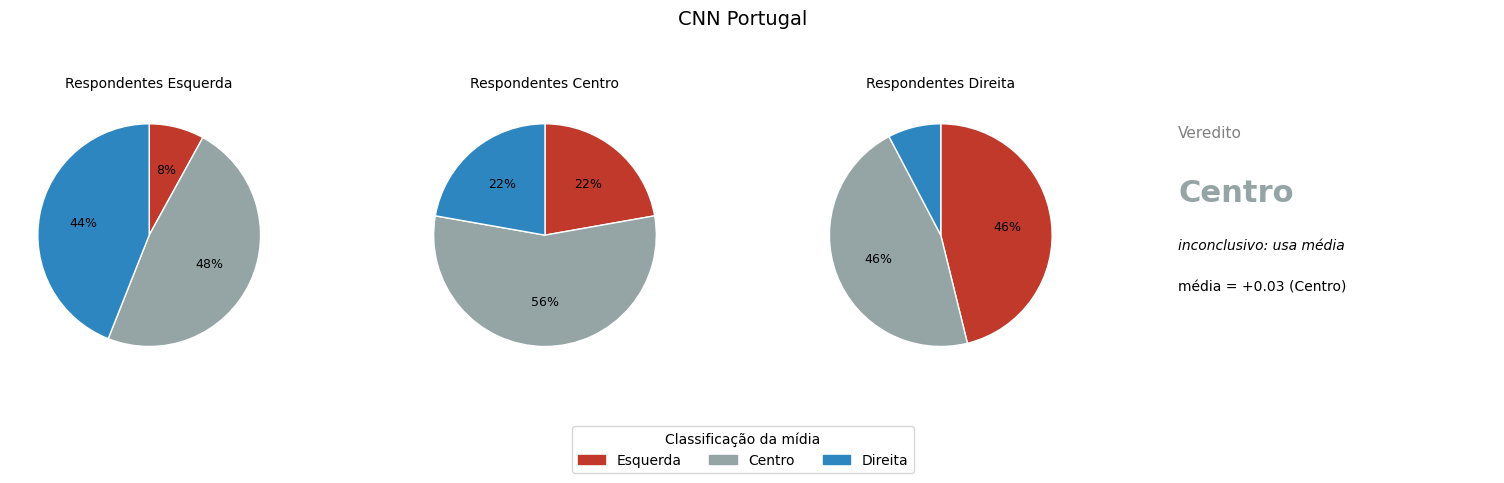

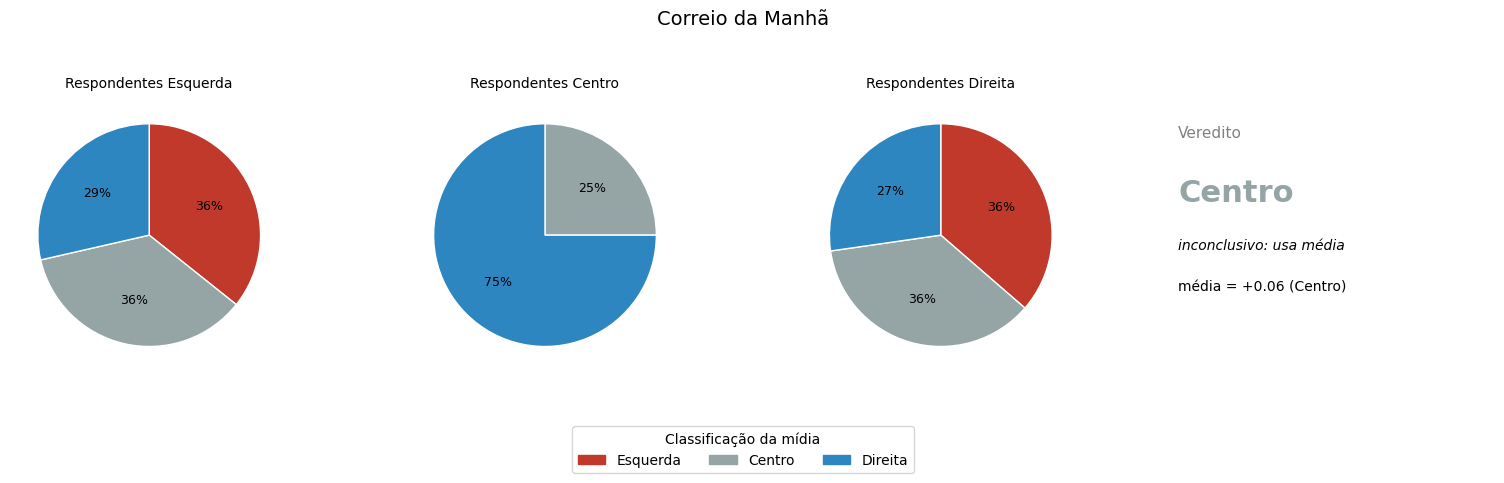

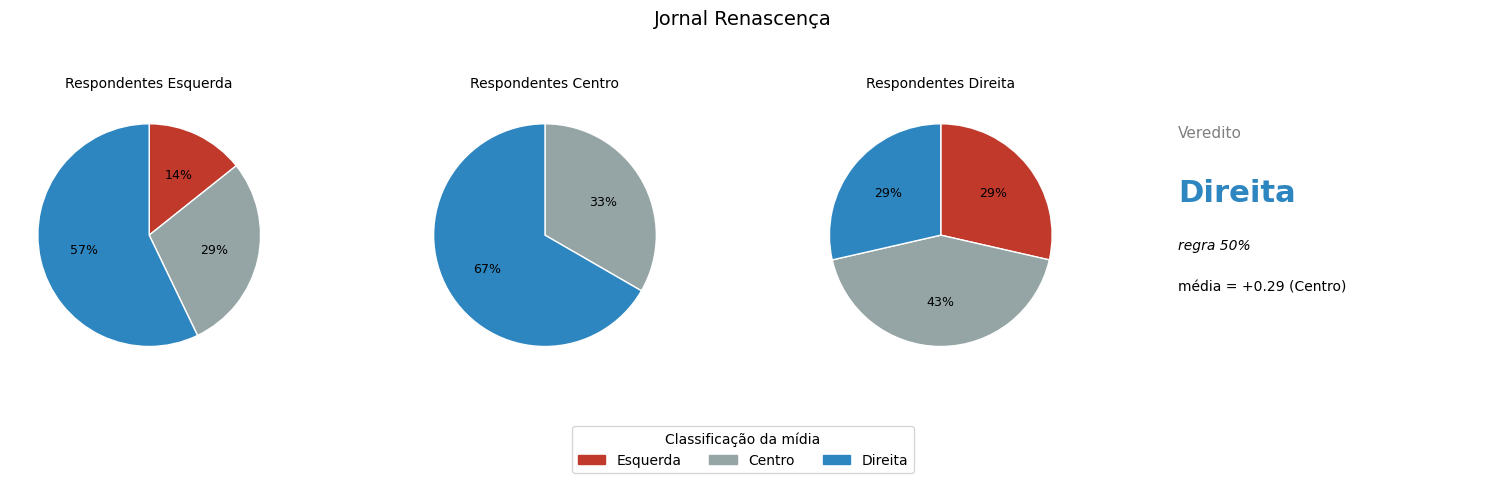

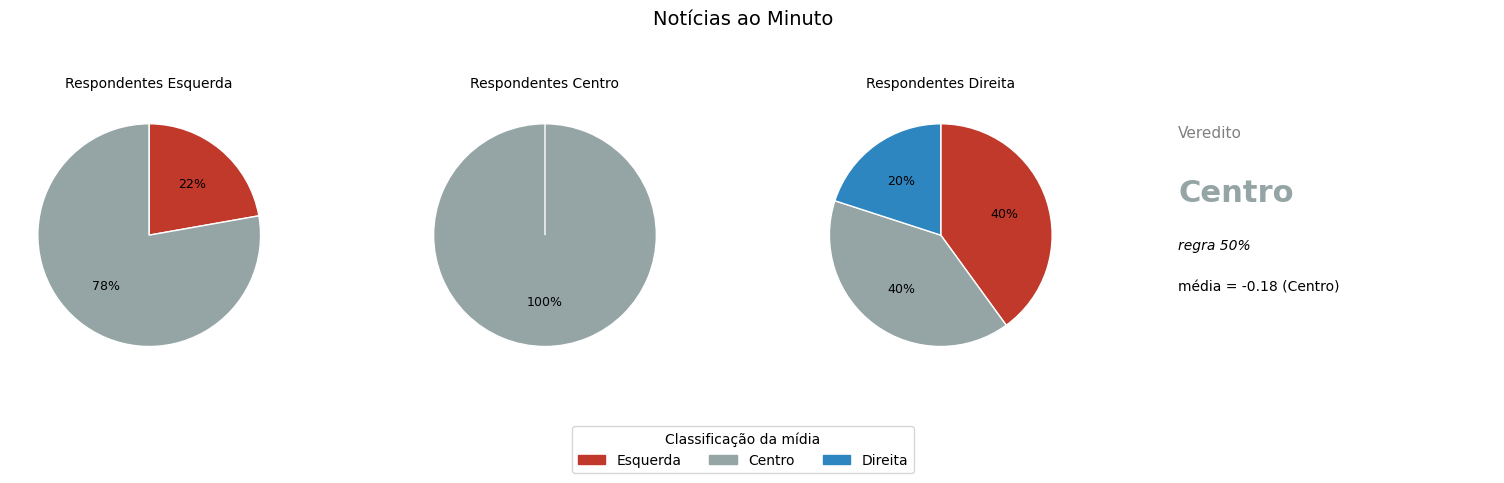

,Veredito,Origem,Média
Portal G1,Centro,inconclusivo: usa média,-0.29
Folha de São Paulo,Centro,inconclusivo: usa média,-0.04
Estadão,Direita,regra 50%,0.27
Jornal O Globo,Centro,inconclusivo: usa média,-0.14
UOL,Esquerda,regra 50%,-0.38
BBC News,Centro,regra 50%,-0.18
CNN Brasil,Centro,inconclusivo: usa média,-0.00
Agência Brasil de Comunicação,Esquerda,regra 50%,-0.59
Poder 360,Centro,inconclusivo: usa média,0.18
The Intercept,Esquerda,regra 50%,-0.70


In [16]:
# -1 ~ -0.333 = Esquerda
# -0.334 ~ 0.333 = Centro
# 0.334 ~ 1 = Direita

# Veredito por midia a partir da media das medias por espectro
LIMIAR = 0.50
spectra = ["Esquerda", "Centro", "Direita"]

def classificar(v):
    if v <= -1/3:
        return "Esquerda"
    if v < 1/3:
        return "Centro"
    return "Direita"

# 1) Regra de limiar: classe com >= limiar em pelo menos 2 espectros
def regra(c):
    fortes = [k for k in spectra if sum(pcts[sp].loc[c, k] >= LIMIAR for sp in spectra) >= 2]
    return fortes[0] if len(fortes) == 1 else None

# 2) media das medias (usada quando a regra eh inconclusiva)
medias = {sp: enq_copy.loc[enquete["Politica"] == sp].mean() for sp in spectra}
avg_media = (medias["Esquerda"] + medias["Centro"] + medias["Direita"]) / 3

veredito = {}
for c in cols:
    r = regra(c)
    veredito[c] = {
        "final": r if r else classificar(avg_media[c]),
        "origem": "regra 50%" if r else "inconclusivo: usa média",
        "media": classificar(avg_media[c]),
        "valor": avg_media[c],
    }

def plot_media_veredito(c):
    # Grafico sugerido por IA
    v = veredito[c]
    fig = plt.figure(figsize=(16, 4.8))
    gs = GridSpec(1, 4, figure=fig, left=0.03, right=0.97, bottom=0.22, top=0.80, wspace=0.25)

    for j, sp in enumerate(spectra):
        ax = fig.add_subplot(gs[0, j])
        vals = pcts[sp].loc[c, spectra]
        n = int((enquete["Politica"] == sp).sum())
        ax.set_title(f"Respondentes {sp}", fontsize=10)
        if vals.sum() == 0:
            ax.text(0.5, 0.5, "sem respostas", ha="center", va="center", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
        else:
            ax.pie(vals, colors=[colors[s] for s in spectra],
                   autopct=lambda p: f"{p:.0f}%" if p >= 8 else "",
                   textprops={"fontsize": 9}, startangle=90, counterclock=False,
                   wedgeprops={"linewidth": 1, "edgecolor": "white"})
            ax.set_aspect("equal")

    ax = fig.add_subplot(gs[0, 3])
    ax.axis("off")
    ax.text(0.0, 0.85, "Veredito", fontsize=11, color="grey", transform=ax.transAxes)
    ax.text(0.0, 0.62, v["final"], fontsize=22, weight="bold", color=colors[v["final"]], transform=ax.transAxes)
    ax.text(0.0, 0.45, v["origem"], fontsize=10, style="italic", transform=ax.transAxes)
    ax.text(0.0, 0.30, f"média = {v['valor']:+.2f} ({v['media']})", fontsize=10, transform=ax.transAxes)

    fig.suptitle(full_names[c], fontsize=14)
    fig.legend(handles=handles, title="Classificação da mídia", loc="lower center",
               ncol=3, bbox_to_anchor=(0.5, 0.0))
    plt.show()

for c in cols:
    plot_media_veredito(c)

# Tabela-resumo
resumo = pd.DataFrame({
    "Veredito": {full_names[c]: v["final"] for c, v in veredito.items()},
    "Origem": {full_names[c]: v["origem"] for c, v in veredito.items()},
    "Média": {full_names[c]: round(v["valor"], 2) for c, v in veredito.items()},
})
resumo


---
# 5. Robustez e intervalos de confiança

Teste de permutação (qui-quadrado sobre grupo político × avaliação) por mídia, com IC 95% de Wilson para a proporção de avaliações "Direita" em cada grupo, e correção de Holm para as 26 comparações. Rodado duas vezes: com a reclassificação manual (A) e só com autodeclarados (B).

In [17]:
# ---- Robustez e intervalos de confianca ----
# Teste de permutacao (qui-quadrado 3x3: grupo politico x avaliacao), IC de Wilson (95%) e correcao de Holm.
RATINGS = ["Esquerda", "Centro", "Direita"]
Z = 1.96

def wilson(k, n):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    d = 1 + Z**2 / n
    c = (p + Z**2 / (2 * n)) / d
    h = Z * np.sqrt(p * (1 - p) / n + Z**2 / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

def chi2_stat(counts):
    row = counts.sum(1, keepdims=True)
    col = counts.sum(0, keepdims=True)
    tot = counts.sum()
    if tot == 0:
        return 0.0
    E = row @ col / tot
    m = E > 0
    return ((counts - E)[m] ** 2 / E[m]).sum()

def perm_p(g, r, rng, n_perm=5000):
    table = lambda gg: np.bincount(gg * 3 + r, minlength=9).reshape(3, 3).astype(float)
    obs = chi2_stat(table(g))
    hits = sum(chi2_stat(table(rng.permutation(g))) >= obs - 1e-12 for _ in range(n_perm))
    return (hits + 1) / (n_perm + 1)

def holm(p):
    p = np.asarray(p, dtype=float)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def analyse(df, n_perm=5000, seed=0):
    rng = np.random.default_rng(seed)
    gmap = {k: i for i, k in enumerate(GROUPS)}
    rmap = {k: i for i, k in enumerate(RATINGS)}
    rows = []
    for c in cols:
        sub = df[df[c].isin(RATINGS) & df["Politica"].isin(GROUPS)]
        g = sub["Politica"].map(gmap).to_numpy()
        r = sub[c].map(rmap).to_numpy()
        row = {"media": c, "n": len(sub)}
        for gi, gname in enumerate(GROUPS):
            mask = g == gi
            n_g = int(mask.sum())
            k_dir = int((r[mask] == rmap["Direita"]).sum())
            lo, hi = wilson(k_dir, n_g)
            row[f"n_{gname[:3]}"] = n_g
            row[f"Dir%_{gname[:3]}"] = round(100 * k_dir / n_g) if n_g else np.nan
            row[f"IC95_{gname[:3]}"] = f"{100*lo:.0f}-{100*hi:.0f}" if n_g else ""
        row["p"] = perm_p(g, r, rng, n_perm) if len(set(g)) > 1 else np.nan
        rows.append(row)
    out = pd.DataFrame(rows)
    ok = out["p"].notna()
    out.loc[ok, "p_holm"] = holm(out.loc[ok, "p"].to_numpy())
    return out

GROUPS = ["Esquerda", "Centro", "Direita"]
MANUAL_IDX = [22, 27, 41, 44, 62, 63, 95, 100, 114, 127]

# A: com a reclassificação manual (como o notebook usa hoje)
res_manual = analyse(enquete.dropna(subset=["Politica"]))
# B: só autodeclarados (sem as 10 linhas reclassificadas à mão)
res_declared = analyse(enquete.drop(index=MANUAL_IDX).dropna(subset=["Politica"]))

print("Respondentes portugueses:", int((enquete["Regiao"] == "Portugal").sum()))
print("\n== A: com reclassificação manual ==")
print(res_manual.to_string(index=False))
print("\n== B: só autodeclarados ==")
print(res_declared.to_string(index=False))

sig_a = set(res_manual.loc[res_manual.p_holm < 0.05, "media"])
sig_b = set(res_declared.loc[res_declared.p_holm < 0.05, "media"])
print("\nSignificativos (Holm < 0.05) em A:", sorted(sig_a) or "nenhum")
print("Significativos (Holm < 0.05) em B:", sorted(sig_b) or "nenhum")
print("Mudam de status entre A e B:", sorted(sig_a ^ sig_b) or "nenhum")


Respondentes portugueses: 8

== A: com reclassificação manual ==
     media   n  n_Esq  Dir%_Esq IC95_Esq  n_Cen  Dir%_Cen IC95_Cen  n_Dir  Dir%_Dir IC95_Dir        p   p_holm
        G1 120     73        38    28-50     19        11     3-31     28         0     0-12 0.000200 0.005199
     Folha 110     69        45    34-57     14        57    33-79     27        15     6-32 0.000200 0.005199
   Estadao 100     62        63    50-74     14        57    33-79     24        33    18-53 0.001600 0.031994
    Oglobo 110     66        53    41-65     16        31    14-56     28         0     0-12 0.000200 0.005199
       UOL  98     62        26    17-38     12         8     1-35     24         0     0-14 0.000200 0.005199
       BBC 101     67        19    12-30     14         7     1-31     20         5     1-24 0.061388 0.859428
    CNN BR 105     66        47    35-59     15        27    11-52     24        12     4-31 0.000800 0.016797
       EBC  48     25         8     2-25      8